# Summary and interpretation of saved modelling runs

Choose **one or several folders** below: a collection of runs, a single run, or an individual `optimization/SEED/runhistory.json`. The notebook reads saved histories directly, including runs without a final `trials.csv`.

It summarises coverage and execution failures, identifies best final-stage models, displays individual observation contributions, compares competitive parameter families and physical structures, and inspects saved predictions. A common pool of fully scored models supports analysis of adding or removing observation groups.

**Scientific interpretation:** the returned SMAC cost combines reduced chi-square and empirical image losses; it is not a joint reduced chi-square or a posterior probability. Unscored observables remain missing. Adaptive optimisation samples and their ranges are not posterior distributions or credible intervals. The notebook never launches MCFOST, changes weights, modifies observations, or rescales recorded costs.

In [31]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from IPython.display import display, Markdown

# Locate the helper when starting Jupyter from the notebook, repository or workspace.
_candidates = [Path.cwd()]
for _base in [Path.cwd(), *Path.cwd().parents]:
    _candidates.extend([_base / 'scripts/post-processing',
                        _base / 'modelling_optimisation/scripts/post-processing'])
NOTEBOOK_DIR = next((p for p in _candidates if (p / 'run_summary_utils.py').is_file()), None)
if NOTEBOOK_DIR is None:
    raise FileNotFoundError('Open this notebook from the repository or keep run_summary_utils.py beside it.')
sys.path.insert(0, str(NOTEBOOK_DIR))
from run_summary_utils import (
    competitive_comparison, threshold_sensitivity, plot_parameter_distributions,
    plot_threshold_sensitivity,
    SCORE_COLUMNS, SUBSETS, INTERFEROMETRY, PDI, load_runs, coverage_table,
    select_solutions, parameter_summary, stage_correlations, common_pool_comparison,
    prediction_tables, resolve_model_files, plot_costs, plot_convergence,
    plot_parameters, plot_amplitudes, plot_saved_profiles, plot_tradeoffs,
    parameter_pair_analysis, select_parameter_pairs, plot_selected_parameter_pairs,
    correlation_strength, correlation_metric, plot_parameter_correlation_heatmap,
)
# Inferred workspace above the repository; used to construct the default RUN_FOLDERS paths.
WORKSPACE_ROOT = NOTEBOOK_DIR.parents[2]
# Notebook table display width only; CSV exports retain all columns.
pd.set_option('display.max_columns', 25)
# Inline figure resolution and default grid visibility; saved PNGs use the export cell DPI.
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
print('Python:', sys.executable)

Python: /home/kandrych/venvs/obriy311/bin/python


## 1. Select folders and analysis options

Labels identify independent collections. Discovery is bounded to four levels of subfolders and skips the large trial-output trees. Overlapping inputs are deduplicated. Every optimiser seed remains a separate history.

Competitive models satisfy `cost <= best + max(ABSOLUTE_COST_ALLOWANCE, abs(best) * RELATIVE_COST_ALLOWANCE)` within each history and final-stage objective. This descriptive threshold does not imply a statistical confidence level.

In [32]:
# Input collections: map a readable label to a parent folder, single run, seed folder, or runhistory.json.
# Uncomment/add entries to compare collections. Overlapping histories are loaded once; seeds stay separate.
RUN_FOLDERS = { 
    'sed': WORKSPACE_ROOT / 'smac/1_tapered_2zones_dubrulle/lower_precision/seed1',
    #'Dubrulle': WORKSPACE_ROOT / 'smac/1_akke_2zones_wider_tapered/dubrulle',
    #'Fromang': WORKSPACE_ROOT / 'smac/1_akke_2zones_wider_tapered/fromang',
    # 'Earlier tapered': WORKSPACE_ROOT / 'smac/1_tapered_2zones_dubrulle',
    # 'Single run': WORKSPACE_ROOT / 'smac/1_akke_2zones_wider_tapered/dubrulle/sed_alma',
}
# Exclude recorded costs >= this value, including execution penalties such as 1e99.
# Success status, finite cost and absence of recorded failure are also required.
PENALTY_LIMIT = 1e90
# Fractional competitive-cost allowance above the best recorded cost: 0.10 = 10%; 1.0 = 100%.
# Threshold = best + max(abs(best) * this allowance, ABSOLUTE_COST_ALLOWANCE).
RELATIVE_COST_ALLOWANCE = 0.5
# Alternative competitive allowance in composite-objective units (not a percentage).
# The larger of the relative and absolute allowances is used; they are not added.
ABSOLUTE_COST_ALLOWANCE = 0.0

# None includes every independently sampled parameter in the saved ConfigSpaces.
# Supply a list, e.g. ['disk_total_dust_mass', 'disk_Rmid'], to focus the plots.
# Parameter names for comparison plots and selected parameter tables; None infers all fitted names.
# Pair screening still audits all independently varied parameters regardless of this list.
PARAMETERS = None
# Use logarithmic parameter axes for these names when all plotted values are positive.
# This changes display coordinates only
LOG_PARAMETERS = {'disk_total_dust_mass', 'alpha_viscosity', 'zone_1_species_1_amax'}
# Quantitative within-history pair screening (descriptive thresholds, not significance tests).
# Sample used for correlation heatmaps and pair selection: all_final = all usable final-stage models;
# competitive = only models passing the competitive-cost threshold. Both coefficients are tabulated.
PAIR_SCOPE = 'competitive'  # 'competitive' or 'all_final'; both correlations are always reported.
# Rank-correlation metrics to display for every run; both are calculated on the same finite model pairs.
# Scatter panels keep the existing Spearman selection so the two metrics use identical axes and samples.
PAIR_METRICS = ('spearman', 'kendall_tau_b')
# Minimum number of distinct configurations with finite values on both axes for an eligible pair.
# Applied separately within each history/objective and sample scope; smaller samples appear as NA.
PAIR_MIN_MODELS = 20
# Minimum number of distinct numeric values required on EACH parameter axis.
# Constant or sparsely sampled axes fail this screen even if many models were evaluated.
PAIR_MIN_UNIQUE_VALUES = 3
# Minimum absolute Spearman coefficient for selecting association scatter plots (range 0 to 1).
# Heatmaps show every eligible coefficient. Lower to 0.2 to include weak pairs in scatter plots.
# Spearman selects the shared panels; Kendall Tau-b is shown for those same parameter pairs.
PAIR_MIN_ABS_RHO=0.5
# Maximum number of strongest eligible association pairs considered for plotting (positive integer).
# This is a global cap applied before the per-history and per-figure limits.
PAIR_MAX_PLOTS = 60
# Maximum strongest eligible association pairs plotted for EACH history/objective (positive integer).
# There is no shared cap across modelling runs; this limit is applied after correlation screening.
PAIR_MAX_PER_HISTORY = 60
# Maximum scatter panels on one figure page (positive integer).
# Larger per-run selections continue on additional pages belonging to the same run.
PAIR_PANELS_PER_FIGURE = 6  # Paginate large selections within each run.
# Parameters with circular/periodic coordinates, excluded from both ordinary rank-correlation calculations.
# They are marked NA in heatmaps; this notebook does not compute circular correlations.
PAIR_PERIODIC_PARAMETERS = {}
# True allows automatic scatter selection of pairs directly linked by ConfigSpace inequalities.
# Heatmaps always mark such pairs with a dagger/purple outline; imposed links can induce correlation.
PAIR_INCLUDE_CONSTRAINED = False
# Optional exact history labels to include in plots; None shows every history.
# Optional list of exact inventory history labels to include in plots and parameter-pair analysis.
# None includes all histories. Summary tables and common-pool calculations still use all loaded runs.
PLOT_HISTORIES = None
# Maximum number of plotted best-model rows used in saved PDI/ALMA radial-profile overlays.
# Uses their existing order; this does not limit other best-model or physical-structure plots.
PROFILE_MAX_MODELS = 6
# True displays original saved SED, visibility, PDI and ALMA diagnostic PNGs in the gallery.
# Reads existing images only; it does not recompute observables or launch MCFOST.
SHOW_SAVED_DIAGNOSTICS = True
# Maximum matched best models shown when the diagnostic gallery is enabled.
# Display priority is most scored observation groups, then lowest cost; this is not a joint ranking.
GALLERY_MAX_MODELS = 2
# Set this to one of the printed pool_group values when multiple compatible pools exist.
# Compatibility-group ID to inspect in the common-model-pool analysis (use a printed pool_group).
# None chooses the group with the largest number of saved compatible evaluations.
POOL_GROUP = None
# Ordered subset objectives used to quantify adding observations on the SAME saved model pool.
# Names must occur in SUBSETS; each step must retain all score terms from the previous step.
# No new simulations or reweighting are performed.
OBSERVATION_SEQUENCE = ['SED', 'SED+interferometry', 'All']

# True writes analysis CSV tables, PNG figures and JSON settings into OUTPUT_DIR.
# False keeps results in notebook memory; simulations and raw observations are never modified.
SAVE_OUTPUTS = False
if SAVE_OUTPUTS:
    if len(RUN_FOLDERS)>1:
        # Export destination: this branch derives it from the first selected input folder.
        # Set an explicit writable folder here if using a runhistory.json file as input.
        # It is created only when SAVE_OUTPUTS=True; exports replace existing files with the same names.
        OUTPUT_DIR = list(RUN_FOLDERS.values())[0].resolve().parent / 'run_summary_outputs'
    else:
        # Export destination: this branch derives it from the first selected input folder.
        # Set an explicit writable folder here if using a runhistory.json file as input.
        # It is created only when SAVE_OUTPUTS=True; exports replace existing files with the same names.
        OUTPUT_DIR = list(RUN_FOLDERS.values())[0] / 'run_summary_outputs'

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Internal figure registry used for previews and optional PNG exports; leave this empty initially.
figures = {}
# Internal display helper: retain a figure for export, display it, then close its live window.
def show_figure(name, figure):
    if figure is not None:
        figures[name] = figure
        display(figure)
        plt.close(figure)

# Compare nested competitive sets at these relative allowances, holding the absolute allowance fixed.
# The current RELATIVE_COST_ALLOWANCE is included automatically.
COMPARISON_RELATIVE_ALLOWANCES = [0.1, 0.25, 0.50, 1.0, 2.0]
# Maximum pairs per history/objective selected by largest change in either rank coefficient.
COMPARISON_MAX_PAIRS = 6
# Parameter ECDFs per figure; all requested numeric parameters are paginated.
COMPARISON_PARAMETERS_PER_FIGURE = 6


## 2. Inventory, provenance and usable evaluations

A usable evaluation must have success status, a finite cost below the penalty threshold, a configuration, and no recorded failure. This excludes execution failures returned as `1e99` even when SMAC labels them successful.

The inventory records saved scenario seeds, the current physical template and ConfigSpace fingerprints, photon settings and stage manifests. Templates and launch scripts are current files, not immutable historical snapshots; identical hashes do not prove that historical observations and code were identical. The saved per-trial PDI correction flags are stronger evidence than the current launch script.

`evaluation_wall_hours` is the sum of recorded trial durations, not elapsed time or CPU-core hours.

In [33]:
evaluations, inventory, records, configspaces = load_runs(RUN_FOLDERS, PENALTY_LIMIT)
coverage = coverage_table(evaluations)
if PARAMETERS is None:
    PARAMETERS = sorted({p['name'] for space in configspaces.values()
                         for p in space.get('hyperparameters', []) if p.get('type') != 'constant'})
    if not PARAMETERS:
        PARAMETERS = [c.removeprefix('param__') for c in evaluations if c.startswith('param__')
                      and pd.to_numeric(evaluations[c], errors='coerce').nunique() > 1]
display(inventory[['history', 'configured_max_budget', 'recorded_trials', 'requested_trials',
                   'launch_requests_correction', 'photon_settings']])
display(coverage)
display(inventory[['history', 'configspace_hash', 'template_hash', 'history_sha256']])
print(f'{len(inventory)} histories; {len(evaluations):,} recorded evaluations; '
      f'{evaluations.usable.sum():,} usable evaluations.')
exclusions = evaluations.loc[~evaluations.usable].groupby(['history', 'exclusion']).size().rename('count').reset_index()
display(exclusions)
# Separate real execution failures from observationally poor models.
failure_examples = evaluations.loc[evaluations.failure_reason.ne(''), ['history', 'config_id', 'budget', 'failure_reason']]
display(failure_examples.head(12))


,history,configured_max_budget,recorded_trials,requested_trials,launch_requests_correction,photon_settings
0,sed/sed [seed 193544],1.0,1000,1000,True,1.28e5 nbr_photons_eq_th : T...
1,sed/sed_all_pdi_unres_corr [seed 358239],1.0,109,1000,True,1.28e5 nbr_photons_eq_th : T...
2,sed/sed_alma [seed 769887],1.0,474,1000,True,1.28e5 nbr_photons_eq_th : T...


,history,budget,stage,products,recorded,usable,excluded,failures,unfinished,best_cost,evaluation_wall_hours
0,sed/sed [seed 193544],1.0,sed,sed,1000,955,45,45,0,14.735357,70.326790
1,sed/sed_all_pdi_unres_corr [seed 358239],1.0,all,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",104,99,5,5,0,2594.729040,47.509868
2,sed/sed_all_pdi_unres_corr [seed 358239],1.0,all,,5,0,5,0,5,NaN,0.000000
3,sed/sed_alma [seed 769887],1.0,alma,"alma, sed",469,448,21,21,0,41.247217,63.464390
4,sed/sed_alma [seed 769887],1.0,alma,,5,0,5,0,5,NaN,0.000000


,history,configspace_hash,template_hash,history_sha256
0,sed/sed [seed 193544],556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,16312823468348316aee973101f673359af752c0f9c3ee...
1,sed/sed_all_pdi_unres_corr [seed 358239],556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,11747edc64ad7be31e9e4f6312393469f12913aab0d087...
2,sed/sed_alma [seed 769887],556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...,c98c5ab6046cfac720af612eceeed23ca2238a420fd6b6...


3 histories; 1,583 recorded evaluations; 1,502 usable evaluations.


,history,exclusion,count
0,sed/sed [seed 193544],recorded_failure,45
1,sed/sed_all_pdi_unres_corr [seed 358239],recorded_failure,5
2,sed/sed_all_pdi_unres_corr [seed 358239],unfinished,5
3,sed/sed_alma [seed 769887],recorded_failure,21
4,sed/sed_alma [seed 769887],unfinished,5


,history,config_id,budget,failure_reason
194,sed/sed [seed 193544],195,1.0,Trial exceeded its 1500 s walltime limit.
196,sed/sed [seed 193544],197,1.0,Trial exceeded its 1500 s walltime limit.
206,sed/sed [seed 193544],207,1.0,Trial exceeded its 1500 s walltime limit.
212,sed/sed [seed 193544],213,1.0,Trial exceeded its 1500 s walltime limit.
247,sed/sed [seed 193544],248,1.0,Trial exceeded its 1500 s walltime limit.
264,sed/sed [seed 193544],265,1.0,Trial exceeded its 1500 s walltime limit.
269,sed/sed [seed 193544],270,1.0,Trial exceeded its 1500 s walltime limit.
277,sed/sed [seed 193544],278,1.0,Trial exceeded its 1500 s walltime limit.
285,sed/sed [seed 193544],286,1.0,Trial exceeded its 1500 s walltime limit.
312,sed/sed [seed 193544],313,1.0,Trial exceeded its 1500 s walltime limit.


### Cost bookkeeping: individual contributions versus recorded cost

The current objective is the sum of SED reduced chi-square, four instrument reduced chi-squares, PDI V/I/H losses and ALMA loss, restricted to the products requested for that evaluation. PDI and ALMA losses are not reduced chi-squares, so the composite total is not a reduced chi-square or a calibrated likelihood. Contributions may already contain internal weights; this audit never changes them. SSIM and log-likelihood diagnostics are not added.

`cost_difference = reconstructed_cost - cost`; a positive value means the saved terms sum to more than the recorded cost. Match tolerance is `abs(difference) <= 1e-8 + 1e-8 * abs(cost)`. Relative difference uses `abs(cost)` and is undefined at zero. Missing/non-finite required terms, unknown products or unexpected finite terms make reconstruction incomplete, even if the available sum happens to equal cost. Inactive observations remain missing, not zero. Products inferred from old payloads cannot prove that every historical contribution was saved.

The summary includes excluded trials separately: execution penalties are not expected to equal observation losses. The scatter uses only usable, complete records; mismatches remain visible. A matching sum verifies bookkeeping, not the scientific validity of the loss or historical code/data identity.


,history,budget,stage,products,usable,cost_audit_status,evaluations,max_absolute_difference,max_relative_difference
0,sed/sed [seed 193544],1.0,sed,sed,False,incomplete_terms,45,NaN,NaN
1,sed/sed [seed 193544],1.0,sed,sed,True,match,955,0.000000e+00,0.000000e+00
2,sed/sed_all_pdi_unres_corr [seed 358239],1.0,all,,False,incomplete_terms,5,NaN,NaN
3,sed/sed_all_pdi_unres_corr [seed 358239],1.0,all,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",False,incomplete_terms,5,NaN,NaN
4,sed/sed_all_pdi_unres_corr [seed 358239],1.0,all,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",True,match,99,4.656613e-10,2.194826e-16
5,sed/sed_alma [seed 769887],1.0,alma,,False,incomplete_terms,5,NaN,NaN
6,sed/sed_alma [seed 769887],1.0,alma,"alma, sed",False,incomplete_terms,21,NaN,NaN
7,sed/sed_alma [seed 769887],1.0,alma,"alma, sed",True,match,448,0.000000e+00,0.000000e+00


,evaluation_id,history,config_id,budget,stage,products,usable,exclusion,products_source,cost_audit_status,cost,available_score_sum,...,missing_score_terms,unknown_products,unexpected_score_terms,score_sed,score_pionier,score_gravity,score_matisse_l,score_matisse_n,score_pdi_V,score_pdi_I,score_pdi_H,score_alma
0,sed/sed [seed 193544]/row_0,sed/sed [seed 193544],1,1.0,sed,sed,True,usable,recorded,match,30.677355,30.677355,...,,,,30.677355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,sed/sed [seed 193544]/row_1,sed/sed [seed 193544],2,1.0,sed,sed,True,usable,recorded,match,39.672051,39.672051,...,,,,39.672051,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sed/sed [seed 193544]/row_2,sed/sed [seed 193544],3,1.0,sed,sed,True,usable,recorded,match,41.233648,41.233648,...,,,,41.233648,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,sed/sed [seed 193544]/row_3,sed/sed [seed 193544],4,1.0,sed,sed,True,usable,recorded,match,46.738279,46.738279,...,,,,46.738279,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,sed/sed [seed 193544]/row_4,sed/sed [seed 193544],5,1.0,sed,sed,True,usable,recorded,match,60.963146,60.963146,...,,,,60.963146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,sed/sed [seed 193544]/row_5,sed/sed [seed 193544],6,1.0,sed,sed,True,usable,recorded,match,61.488572,61.488572,...,,,,61.488572,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,sed/sed [seed 193544]/row_6,sed/sed [seed 193544],7,1.0,sed,sed,True,usable,recorded,match,64.351963,64.351963,...,,,,64.351963,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,sed/sed [seed 193544]/row_7,sed/sed [seed 193544],8,1.0,sed,sed,True,usable,recorded,match,67.031756,67.031756,...,,,,67.031756,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,sed/sed [seed 193544]/row_8,sed/sed [seed 193544],9,1.0,sed,sed,True,usable,recorded,match,71.433888,71.433888,...,,,,71.433888,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,sed/sed [seed 193544]/row_9,sed/sed [seed 193544],10,1.0,sed,sed,True,usable,recorded,match,73.074600,73.074600,...,,,,73.074600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


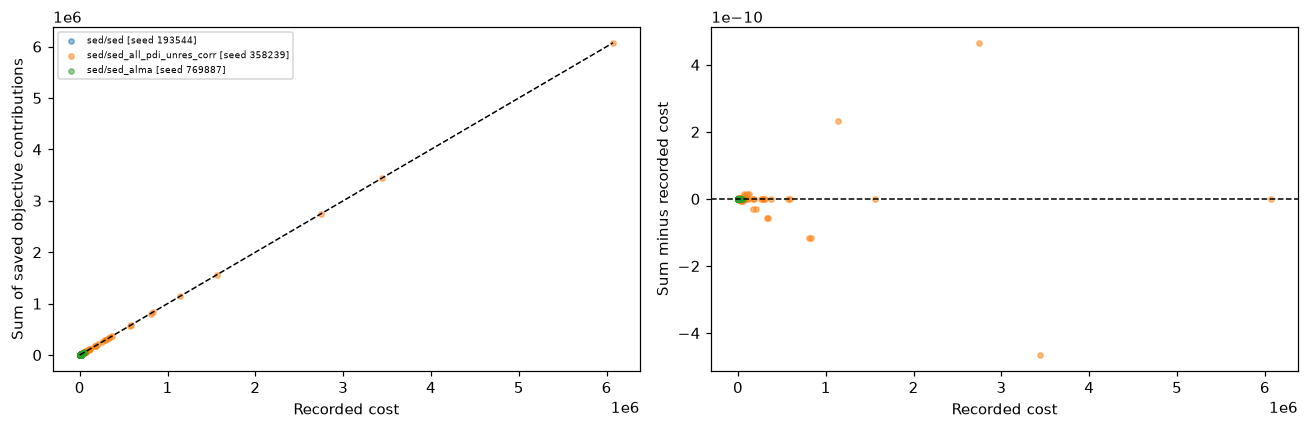

In [34]:
audit_columns = ['evaluation_id', 'history', 'config_id', 'budget', 'stage', 'products',
                 'usable', 'exclusion', 'products_source', 'cost_audit_status', 'cost',
                 'available_score_sum', 'reconstructed_cost', 'cost_difference',
                 'cost_absolute_difference', 'cost_relative_difference',
                 'missing_score_terms', 'unknown_products', 'unexpected_score_terms',
                 *SCORE_COLUMNS.values()]
score_audit = evaluations.reindex(columns=audit_columns).copy()
score_audit_summary = (score_audit.groupby(
    ['history', 'budget', 'stage', 'products', 'usable', 'cost_audit_status'], dropna=False)
    .agg(evaluations=('evaluation_id', 'size'),
         max_absolute_difference=('cost_absolute_difference', 'max'),
         max_relative_difference=('cost_relative_difference', lambda x: x.abs().max()))
    .reset_index())
display(score_audit_summary)
display(score_audit.loc[score_audit.usable].head(20))
score_audit_issues = score_audit.loc[score_audit.usable & score_audit.cost_audit_status.ne('match')]
if not score_audit_issues.empty:
    display(Markdown('**Usable evaluations with incomplete or mismatching score records:**'))
    display(score_audit_issues.head(30))
audit_plot = evaluations.loc[evaluations.usable & evaluations.cost_terms_complete]
if not audit_plot.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for history, group in audit_plot.groupby('history', sort=False):
        axes[0].scatter(group.cost, group.reconstructed_cost, s=12, alpha=.5, label=history)
        axes[1].scatter(group.cost, group.cost_difference, s=12, alpha=.5)
    lo = min(audit_plot.cost.min(), audit_plot.reconstructed_cost.min())
    hi = max(audit_plot.cost.max(), audit_plot.reconstructed_cost.max())
    axes[0].plot([lo, hi], [lo, hi], 'k--', linewidth=1)
    axes[0].set(xlabel='Recorded cost', ylabel='Sum of saved objective contributions')
    axes[0].legend(fontsize=6)
    axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
    axes[1].set(xlabel='Recorded cost', ylabel='Sum minus recorded cost')
    fig.tight_layout()
    show_figure('score_sum_vs_cost', fig)


## 3. Best models and observation contributions

Select the **configured final budget**, rather than falling back to an earlier stage when no final-stage evaluation succeeded. Budget numbers are local to a run: `1` may mean SED-only in one folder and all observations in another. The products column defines the observational objective.

The tables keep the lowest recorded score for each distinct configuration. They are best observed evaluations, not repeated-seed means or a claim of convergence. Repeated trials remain available in `evaluations`. Final `smac_results` reruns are not substituted for runhistory scores.

`objective_key` uses readable product labels: SED, INT(band) for one wavelength per band, INT(chrom) for chromatic interferometry, PDI(V,I,H) for the listed bands, and ALMA. Different modes and PDI band selections remain separate. Matching labels establish the same product set, not identical data, weights or numerical settings.


,history,config_id,budget,products,cost,score_sed,score_pionier,score_gravity,score_matisse_l,score_matisse_n,score_pdi_V,score_pdi_I,score_pdi_H,score_alma
0,sed/sed [seed 193544],1000,1.0,sed,14.735357,14.735357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,sed/sed_alma [seed 769887],462,1.0,"alma, sed",41.247217,21.978140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.269077
2,sed/sed_all_pdi_unres_corr [seed 358239],62,1.0,"alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",2594.729040,1239.729010,212.1935,318.243776,142.808271,5.876058,89.422199,432.525423,86.795675,67.135128


,history,config_id,cost,sed_ebminv,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_Rin,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_amax,param__zone_1_species_1_amin,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_Rc,param__zone_2_Rout,param__zone_2_surface_density_exp
0,sed/sed [seed 193544],1000,14.735357,1.396480,0.010,23.977265,98,0.007357,44,6.492295,0.922486,2.057485,0.647166,2.946033,9904.212633,0.114159,0.10,0.355180,2.433022,166,313,-1.892451
1,sed/sed_alma [seed 769887],462,41.247217,1.375409,0.001,29.858272,92,0.007657,50,6.969076,0.750952,2.491109,0.742099,2.968416,3318.523398,0.277882,0.15,0.427706,2.409066,153,450,-0.632780
2,sed/sed_all_pdi_unres_corr [seed 358239],62,2594.729040,1.406159,0.001,35.516048,154,0.018214,21,6.198870,1.232898,1.160897,0.673947,2.130238,207.242107,0.945431,0.05,0.091596,1.326847,337,427,-1.881059


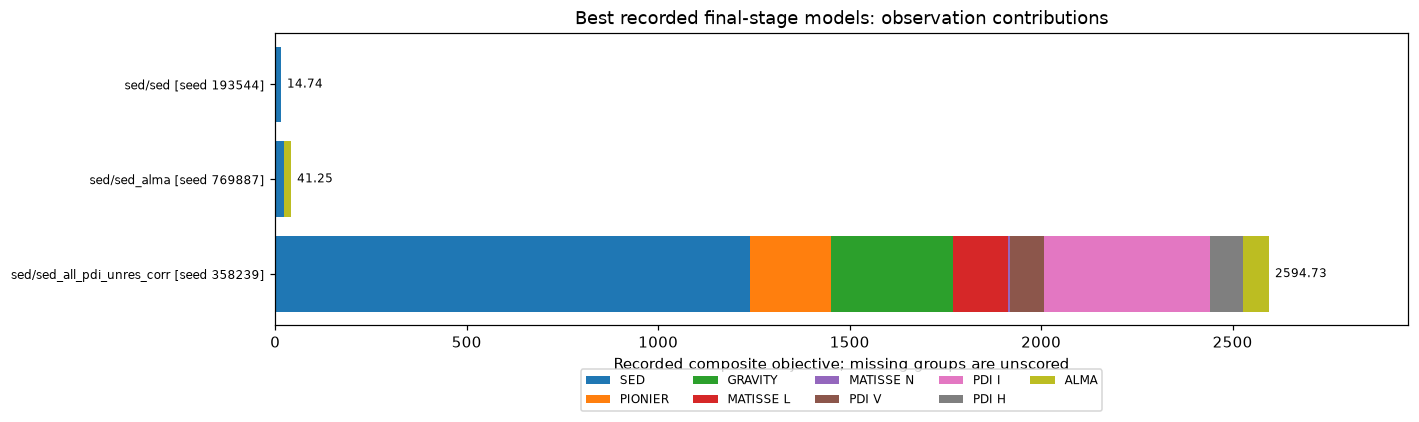

In [35]:
best, competitive = select_solutions(
    evaluations, RELATIVE_COST_ALLOWANCE, ABSOLUTE_COST_ALLOWANCE)
missing_final = sorted(set(inventory.history) - set(best.history))
if missing_final:
    print('No usable configured-final-stage model:', *missing_final, sep='\n')
score_columns = ['history', 'config_id', 'budget', 'products', 'cost', *SCORE_COLUMNS.values()]
display(best.reindex(columns=score_columns))
parameter_columns = ['param__' + p for p in PARAMETERS if 'param__' + p in best]
display(best.reindex(columns=['history', 'config_id', 'cost', 'sed_ebminv', *parameter_columns]))
if PLOT_HISTORIES is None:
    plotted_best, plotted_competitive = best, competitive
else:
    plotted_best = best[best.history.isin(PLOT_HISTORIES)]
    plotted_competitive = competitive[competitive.history.isin(PLOT_HISTORIES)]
show_figure('observation_contributions', plot_costs(plotted_best))

## 4. Search progress and sensitivity to observation staging

Each curve tracks its own stage objective. A cost discontinuity when observations are added is not a convergence failure. Do not compare the numerical heights of curves for different product sets as if they were the same objective.

Rank correlations use only configurations evaluated at both neighbouring budgets within a history. Pairing uses parameter values, simulation seed and instance. These selected pairs can be biased by promotion. Repeated evaluations of the same pairing key are averaged only for this diagnostic.

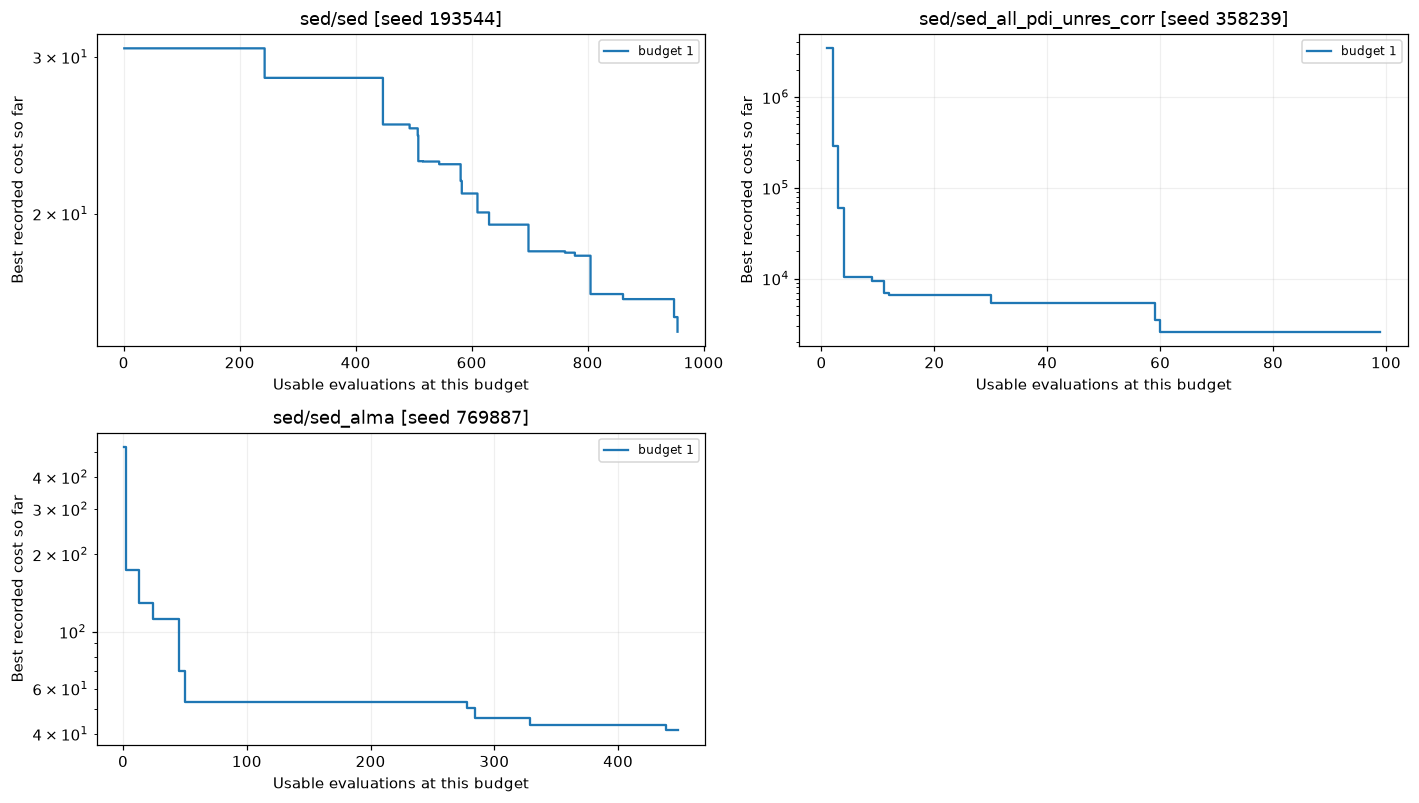

No multi-budget histories to compare.


In [36]:
plot_evaluations = evaluations if PLOT_HISTORIES is None else evaluations[evaluations.history.isin(PLOT_HISTORIES)]
show_figure('convergence_by_stage', plot_convergence(plot_evaluations))
rank_correlations = stage_correlations(evaluations)
if rank_correlations.empty:
    print('No multi-budget histories to compare.')
else:
    display(rank_correlations)

## 5. Competitive physical solutions and parameter boundaries

Points show distinct competitive sampled configurations; stars identify the best observed model. No inverse-cost or likelihood weighting is applied. Narrow sampled ranges may reflect search concentration, fixed assumptions, selection or parameter bounds.

The boundary table measures the fraction of competitive models within 2% of each numerical interval (in log coordinates for log-sampled parameters). Categorical endpoints are not treated as continuous bounds. Inclination near zero makes disk PA difficult to interpret; PA also has an angular wrap at 0/180 degrees.

,competitive_distinct_models
history,
sed/sed [seed 193544],70
sed/sed_all_pdi_unres_corr [seed 358239],4
sed/sed_alma [seed 769887],76


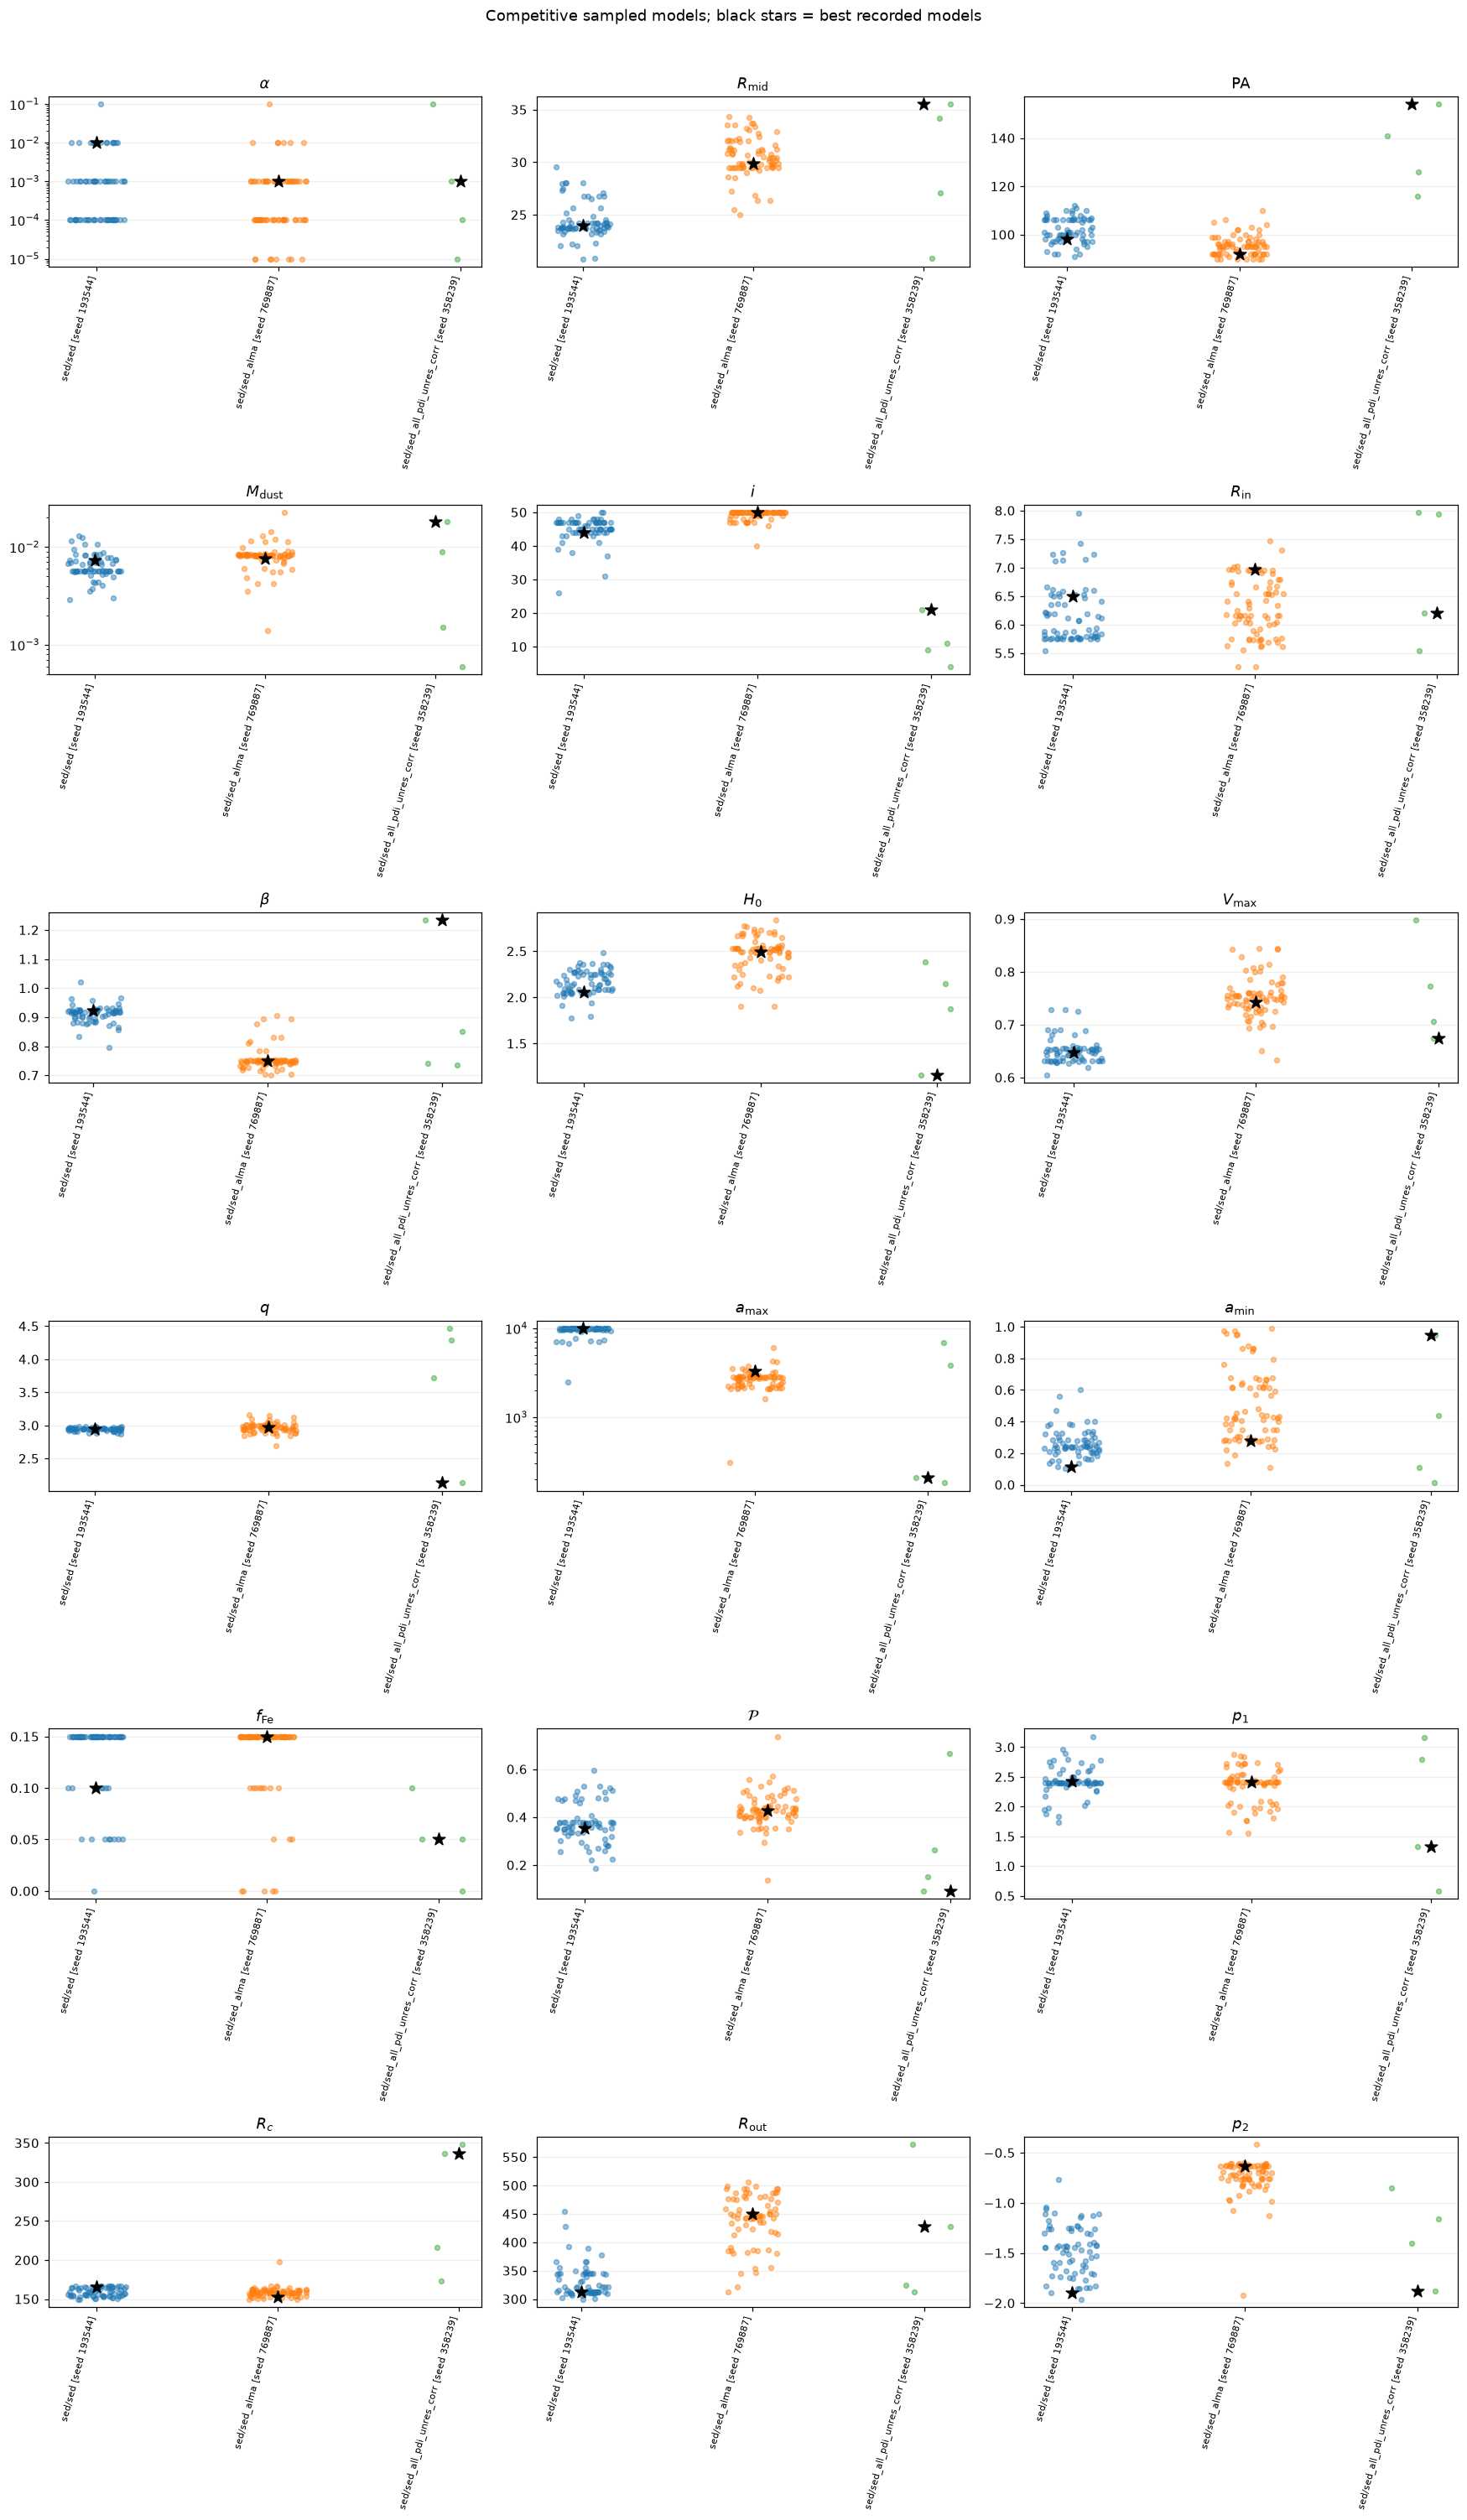

,history,parameter,models,sample_min,sample_median,sample_max,lower_bound,upper_bound,fraction_near_lower_bound,fraction_near_upper_bound,interpretation
2,sed/sed [seed 193544],disk_pa,70,91.000000,101.000000,112.000000,90.00,180.0,0.014286,0.000000,sampled competitive models; not a confidence i...
4,sed/sed [seed 193544],inclination,70,26.000000,45.000000,50.000000,0.00,50.0,0.000000,0.042857,sampled competitive models; not a confidence i...
8,sed/sed [seed 193544],zone_1_species_1_Vmax,70,0.604898,0.647640,0.728060,0.60,0.9,0.014286,0.000000,sampled competitive models; not a confidence i...
10,sed/sed [seed 193544],zone_1_species_1_amax,70,2491.350643,9883.727979,9971.686254,100.00,10000.0,0.000000,0.871429,sampled competitive models; not a confidence i...
15,sed/sed [seed 193544],zone_2_Rc,70,150.000000,159.000000,167.000000,150.00,350.0,0.271429,0.000000,sampled competitive models; not a confidence i...
16,sed/sed [seed 193544],zone_2_Rout,70,300.000000,320.500000,455.000000,300.00,600.0,0.057143,0.000000,sampled competitive models; not a confidence i...
17,sed/sed [seed 193544],zone_2_surface_density_exp,70,-1.959389,-1.444278,-0.763639,-1.99,-0.1,0.014286,0.000000,sampled competitive models; not a confidence i...
20,sed/sed_alma [seed 769887],disk_pa,76,90.000000,95.000000,110.000000,90.00,180.0,0.105263,0.000000,sampled competitive models; not a confidence i...
22,sed/sed_alma [seed 769887],inclination,76,40.000000,50.000000,50.000000,0.00,50.0,0.000000,0.815789,sampled competitive models; not a confidence i...
24,sed/sed_alma [seed 769887],zone_1_flaring_exp,76,0.701614,0.750136,0.906465,0.70,2.0,0.105263,0.000000,sampled competitive models; not a confidence i...


In [37]:
parameter_ranges = parameter_summary(competitive, configspaces)
display(competitive.groupby('history').size().rename('competitive_distinct_models').to_frame())
show_figure('competitive_parameters', plot_parameters(
    plotted_competitive, plotted_best, PARAMETERS, LOG_PARAMETERS))
if not parameter_ranges.empty:
    boundary_flags = parameter_ranges.loc[
        parameter_ranges.fraction_near_lower_bound.gt(0) | parameter_ranges.fraction_near_upper_bound.gt(0)]
    display(boundary_flags)
else:
    boundary_flags = pd.DataFrame()
    print('No numeric competitive parameter summaries available.')

### Quantify parameter pairs: Spearman and Kendall Tau-b for each modelling run

Audit **every independently varied parameter pair**, separately within each modelling history (folder plus optimiser seed) and final-stage observation objective. Different histories, seeds and objectives are never pooled. Fixed/tied parameters are excluded. Nonnumeric categories are not assigned arbitrary numeric codes.

**Calculate both coefficients on exactly the same finite paired model values:**

- **Spearman ρ** correlates the ranks, using average ranks for ties.
- **Kendall τ-b** compares concordant and discordant pairs, with normalisation accounting for ties on either parameter axis. The calculation explicitly uses `scipy.stats.kendalltau(..., variant='b')`.

The paired model counts, exclusions, deduplication and sample scopes are identical. The table retains `rho_competitive`, `tau_b_competitive`, `rho_all_final` and `tau_b_all_final`. No p-values are used for ranking or displayed as evidence of significance.

**First: a separate heatmap for each metric and each run.** Both heatmaps have the same parameter order, support masks, observation objective and model sample. Every eligible coefficient is annotated, including weak values below the scatter-selection threshold. Positive correlations are red, negative correlations blue; darker colours indicate larger absolute coefficients. Grey `NA` cells indicate insufficient models, insufficient variation, periodic parameters or undefined coefficients. They are not zero correlations. Diagonal self-correlations are omitted. Direct ConfigSpace relationships carry a purple outline and a dagger.

| Absolute coefficient (display bands) | Descriptive level |
|---|---|
| < 0.2 | Negligible |
| 0.2 to < 0.4 | Weak |
| 0.4 to < 0.6 | Moderate |
| 0.6 to < 0.8 | Strong |
| 0.8 to 1 | Very strong |

The same numeric bands make the two displays consistent; **they do not make Spearman and Kendall coefficients interchangeable**, nor establish equivalent significance or evidence.

**Then: matching association figures for each metric and each run.** Preserve the existing Spearman-based ranking and `PAIR_MIN_ABS_RHO` threshold, selecting up to `PAIR_MAX_PER_HISTORY` shared pairs per run. For every selected pair, render Spearman and Kendall versions using identical models and axes; colours and borders follow the metric named on that figure. Each panel annotates both coefficients and model counts for both sample scopes. Large selections are paginated using `PAIR_PANELS_PER_FIGURE`, with pages kept separate by run and metric. A run with no qualifying shared pairs is reported explicitly.

`PAIR_METRICS` controls which metrics are rendered; both are always calculated. `PAIR_SCOPE` chooses `competitive` or `all_final` for heatmaps and shared pair selection. The defaults require 20 distinct models and 3 distinct values per parameter. `PAIR_MIN_ABS_RHO` controls only the shared Spearman selection, not heatmap visibility or a Kendall threshold. Direct ConfigSpace relations are excluded from automatic scatter selection unless `PAIR_INCLUDE_CONSTRAINED=True`.

The analysed scope uses the correlation colour. In competitive scope, all final-stage models form a grey background. In all-final scope, the full sample is coloured and competitive models have black outlines. Both axes respect `LOG_PARAMETERS`.

These are exploratory rank associations, **not posterior correlations or significance tests**. Adaptive search, bounds, imposed inequalities and competitive-model selection can induce associations; choosing the largest coefficients among many pairs can exaggerate apparent strength. Nonmonotonic dependencies may be missed. The pair audit, metric-specific strength counts and figure index are included in optional CSV exports.

,history,objective_key,correlation_level,parameter_pairs,metric
0,sed/sed [seed 193544],SED,Weak,67,spearman
1,sed/sed [seed 193544],SED,Negligible,58,spearman
2,sed/sed [seed 193544],SED,Moderate,28,spearman
3,sed/sed_alma [seed 769887],SED+ALMA,Negligible,111,spearman
4,sed/sed_alma [seed 769887],SED+ALMA,Weak,41,spearman
5,sed/sed_alma [seed 769887],SED+ALMA,Moderate,1,spearman
6,sed/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",Unavailable,153,spearman
7,sed/sed [seed 193544],SED,Weak,67,kendall_tau_b
8,sed/sed [seed 193544],SED,Negligible,84,kendall_tau_b
9,sed/sed [seed 193544],SED,Moderate,2,kendall_tau_b


,history,reason_competitive,parameter_pairs
0,sed/sed [seed 193544],eligible,153
1,sed/sed_alma [seed 769887],eligible,153
2,sed/sed_all_pdi_unres_corr [seed 358239],too_few_models,153


Observation products: sed


#### Spearman heatmap: sed/sed [seed 193544]

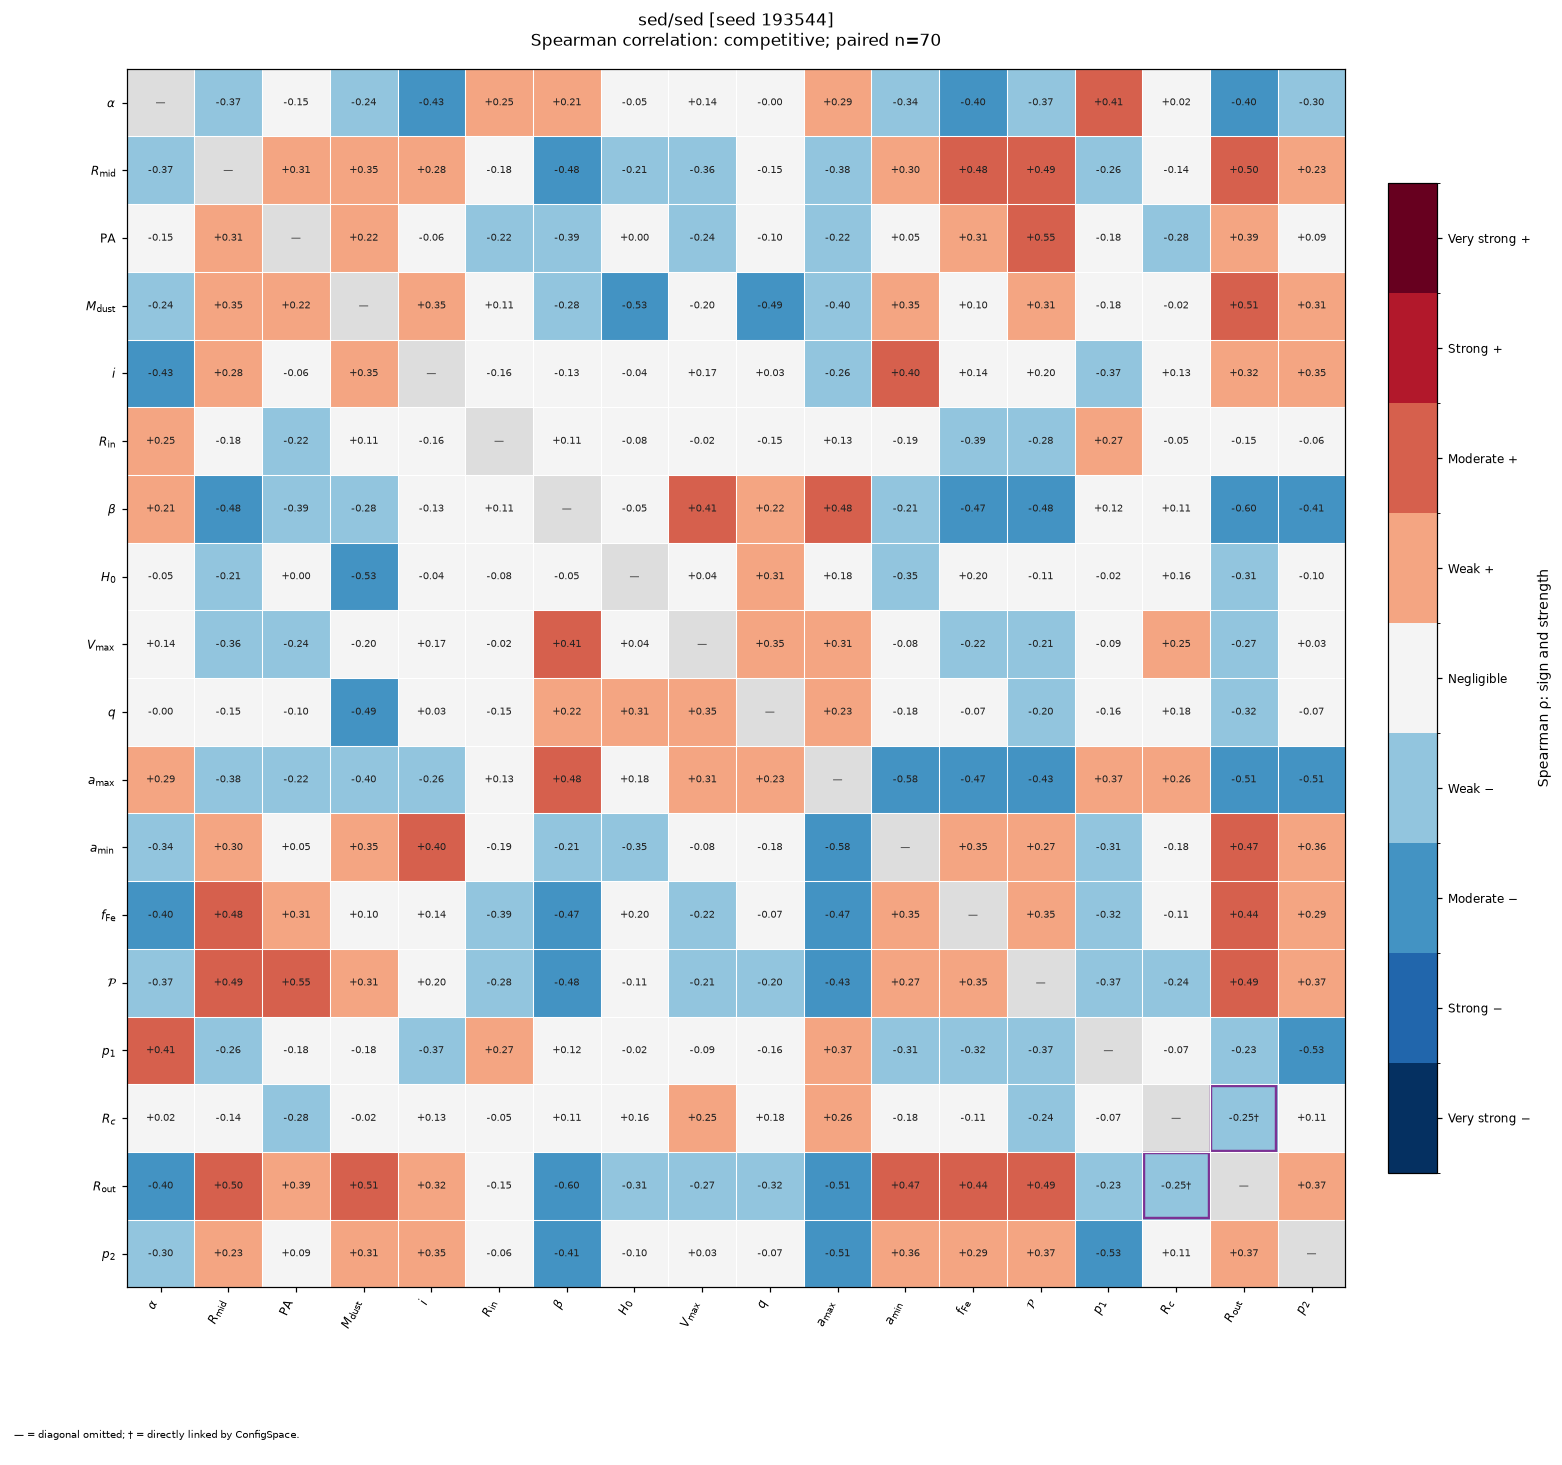

#### Kendall Tau-b heatmap: sed/sed [seed 193544]

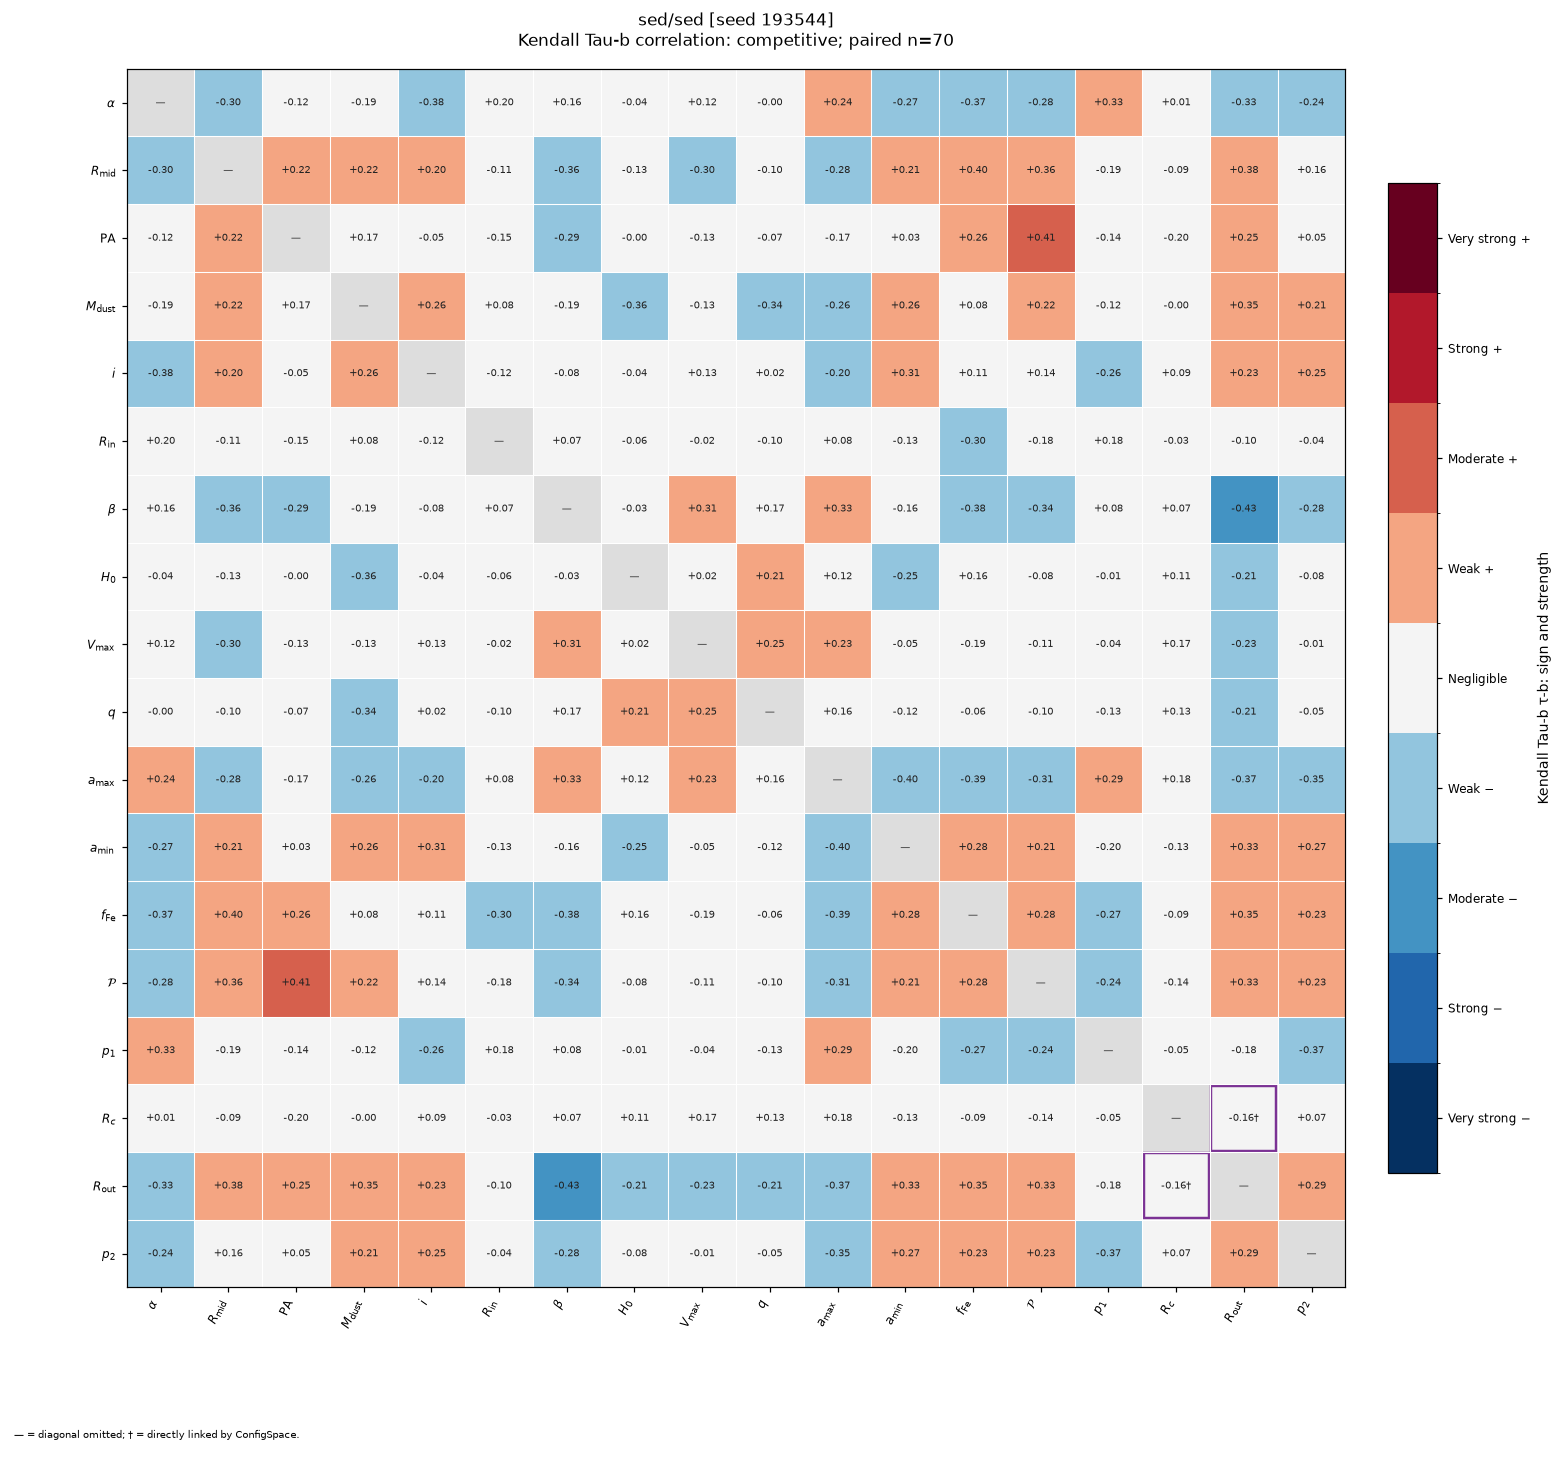

Observation products: alma, sed


#### Spearman heatmap: sed/sed_alma [seed 769887]

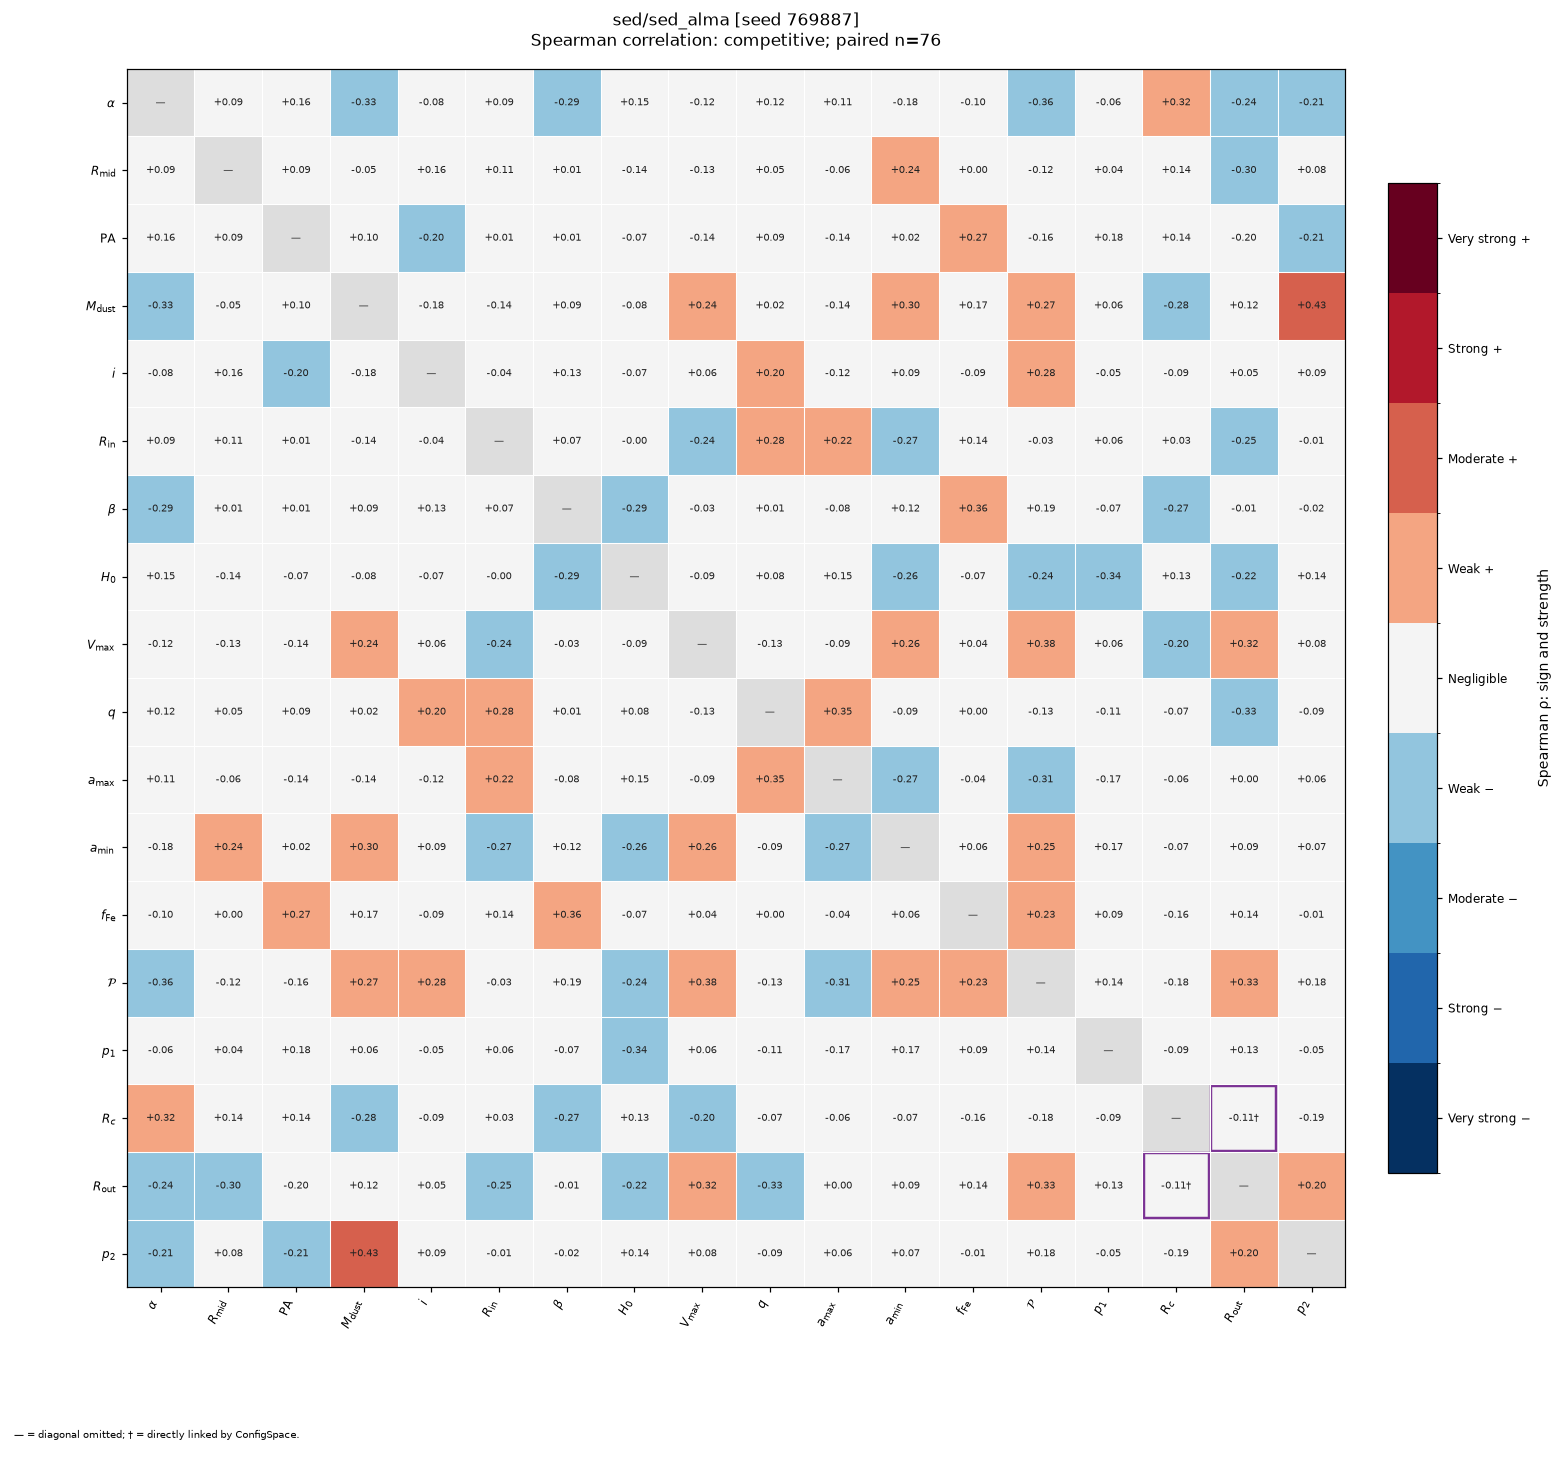

#### Kendall Tau-b heatmap: sed/sed_alma [seed 769887]

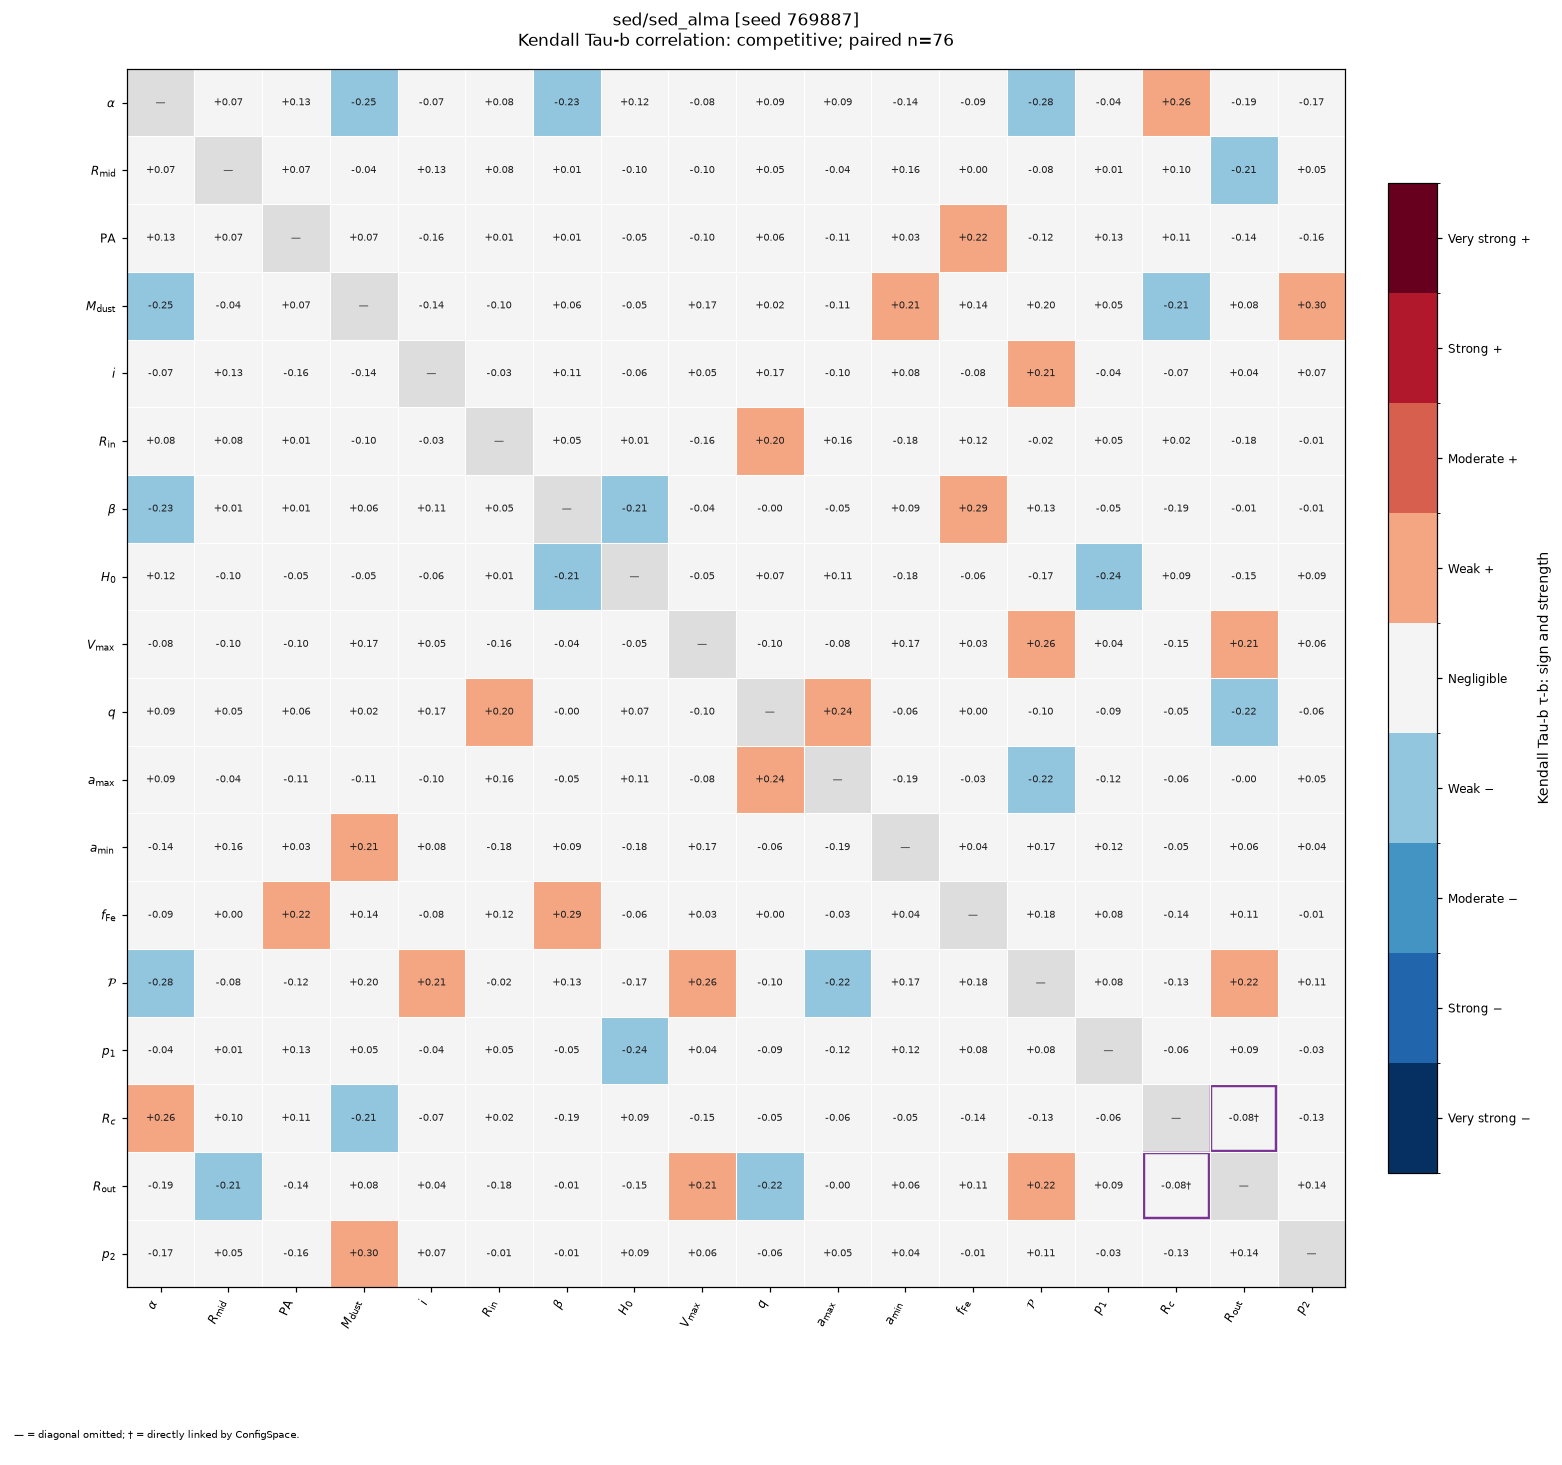

Observation products: alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband


#### Spearman heatmap: sed/sed_all_pdi_unres_corr [seed 358239]

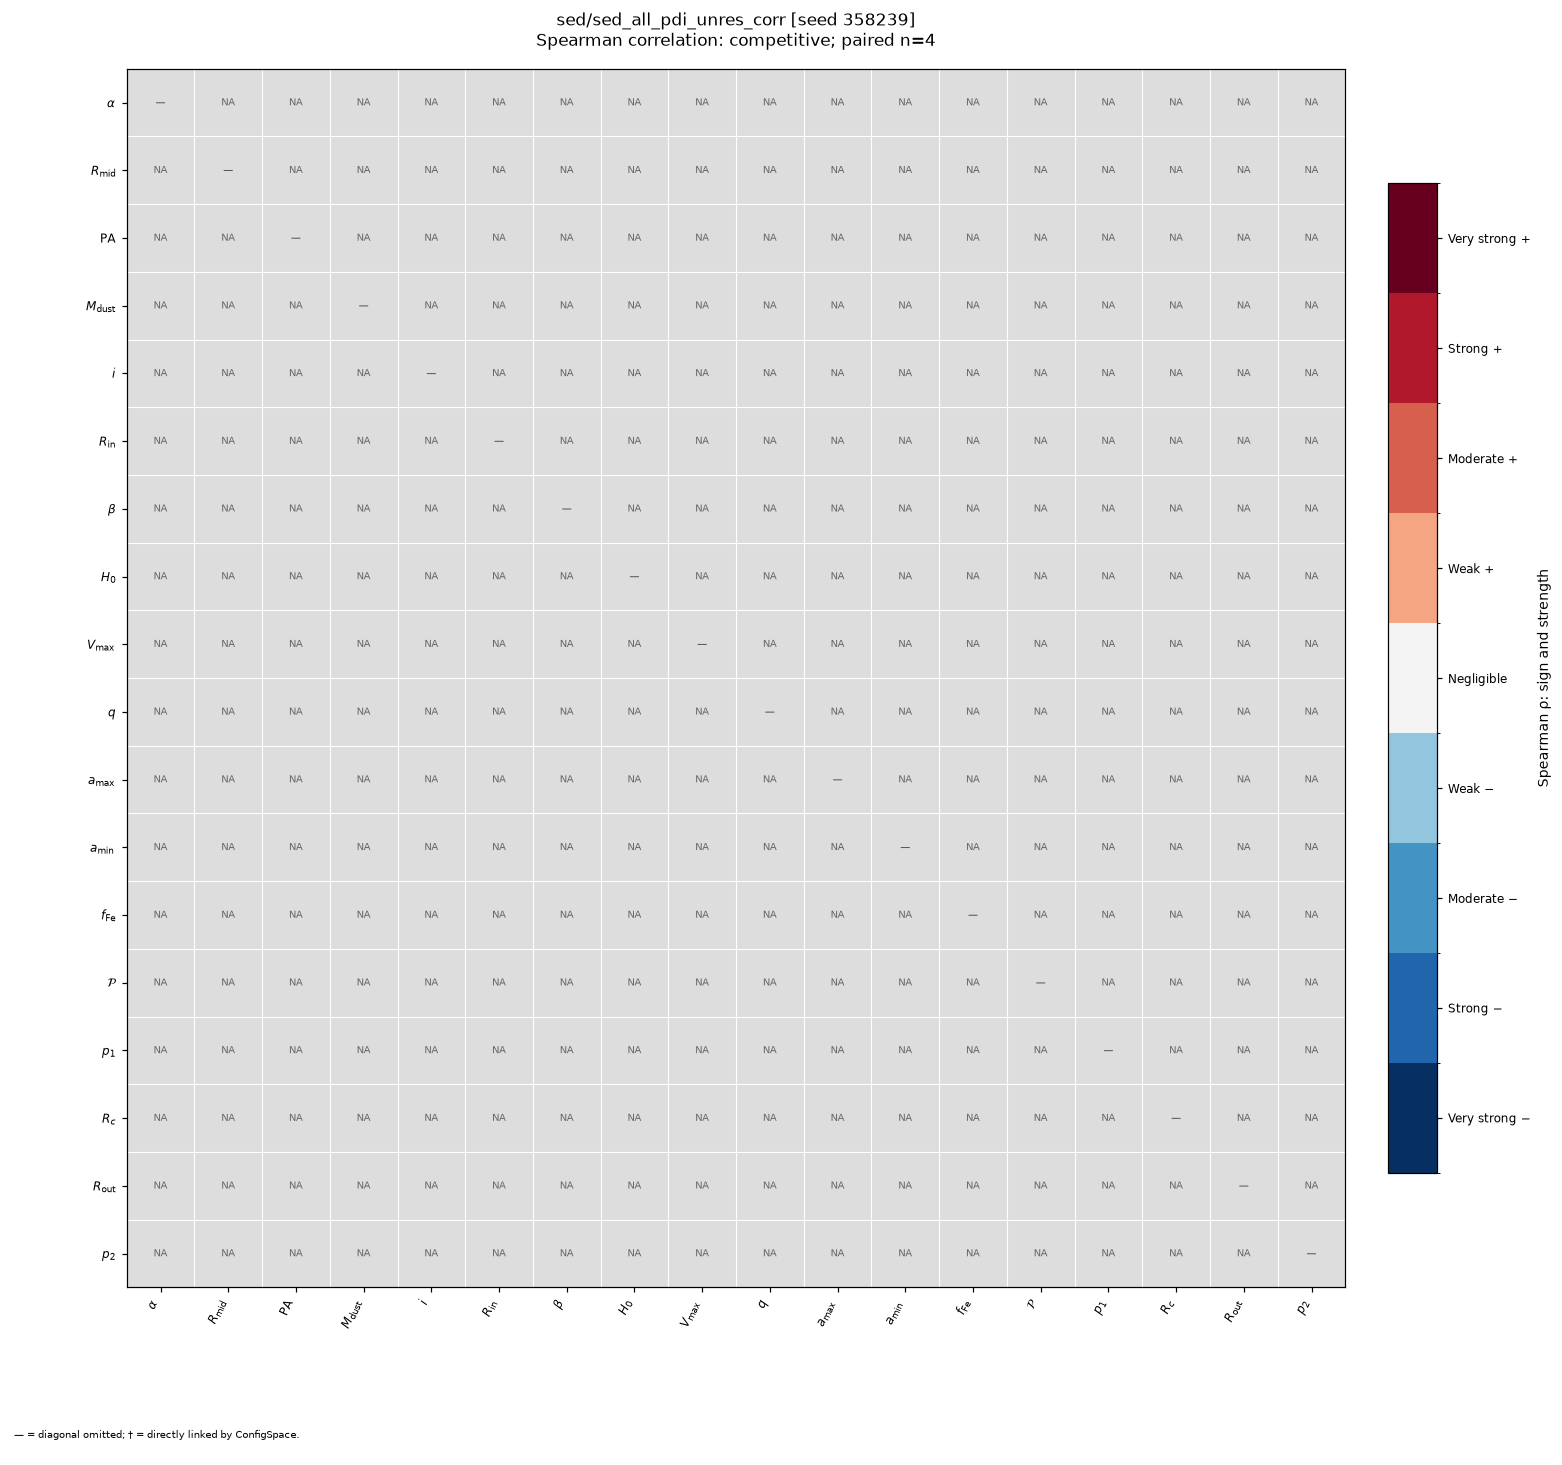

#### Kendall Tau-b heatmap: sed/sed_all_pdi_unres_corr [seed 358239]

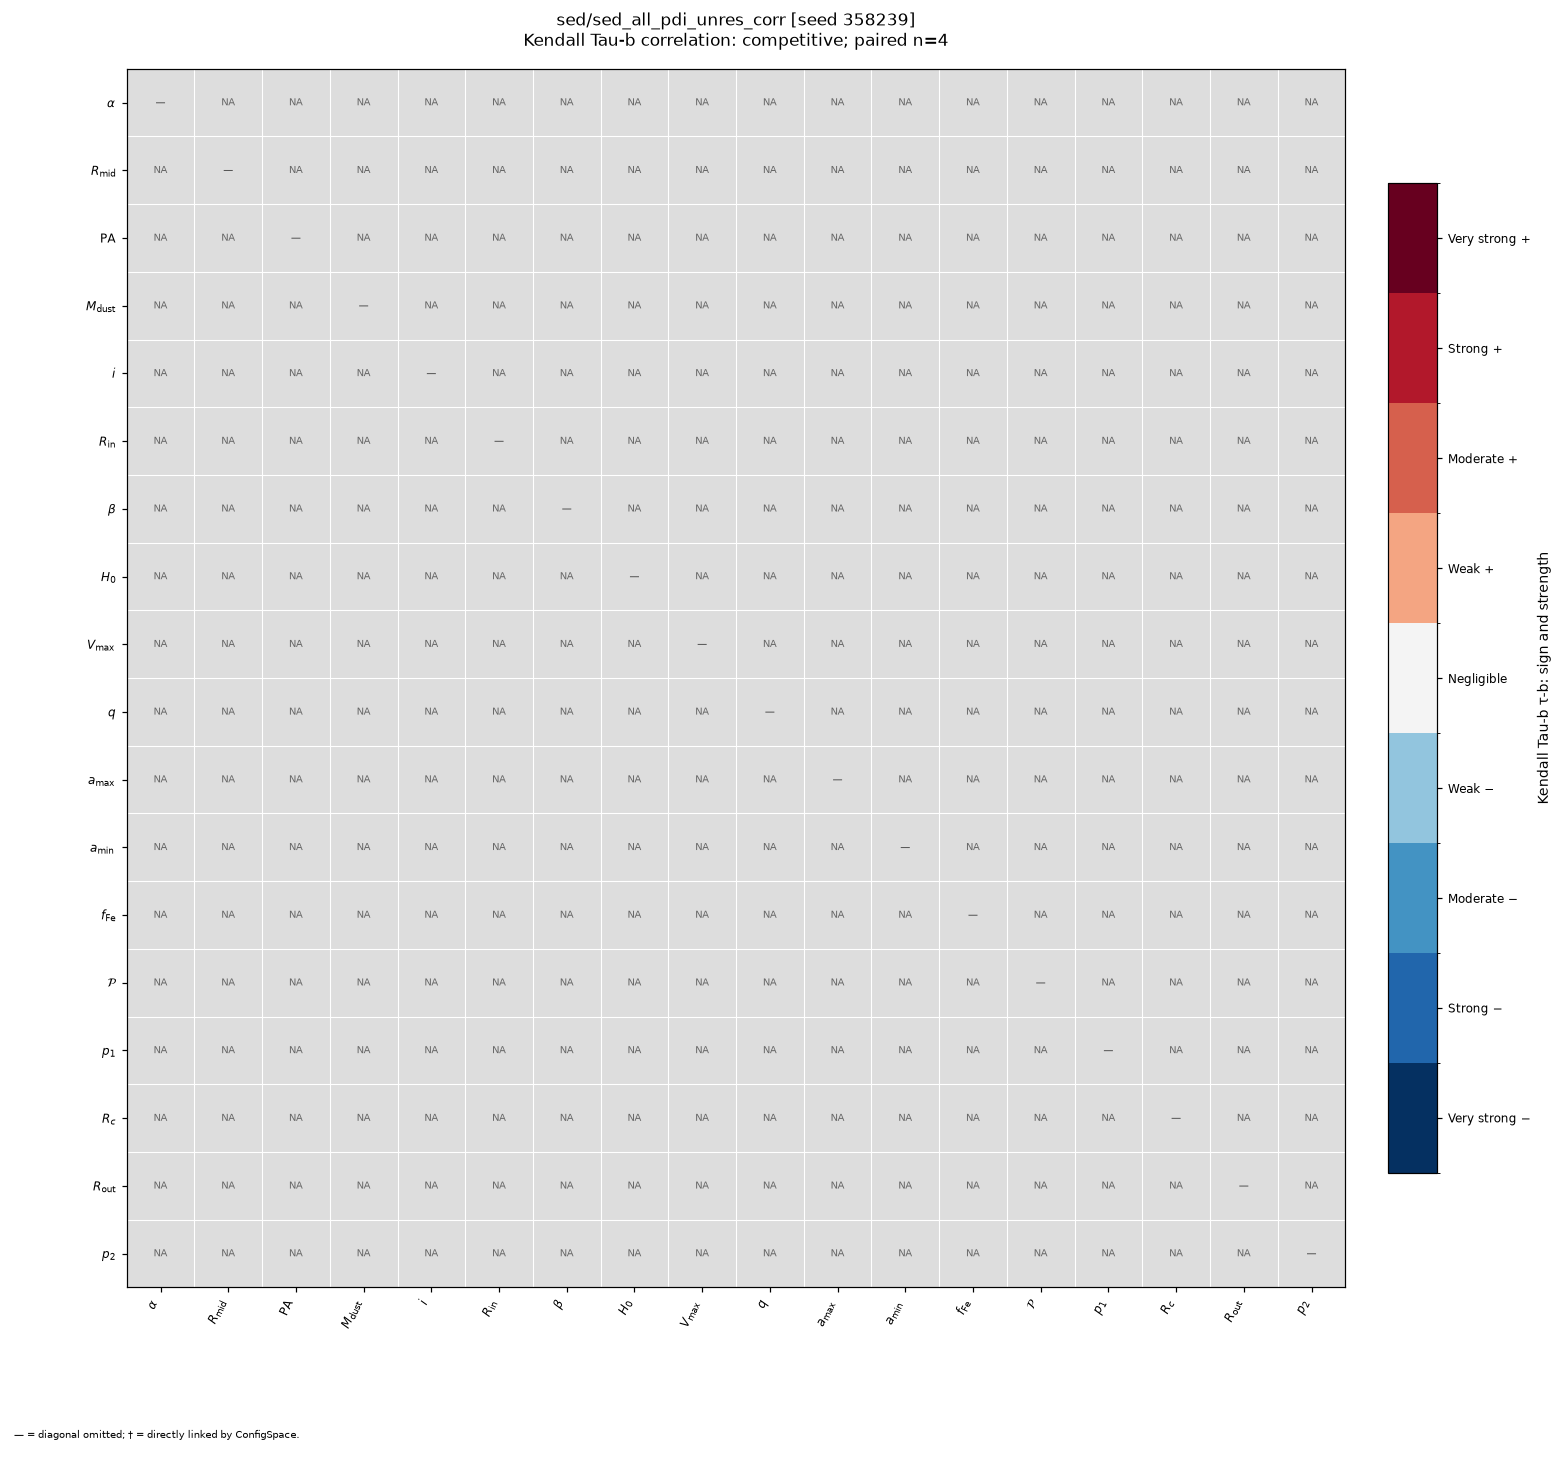

In [38]:
# 1. Compute both metrics on the same model pairs, then show per-run heatmaps.
# PARAMETERS controls marginal plots; this audit includes all independently varied parameters.
if not PAIR_METRICS:
    raise ValueError('Select at least one display metric in PAIR_METRICS.')
for metric in PAIR_METRICS:
    correlation_metric(metric)  # Validate metric names before rendering.
pair_analysis = parameter_pair_analysis(
    plot_evaluations, plotted_competitive, configspaces, parameters=None,
    min_models=PAIR_MIN_MODELS, min_unique=PAIR_MIN_UNIQUE_VALUES,
    periodic_parameters=PAIR_PERIODIC_PARAMETERS)
for scope in ('competitive', 'all_final'):
    pair_analysis[f'level_{scope}'] = pair_analysis[f'rho_{scope}'].where(
        pair_analysis[f'eligible_{scope}'].eq(True)).map(correlation_strength)
    pair_analysis[f'level_tau_b_{scope}'] = pair_analysis[f'tau_b_{scope}'].where(
        pair_analysis[f'eligible_{scope}'].eq(True)).map(correlation_strength)
level_tables = []
for metric in ('spearman', 'kendall_tau_b'):
    level_column = f'level_{PAIR_SCOPE}' if metric == 'spearman' else f'level_tau_b_{PAIR_SCOPE}'
    summary = (pair_analysis.groupby(['history', 'objective_key', level_column], sort=False)
               .size().rename('parameter_pairs').reset_index()
               .rename(columns={level_column: 'correlation_level'}))
    summary['metric'] = metric
    level_tables.append(summary)
correlation_level_summary = pd.concat(level_tables, ignore_index=True)
pair_plot_rows = []
if pair_analysis.empty:
    print('No independently varied parameter pairs at the configured final stage.')
else:
    display(correlation_level_summary)
    display(pair_analysis.groupby(['history', f'reason_{PAIR_SCOPE}'], sort=False)
            .size().rename('parameter_pairs').reset_index())
    for group_index, ((history, objective), group) in enumerate(
            pair_analysis.groupby(['history', 'objective_key'], sort=False), start=1):
        print('Observation products:', group.products.iloc[0])
        for metric in PAIR_METRICS:
            _, metric_label, _ = correlation_metric(metric)
            display(Markdown(f'#### {metric_label} heatmap: {history}'))
            suffix = '' if metric == 'spearman' else '_kendall_tau_b'
            heatmap_name = f'parameter_correlation_heatmap_{group_index:02d}{suffix}'
            association_name = f'parameter_associations_{group_index:02d}{suffix}'
            pair_plot_rows.append({'history': history, 'objective_key': objective,
                                   'scope': PAIR_SCOPE, 'metric': metric,
                                   'selection_metric': 'spearman', 'heatmap_figure': heatmap_name,
                                   'association_figure': association_name, 'association_panels': 0})
            show_figure(heatmap_name, plot_parameter_correlation_heatmap(group, PAIR_SCOPE, metric=metric))
pair_plot_index = pd.DataFrame(pair_plot_rows, columns=[
    'history', 'objective_key', 'scope', 'metric', 'selection_metric',
    'heatmap_figure', 'association_figure', 'association_panels'])

#### Shared parameter associations: sed/sed [seed 193544]

,parameter_x,parameter_y,level_competitive,level_tau_b_competitive,n_competitive,rho_competitive,tau_b_competitive,n_all_final,rho_all_final,tau_b_all_final,direct_configspace_constraint
0,zone_1_flaring_exp,zone_2_Rout,Moderate,Moderate,70,-0.595112,-0.431736,955,0.112495,0.063758,False
1,zone_1_species_1_amax,zone_1_species_1_amin,Moderate,Weak,70,-0.575135,-0.399683,955,0.195120,0.109732,False
2,disk_pa,zone_1_species_1_porosity,Moderate,Moderate,70,0.553123,0.409917,955,-0.029970,-0.027723,False
3,disk_total_dust_mass,zone_1_scale_height,Moderate,Weak,70,-0.527086,-0.364295,955,0.041958,0.021071,False
4,zone_1_surface_density_exp,zone_2_surface_density_exp,Moderate,Weak,70,-0.526420,-0.370297,955,-0.099322,-0.072936,False
5,disk_total_dust_mass,zone_2_Rout,Moderate,Weak,70,0.513780,0.352641,955,-0.043447,-0.023888,False
6,zone_1_species_1_amax,zone_2_Rout,Moderate,Weak,70,-0.506114,-0.366023,955,-0.449306,-0.313928,False
7,zone_1_species_1_amax,zone_2_surface_density_exp,Moderate,Weak,70,-0.506113,-0.354252,955,-0.274336,-0.200749,False
8,disk_Rmid,zone_2_Rout,Moderate,Weak,70,0.502932,0.377075,955,0.128635,0.097081,False


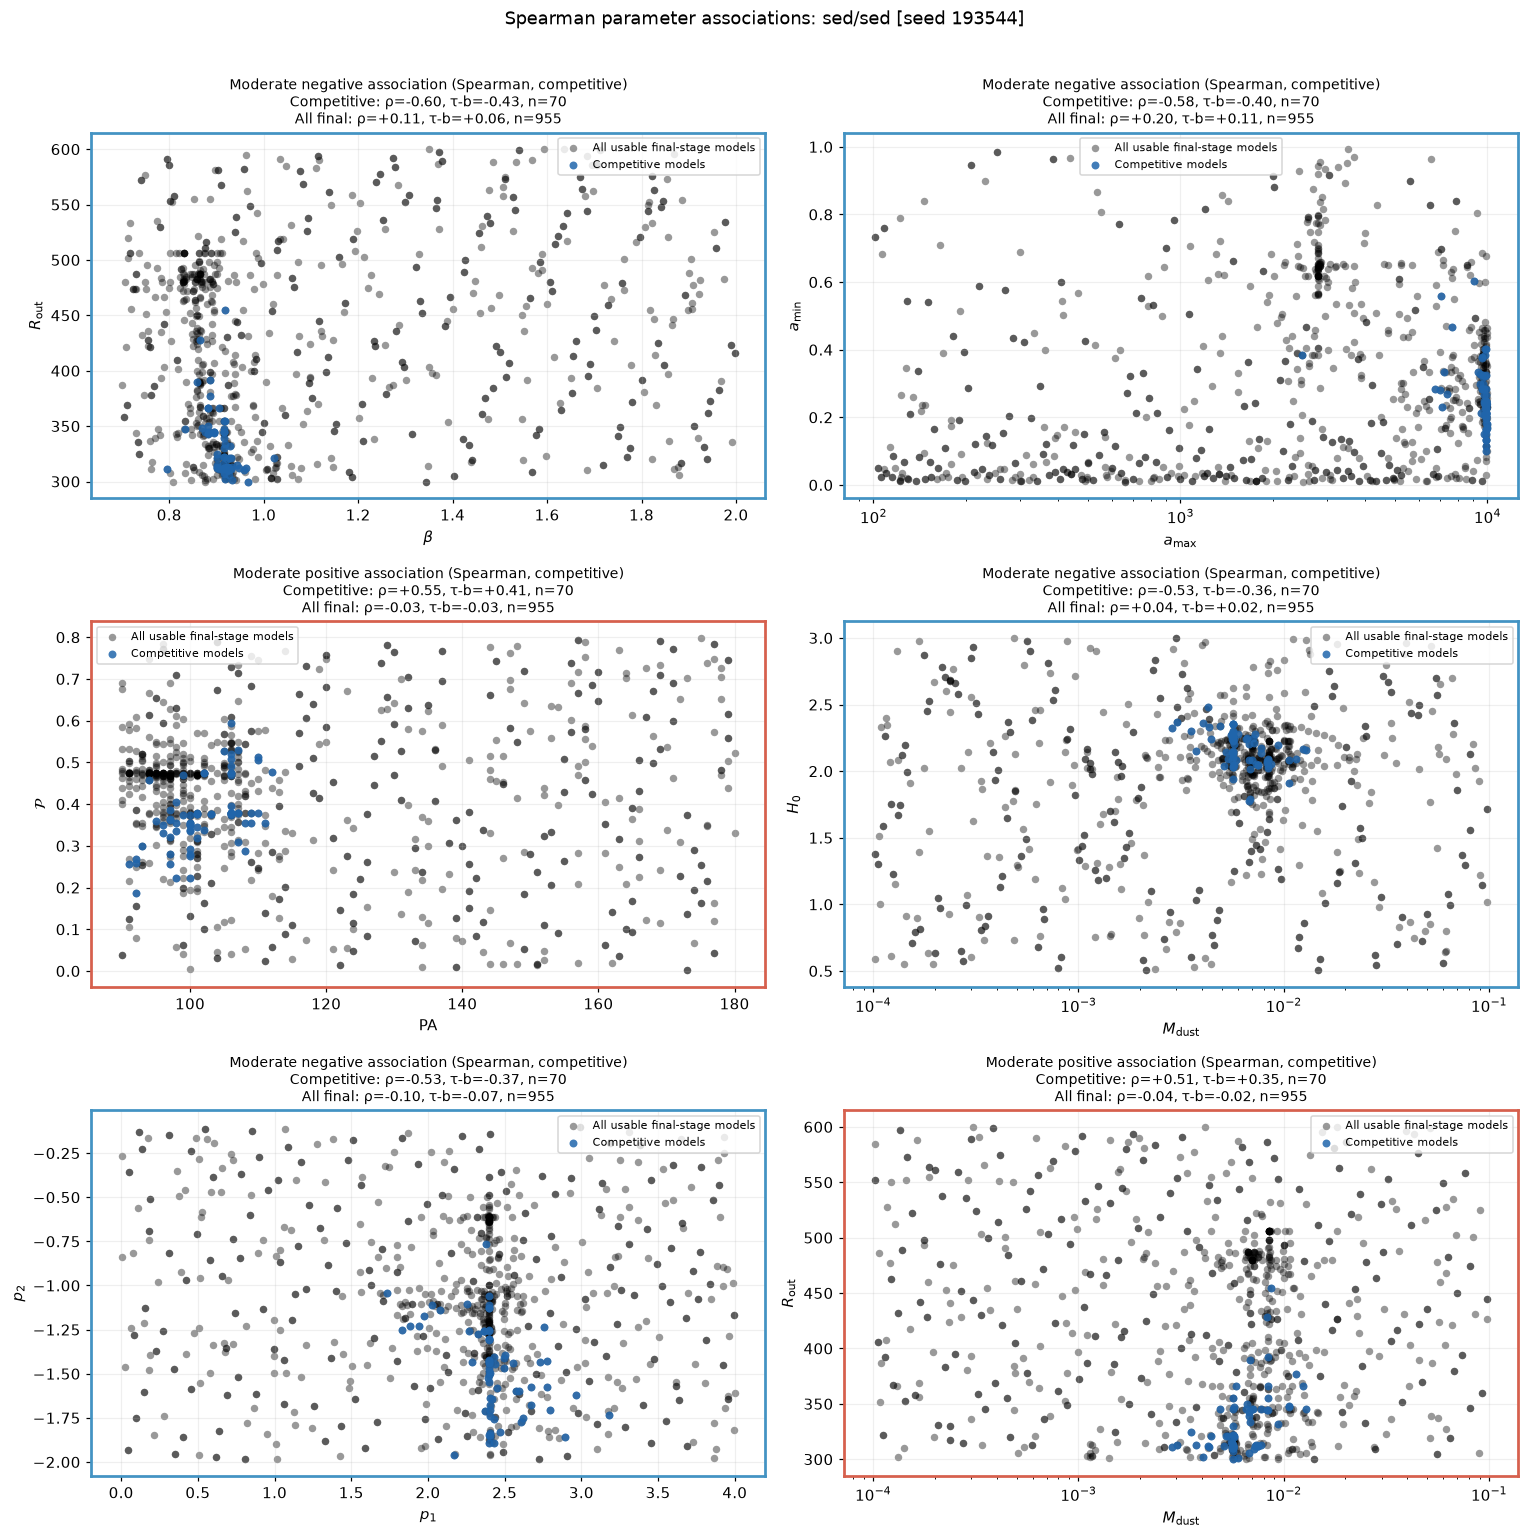

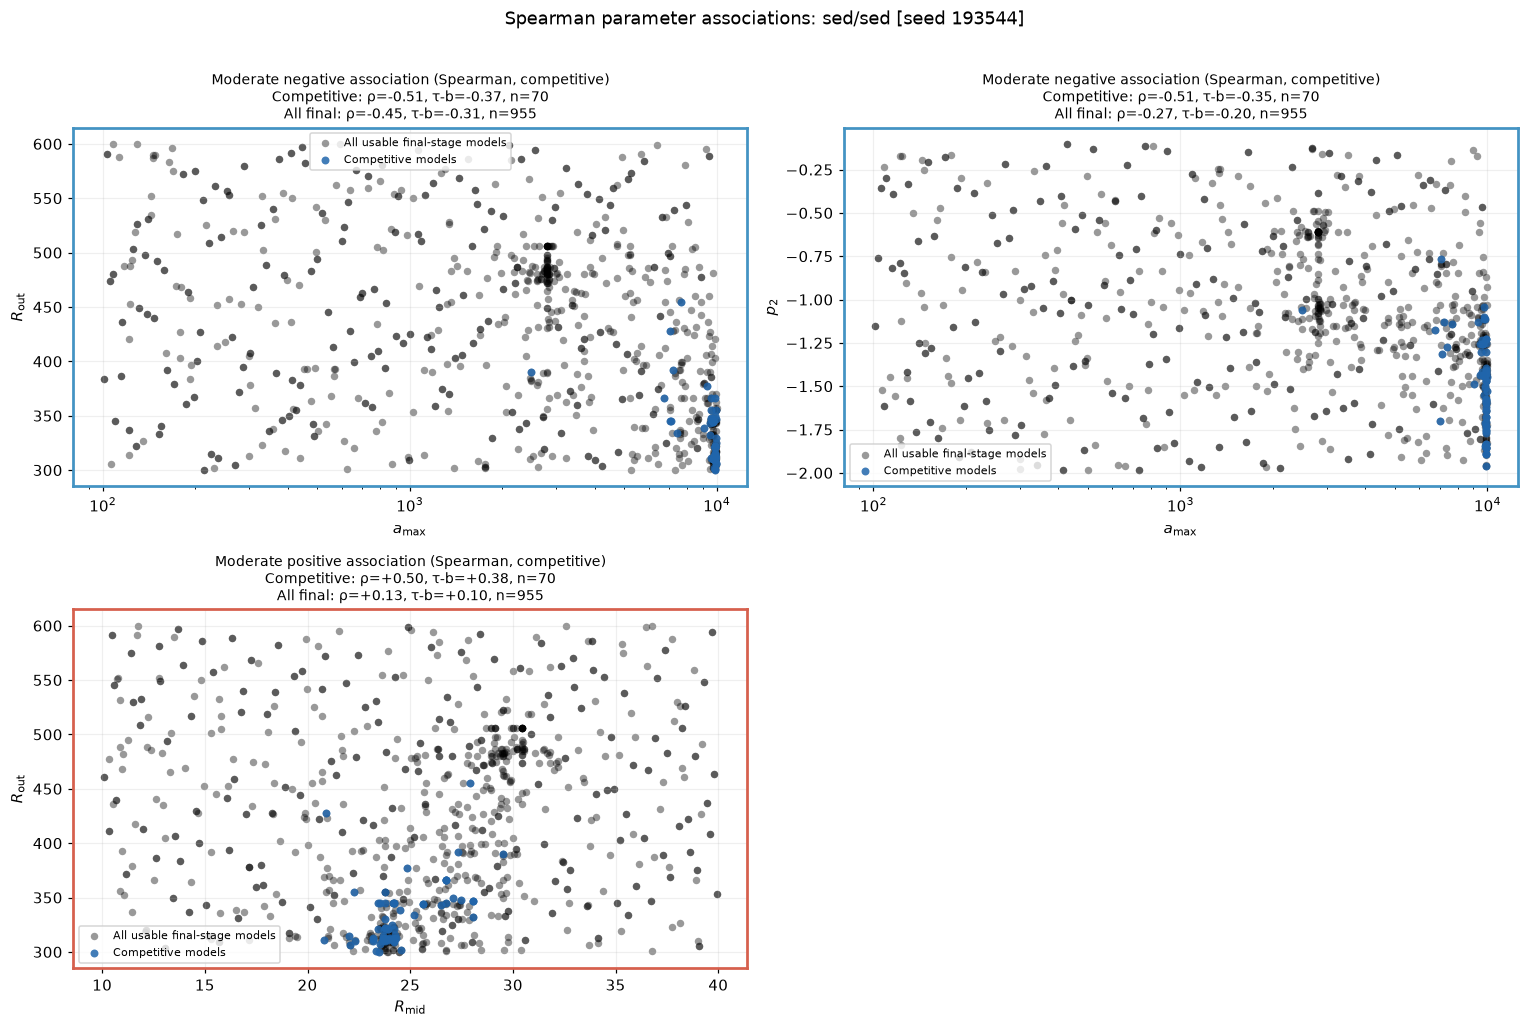

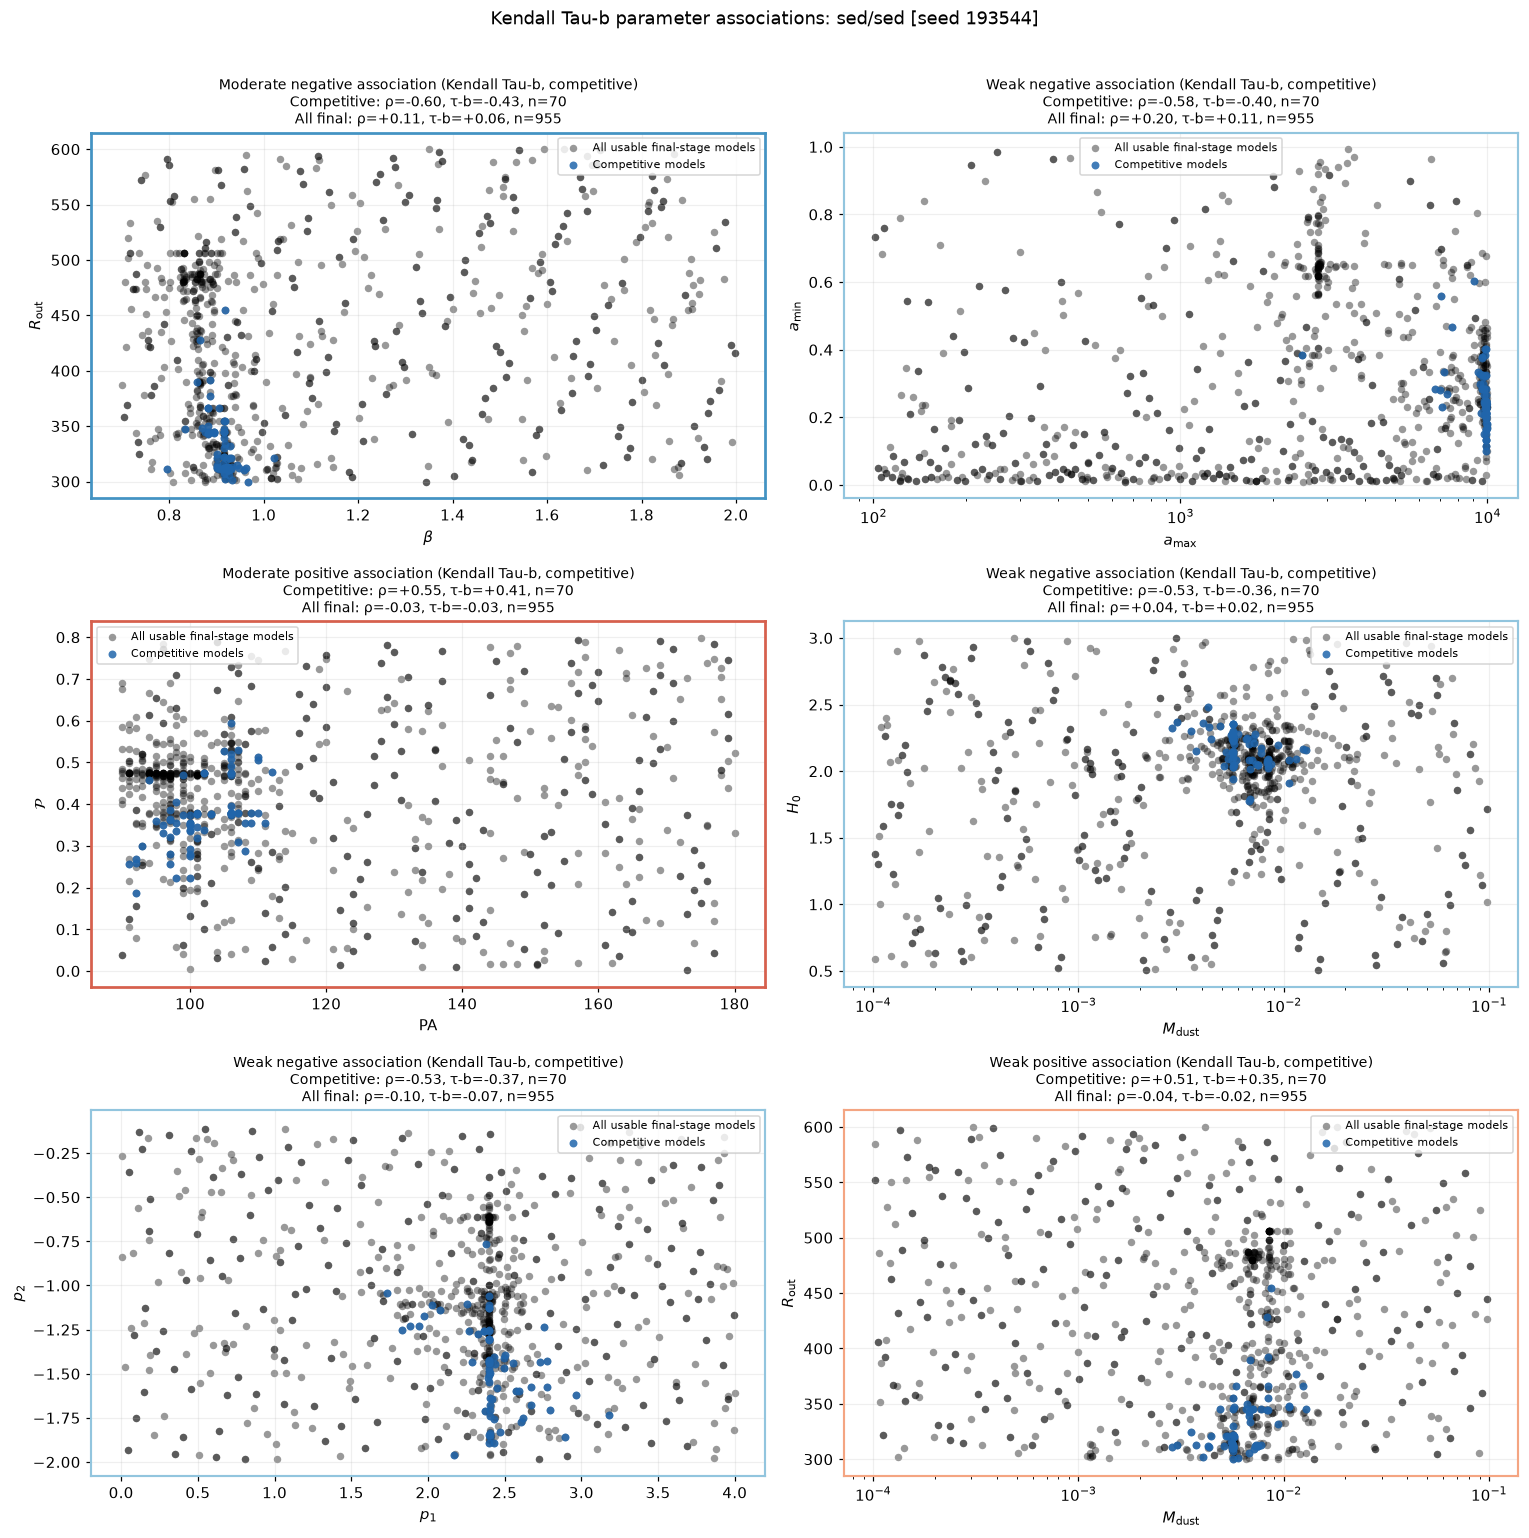

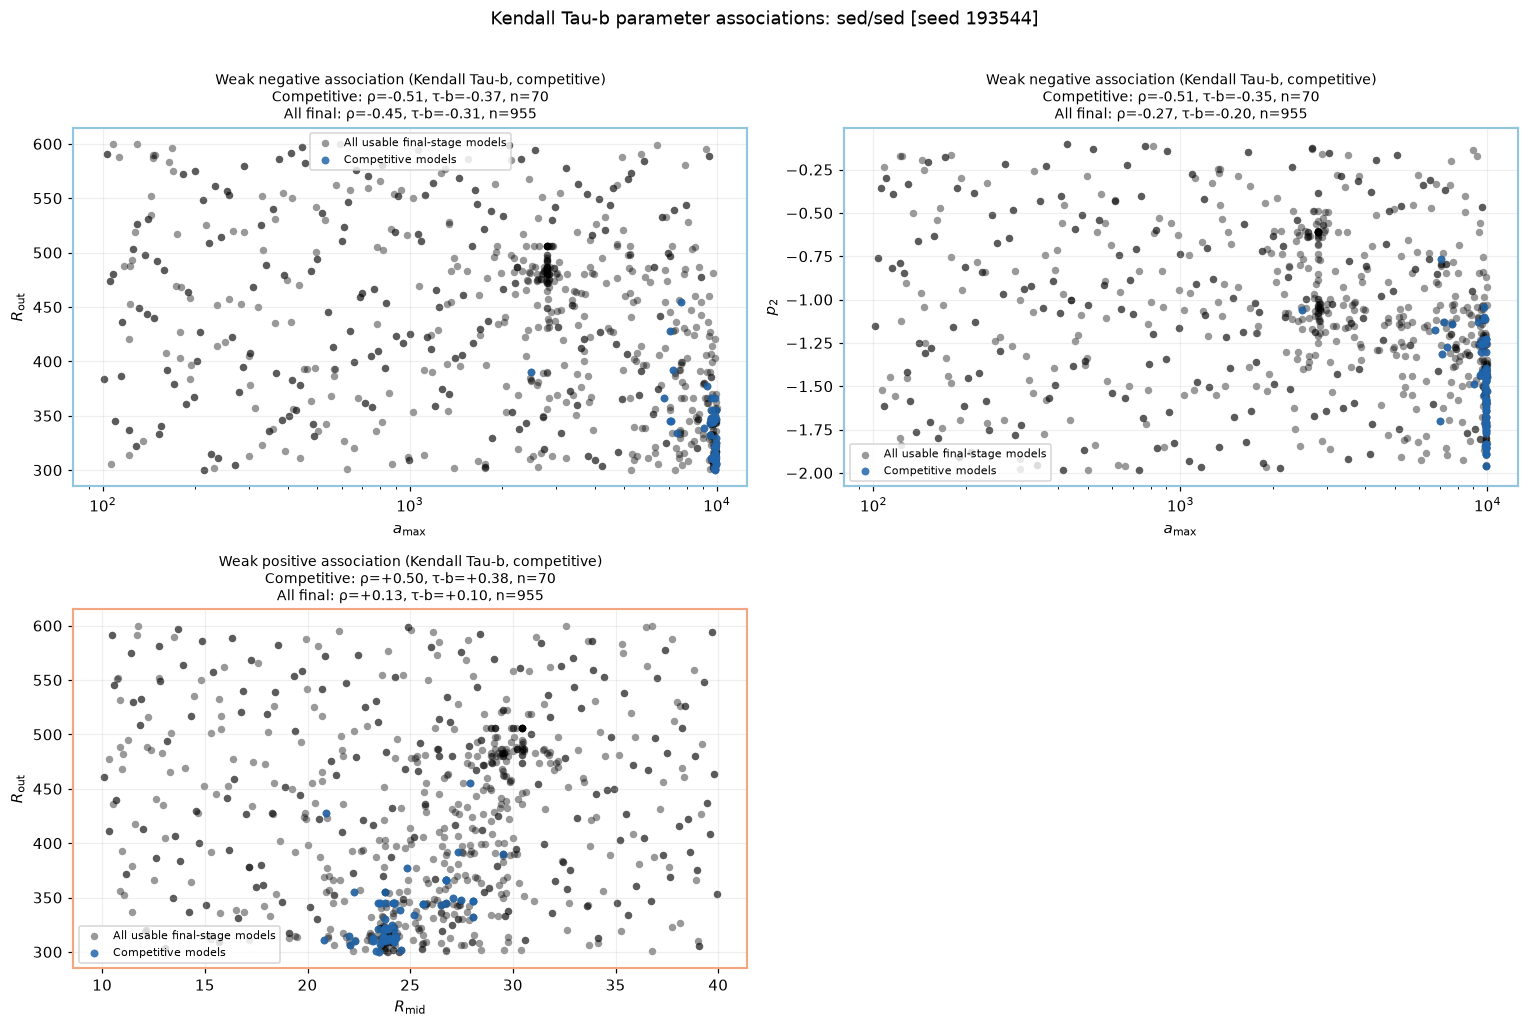

#### Shared parameter associations: sed/sed_alma [seed 769887]

No pairs meet the shared sample-count, variation and Spearman thresholds for this run.


#### Shared parameter associations: sed/sed_all_pdi_unres_corr [seed 358239]

No pairs meet the shared sample-count, variation and Spearman thresholds for this run.


In [39]:
# 2. Keep one shared Spearman-selected pair list per run; show both metric versions.
selected_pair_groups = []
rank_columns = ['parameter_x', 'parameter_y', f'level_{PAIR_SCOPE}', f'level_tau_b_{PAIR_SCOPE}',
                'n_competitive', 'rho_competitive', 'tau_b_competitive',
                'n_all_final', 'rho_all_final', 'tau_b_all_final', 'direct_configspace_constraint']
for group_index, ((history, objective), group) in enumerate(
        pair_analysis.groupby(['history', 'objective_key'], sort=False), start=1):
    display(Markdown(f'#### Shared parameter associations: {history}'))
    selected_for_run = select_parameter_pairs(
        group, scope=PAIR_SCOPE, min_abs_rho=PAIR_MIN_ABS_RHO,
        max_plots=PAIR_MAX_PER_HISTORY, max_per_history=PAIR_MAX_PER_HISTORY,
        include_constrained=PAIR_INCLUDE_CONSTRAINED)
    if selected_for_run.empty:
        print('No pairs meet the shared sample-count, variation and Spearman thresholds for this run.')
        continue
    selected_for_run['selection_metric'] = 'spearman'
    selected_pair_groups.append(selected_for_run)
    display(selected_for_run[rank_columns])
    if PAIR_PANELS_PER_FIGURE < 1:
        raise ValueError('PAIR_PANELS_PER_FIGURE must be positive.')
    for metric in PAIR_METRICS:
        run_figure_names = []
        suffix = '' if metric == 'spearman' else '_kendall_tau_b'
        for first in range(0, len(selected_for_run), PAIR_PANELS_PER_FIGURE):
            page = selected_for_run.iloc[first:first+PAIR_PANELS_PER_FIGURE]
            name = f'parameter_associations_{group_index:02d}{suffix}'
            if len(selected_for_run) > PAIR_PANELS_PER_FIGURE:
                name += f'_page_{first//PAIR_PANELS_PER_FIGURE+1:02d}'
            run_figure_names.append(name)
            show_figure(name, plot_selected_parameter_pairs(
                page, plot_evaluations, plotted_competitive, LOG_PARAMETERS, metric=metric))
        mask = ((pair_plot_index.history == history) & (pair_plot_index.objective_key == objective)
                & (pair_plot_index.metric == metric))
        pair_plot_index.loc[mask, 'association_panels'] = len(selected_for_run)
        pair_plot_index.loc[mask, 'association_figure'] = ', '.join(run_figure_names)
selected_pairs = (pd.concat(selected_pair_groups, ignore_index=True) if selected_pair_groups else
                  select_parameter_pairs(pair_analysis.iloc[:0], scope=PAIR_SCOPE))

### Competitive versus all-final models

Compare **the same final-stage pool within each history and observation objective**. Each configuration is represented by its lowest saved cost. The retained fraction measures how selective the current allowance is. ECDF overlays show parameter distributions with equal vertical scale despite different sample sizes; exported quantiles describe sampled values, not uncertainty intervals.

The pair comparison reports both sample sizes, both rank coefficients, `delta = competitive - all_final`, and sign reversals. Differences are masked unless both samples meet the existing eligibility screens. Inspect scatter plots before interpreting a large difference: curvature, clusters, boundaries, adaptive sampling and conditioning on cost can all contribute. Numeric categorical distributions are only meaningful if their order is physically meaningful.

Additional scatter and sensitivity panels use one fixed pair list per history/objective, ranked by the largest absolute change in either coefficient at the current allowance. Directly constrained pairs follow PAIR_INCLUDE_CONSTRAINED. Existing strength-selected panels remain available. Sensitivity varies the relative allowance while keeping ABSOLUTE_COST_ALLOWANCE fixed; the effective thresholds and retained fractions are exported. Gaps indicate insufficient/invalid samples, not zero correlation. Pairs with inadequate competitive samples stay in the audit but are not ranked for plots.

These nested samples are dependent. Differences and threshold curves are descriptive, not significance tests, posterior correlations or confidence intervals. Check whether conclusions recur across independent optimiser histories.


,history,objective_key,products,n_all_final,n_competitive,retained_fraction,best_cost,max_competitive_cost
0,sed/sed [seed 193544],SED,sed,955,70,0.073298,14.735357,22.024624
1,sed/sed_alma [seed 769887],SED+ALMA,"alma, sed",448,76,0.169643,41.247217,61.650149
2,sed/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA","alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",99,4,0.040404,2594.729040,3743.902570


,history,objective_key,parameter,n_all_final,min_all_final,q10_all_final,median_all_final,q90_all_final,max_all_final,n_competitive,min_competitive,q10_competitive,median_competitive,q90_competitive,max_competitive
0,sed/sed [seed 193544],SED,alpha_viscosity,955,0.000010,0.000010,0.000100,0.100000,0.100000,70,0.000100,0.000100,0.001000,0.010000,0.100000
1,sed/sed [seed 193544],SED,disk_Rmid,955,10.095064,15.314954,25.790602,34.544475,39.920795,70,20.812238,23.181789,23.922268,27.122341,29.519159
2,sed/sed [seed 193544],SED,disk_pa,955,90.000000,94.000000,107.000000,164.000000,180.000000,70,91.000000,95.900000,101.000000,108.100000,112.000000
3,sed/sed [seed 193544],SED,disk_total_dust_mass,955,0.000102,0.000320,0.005779,0.023890,0.098218,70,0.002869,0.004400,0.005665,0.008436,0.012876
4,sed/sed [seed 193544],SED,inclination,955,0.000000,8.000000,40.000000,49.000000,50.000000,70,26.000000,42.800000,45.000000,48.000000,50.000000
5,sed/sed [seed 193544],SED,zone_1_Rin,955,5.000910,5.678823,6.496542,9.069295,9.998135,70,5.537616,5.750362,5.998786,7.110201,7.951866
6,sed/sed [seed 193544],SED,zone_1_flaring_exp,955,0.700006,0.828368,0.936360,1.725708,1.997025,70,0.794603,0.881002,0.916013,0.932123,1.021554
7,sed/sed [seed 193544],SED,zone_1_scale_height,955,0.504319,0.926664,2.065542,2.551740,2.999534,70,1.775209,2.034752,2.153879,2.335691,2.480925
8,sed/sed [seed 193544],SED,zone_1_species_1_Vmax,955,0.600405,0.631086,0.712142,0.845691,0.898836,70,0.604898,0.631552,0.647640,0.681698,0.728060
9,sed/sed [seed 193544],SED,zone_1_species_1_aexp,955,2.005294,2.447449,2.949251,3.993964,4.491317,70,2.867176,2.908939,2.948575,2.967779,2.979677


,history,objective_key,parameter_x,parameter_y,n_all_final,n_competitive,both_eligible,rho_all_final,rho_competitive,delta_rho,sign_flip_rho,tau_b_all_final,tau_b_competitive,delta_tau_b,sign_flip_tau_b,reason_all_final,reason_competitive,direct_configspace_constraint
45,sed/sed [seed 193544],SED,disk_pa,zone_2_Rc,955,70,True,0.522352,-0.284364,-0.806716,True,0.352290,-0.197961,-0.550252,True,eligible,eligible,False
36,sed/sed [seed 193544],SED,disk_pa,zone_1_flaring_exp,955,70,True,0.417472,-0.385345,-0.802817,True,0.293204,-0.291673,-0.584877,True,eligible,eligible,False
248,sed/sed_alma [seed 769887],SED+ALMA,zone_1_flaring_exp,zone_2_Rc,448,76,True,0.525991,-0.273059,-0.799050,True,0.354271,-0.190464,-0.544735,True,eligible,eligible,False
126,sed/sed [seed 193544],SED,zone_1_species_1_amax,zone_1_species_1_component_2_volume_fraction_iron,955,70,True,0.314797,-0.466894,-0.781691,True,0.239526,-0.394021,-0.633548,True,eligible,eligible,False
125,sed/sed [seed 193544],SED,zone_1_species_1_amax,zone_1_species_1_amin,955,70,True,0.195120,-0.575135,-0.770256,True,0.109732,-0.399683,-0.509415,True,eligible,eligible,False
90,sed/sed [seed 193544],SED,zone_1_flaring_exp,zone_1_species_1_amax,955,70,True,-0.289212,0.478227,0.767439,True,-0.171790,0.327414,0.499204,True,eligible,eligible,False
129,sed/sed [seed 193544],SED,zone_1_species_1_amax,zone_2_Rc,955,70,True,-0.492211,0.262424,0.754635,True,-0.322566,0.175417,0.497983,True,eligible,eligible,False
109,sed/sed [seed 193544],SED,zone_1_species_1_Vmax,zone_1_species_1_amax,955,70,True,-0.405054,0.314946,0.720000,True,-0.277023,0.233752,0.510775,True,eligible,eligible,False
216,sed/sed_alma [seed 769887],SED+ALMA,inclination,zone_1_flaring_exp,448,76,True,-0.579961,0.132742,0.712703,True,-0.395619,0.106547,0.502166,True,eligible,eligible,False
96,sed/sed [seed 193544],SED,zone_1_flaring_exp,zone_2_Rout,955,70,True,0.112495,-0.595112,-0.707606,True,0.063758,-0.431736,-0.495494,True,eligible,eligible,False


,history,objective_key,relative_allowance,absolute_allowance,cost_threshold,n_all_final,n_competitive,retained_fraction
0,sed/sed [seed 193544],SED,0.10,0.0,16.208893,955,3,0.003141
1,sed/sed_alma [seed 769887],SED+ALMA,0.10,0.0,45.371939,448,5,0.011161
2,sed/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",0.10,0.0,2854.201944,99,1,0.010101
3,sed/sed [seed 193544],SED,0.25,0.0,18.419196,955,24,0.025131
4,sed/sed_alma [seed 769887],SED+ALMA,0.25,0.0,51.559021,448,34,0.075893
5,sed/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",0.25,0.0,3243.411300,99,1,0.010101
6,sed/sed [seed 193544],SED,0.50,0.0,22.103035,955,70,0.073298
7,sed/sed_alma [seed 769887],SED+ALMA,0.50,0.0,61.870825,448,76,0.169643
8,sed/sed_all_pdi_unres_corr [seed 358239],"SED+INT(band)+PDI(V,I,H)+ALMA",0.50,0.0,3892.093560,99,4,0.040404
9,sed/sed [seed 193544],SED,1.00,0.0,29.470714,955,204,0.213613


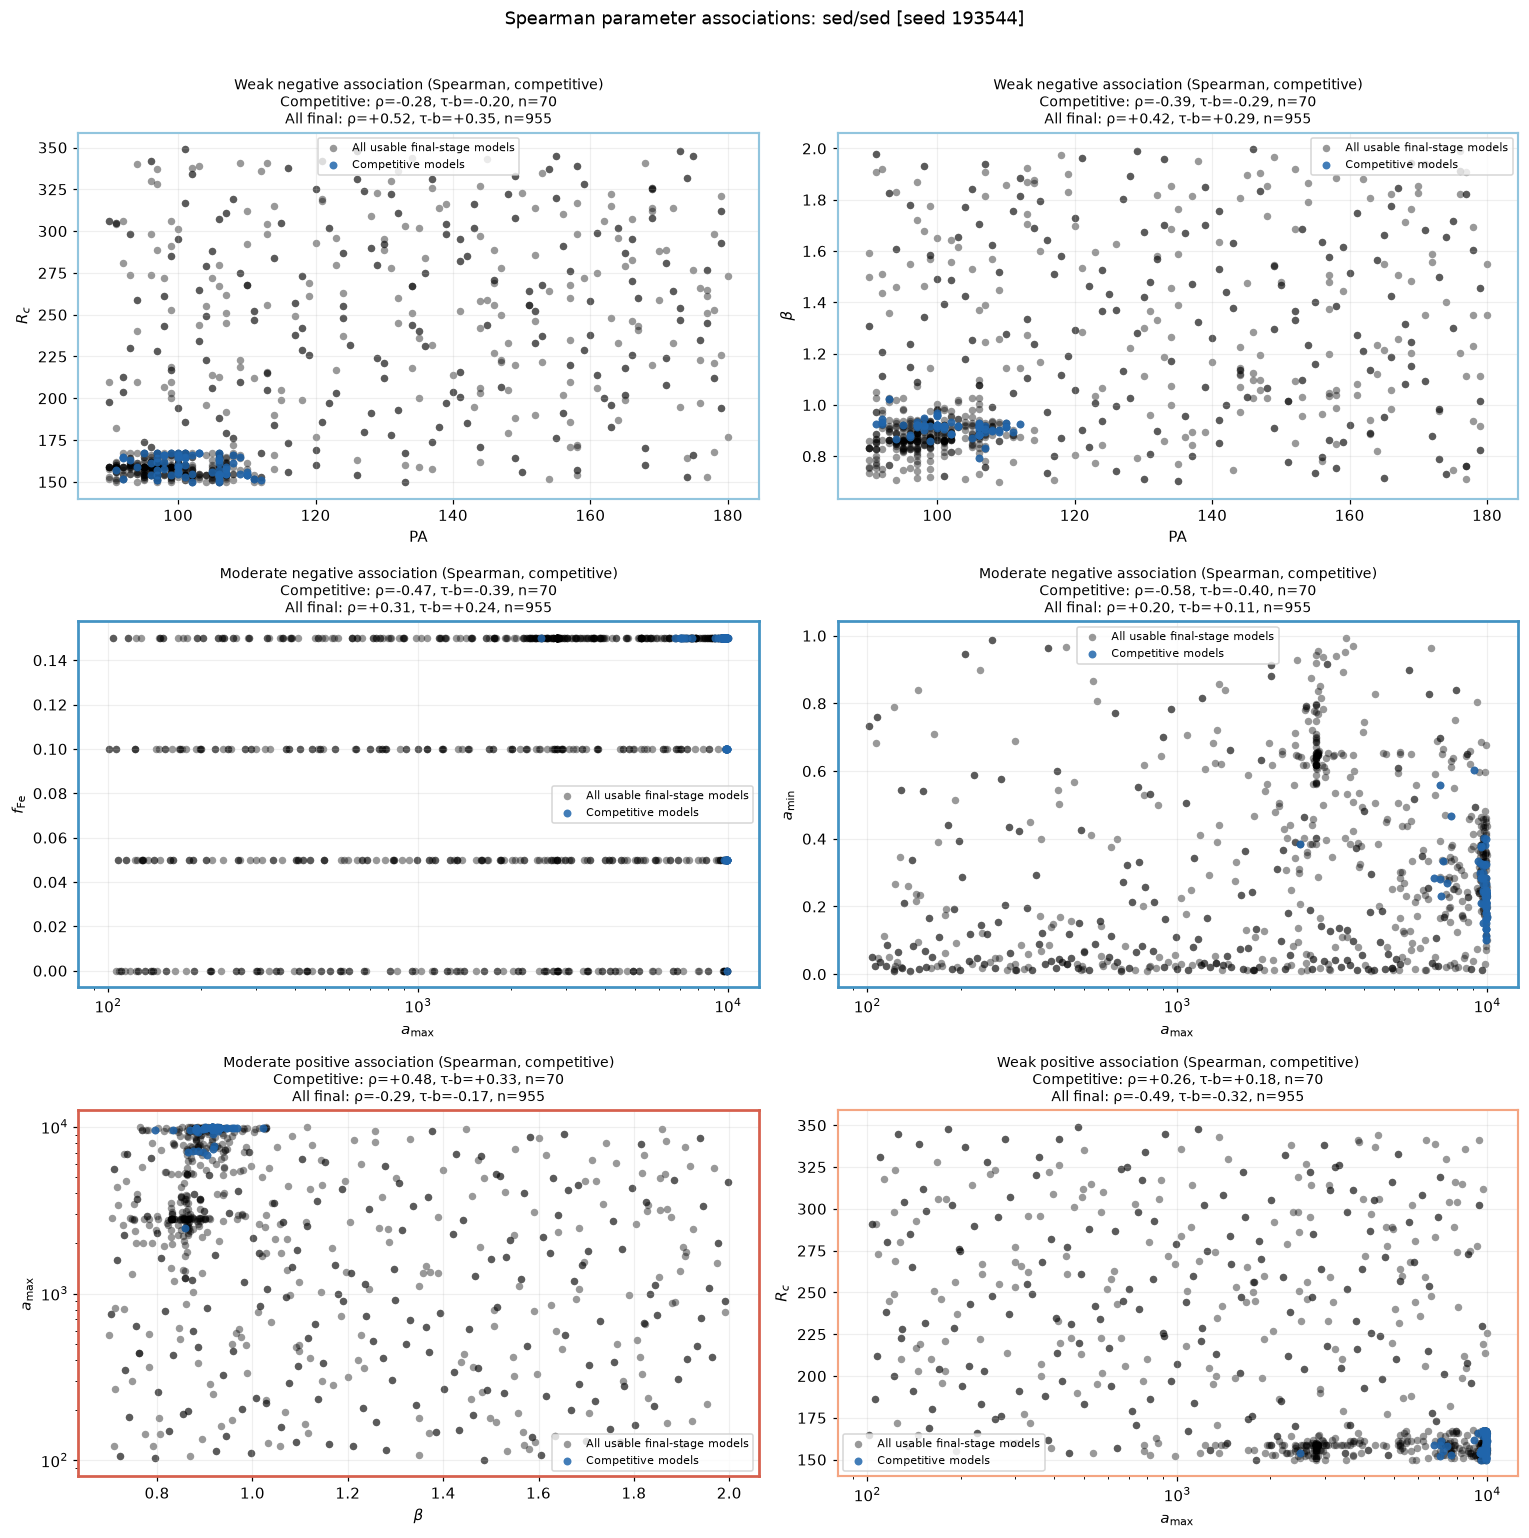

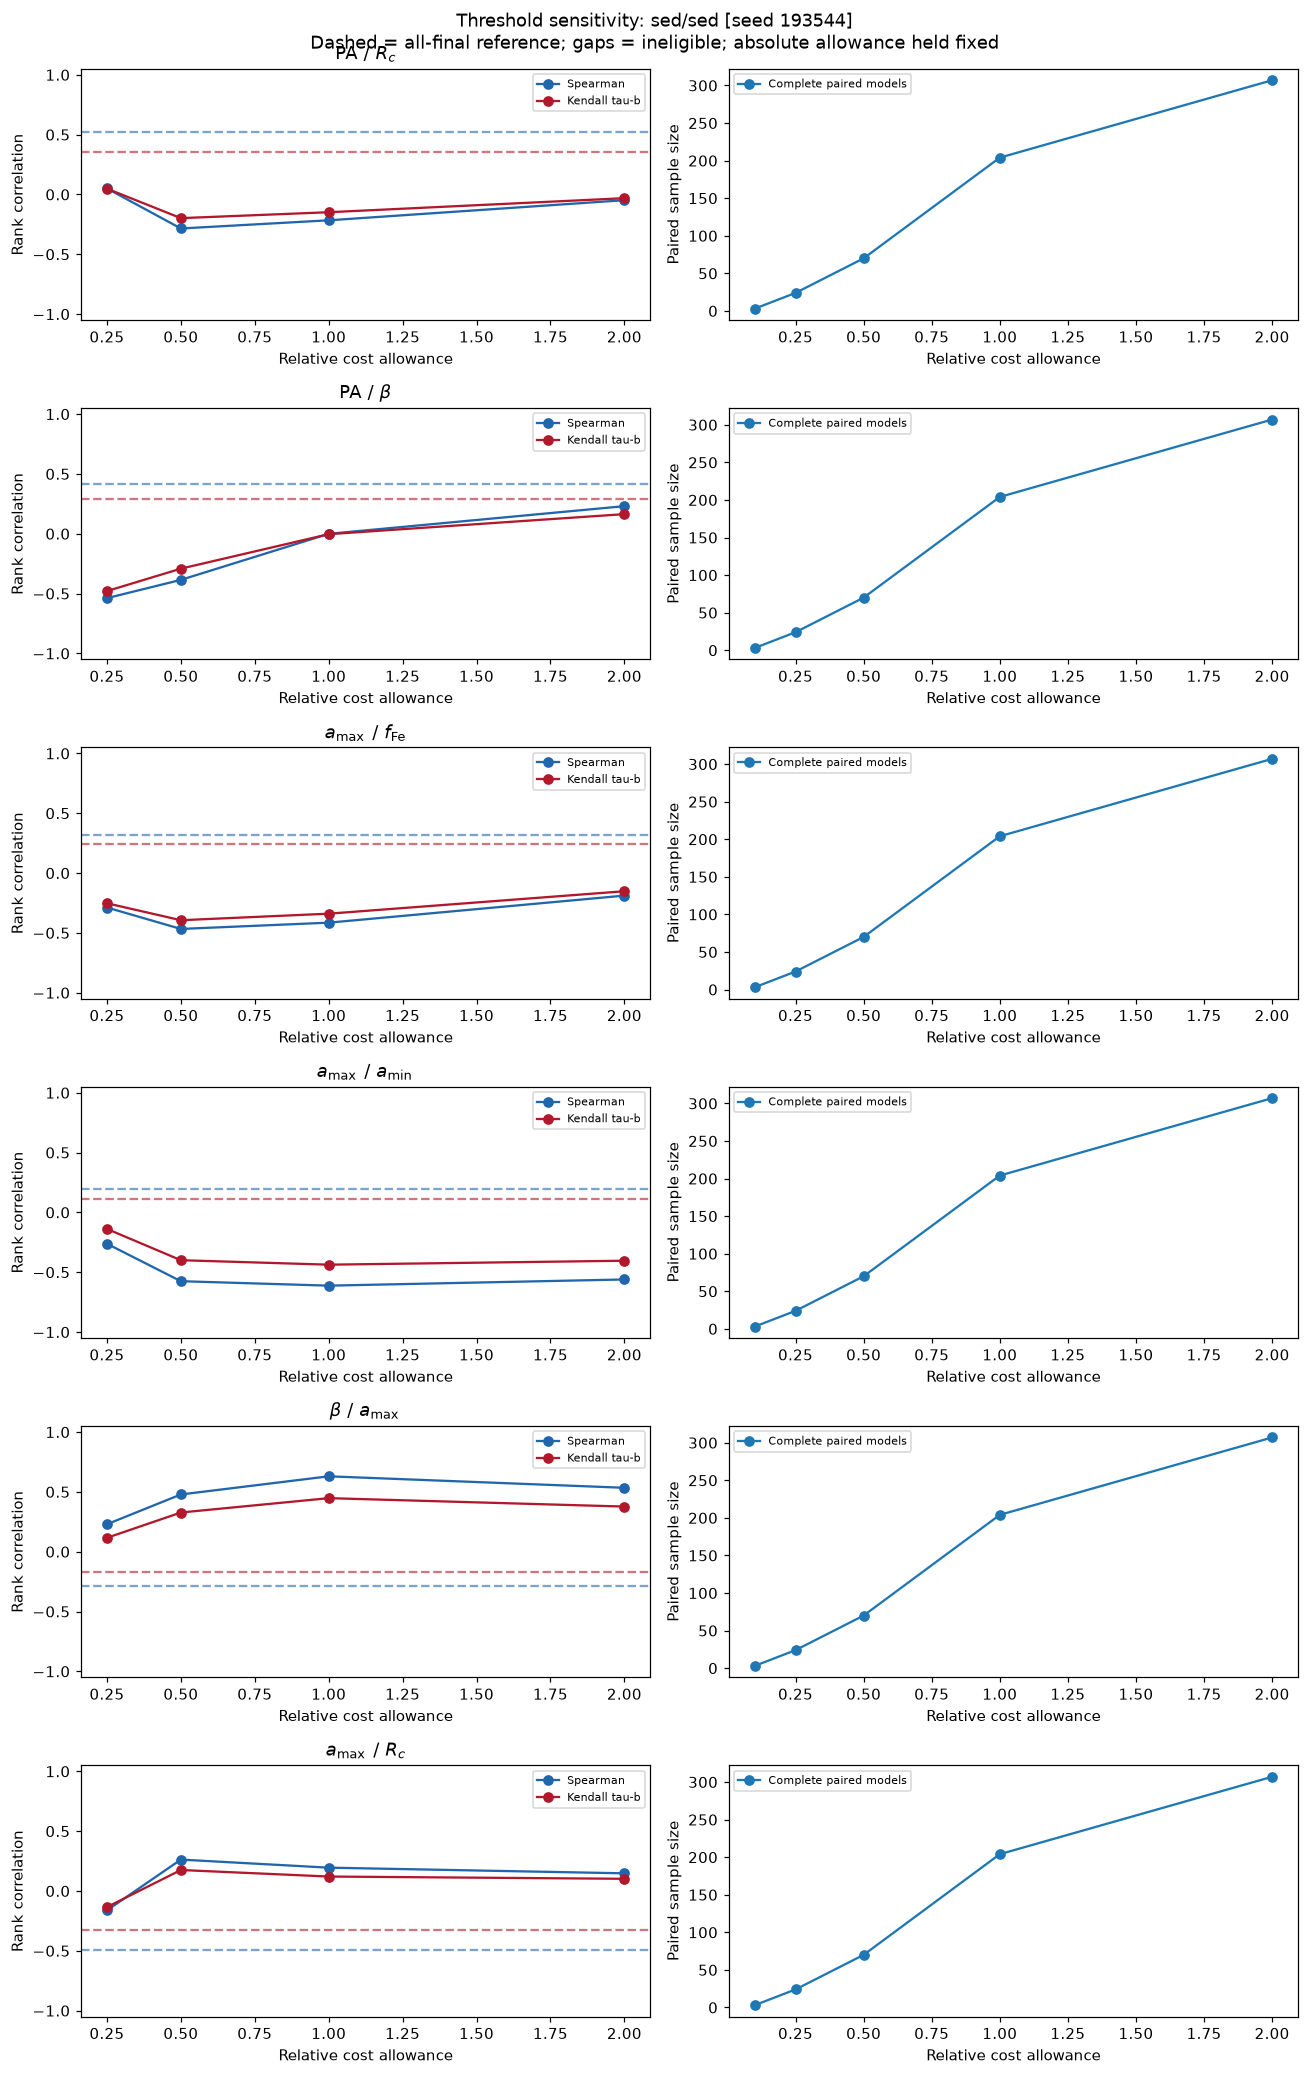

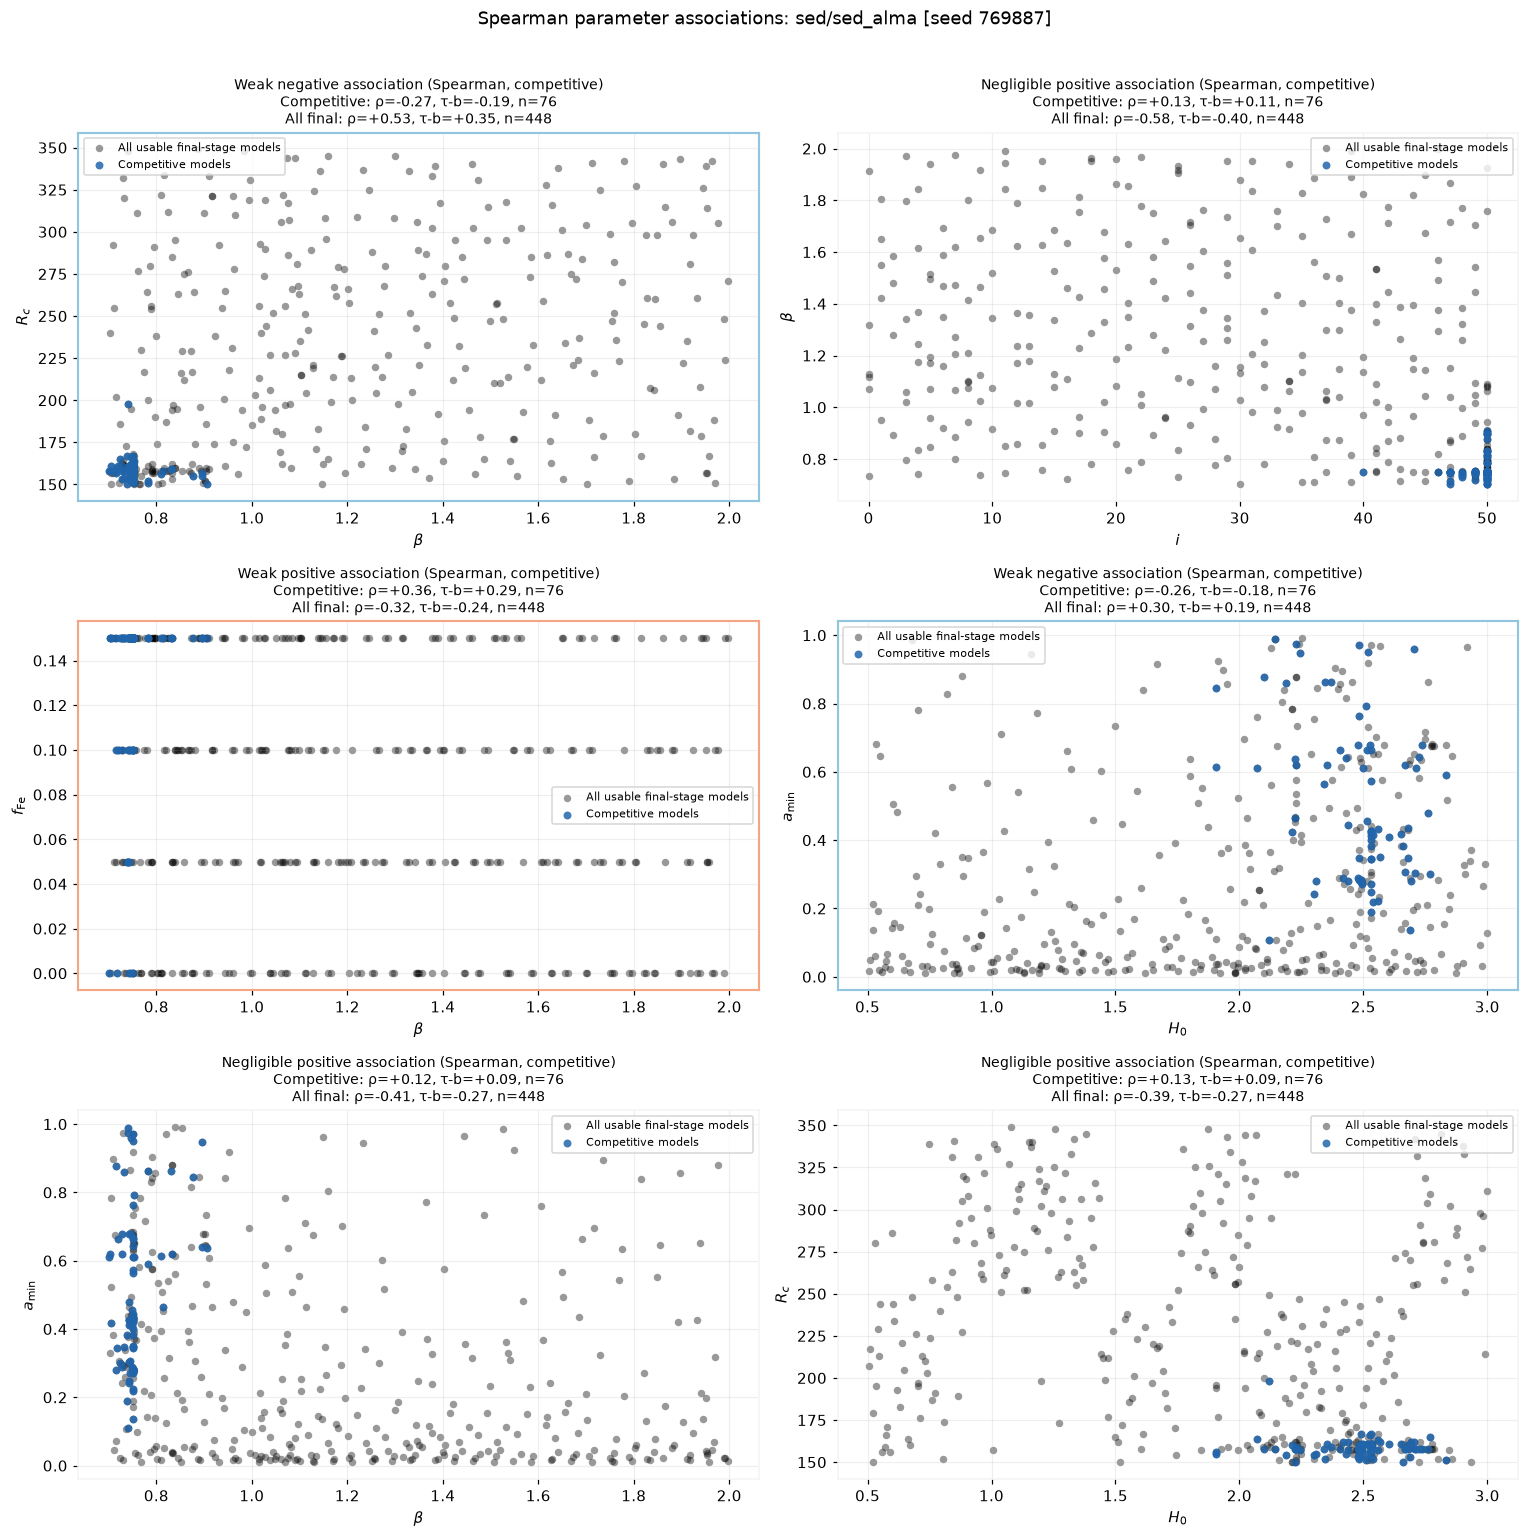

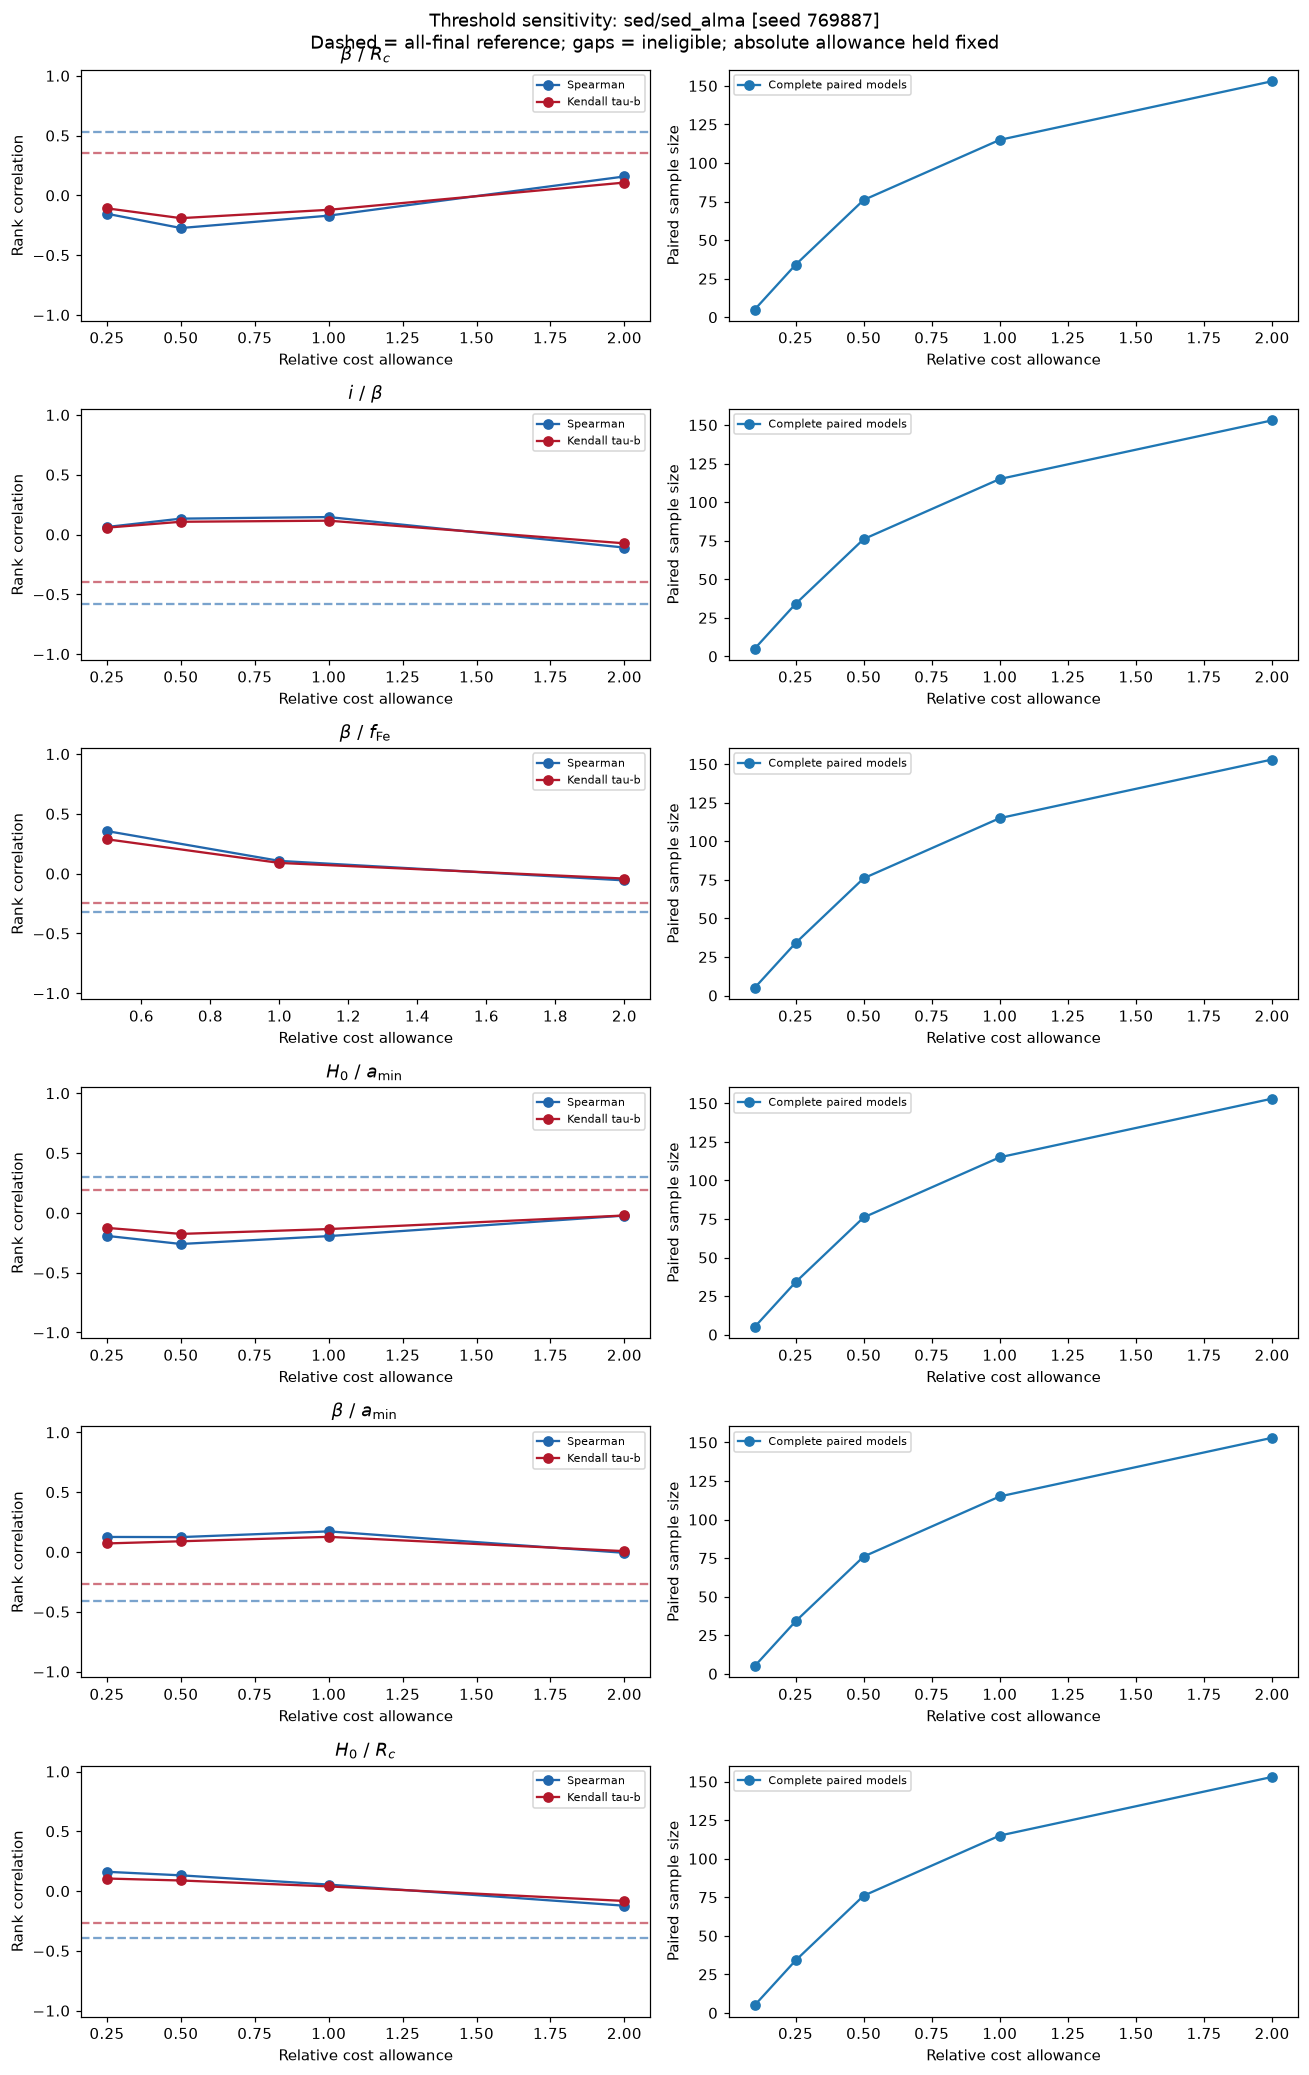

sed/sed_all_pdi_unres_corr [seed 358239]: no eligible pairs for comparison plots; inspect sample counts and reasons.


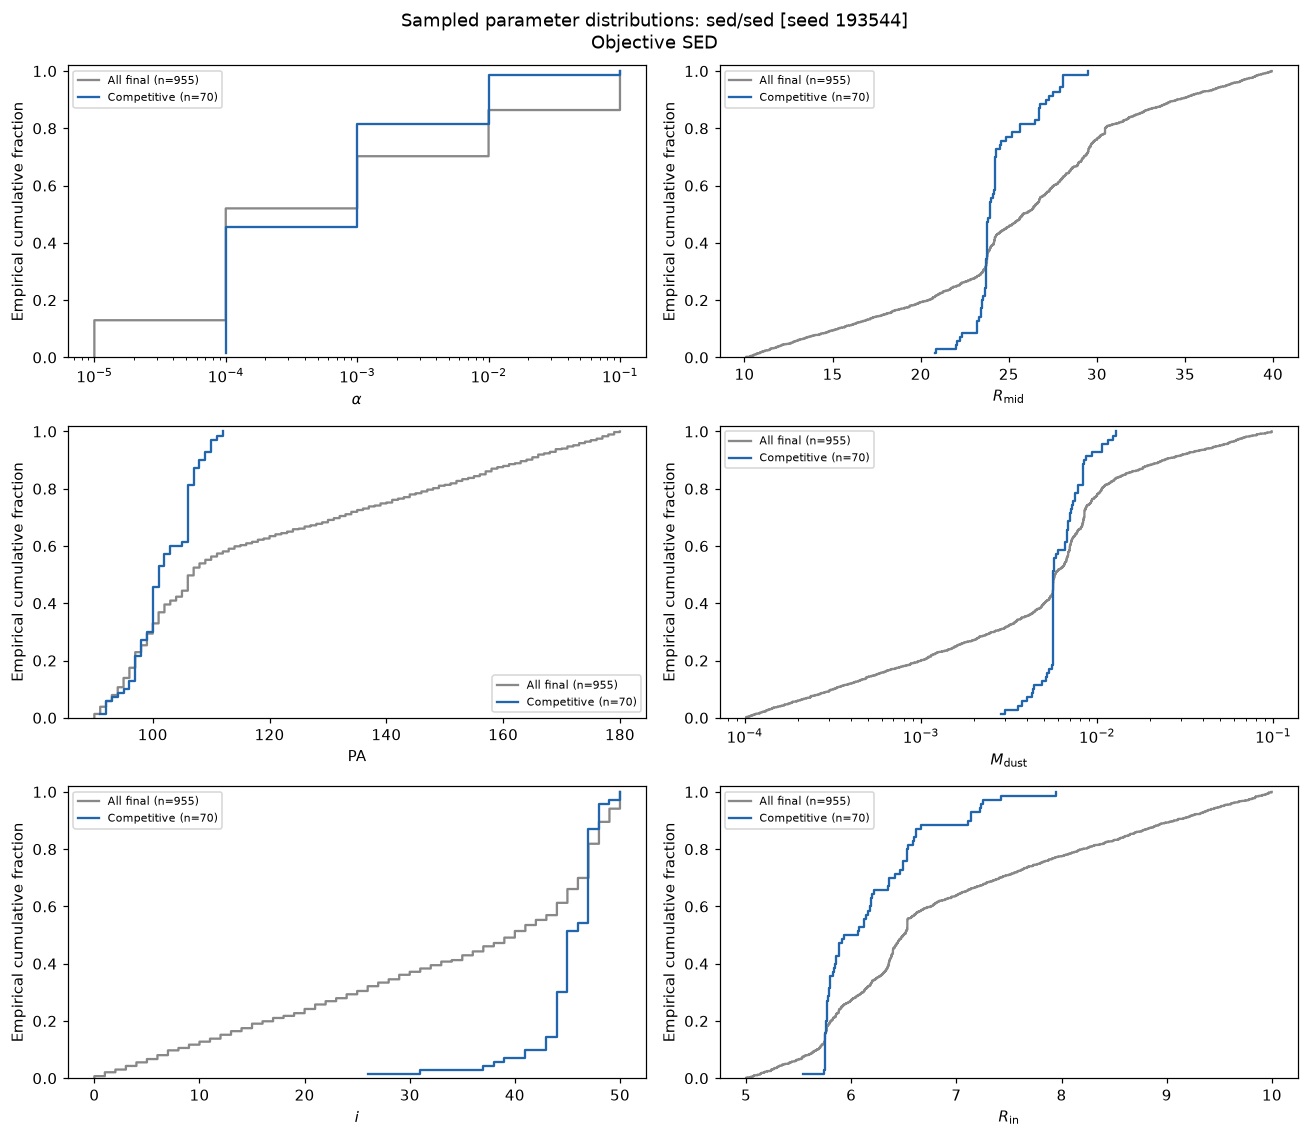

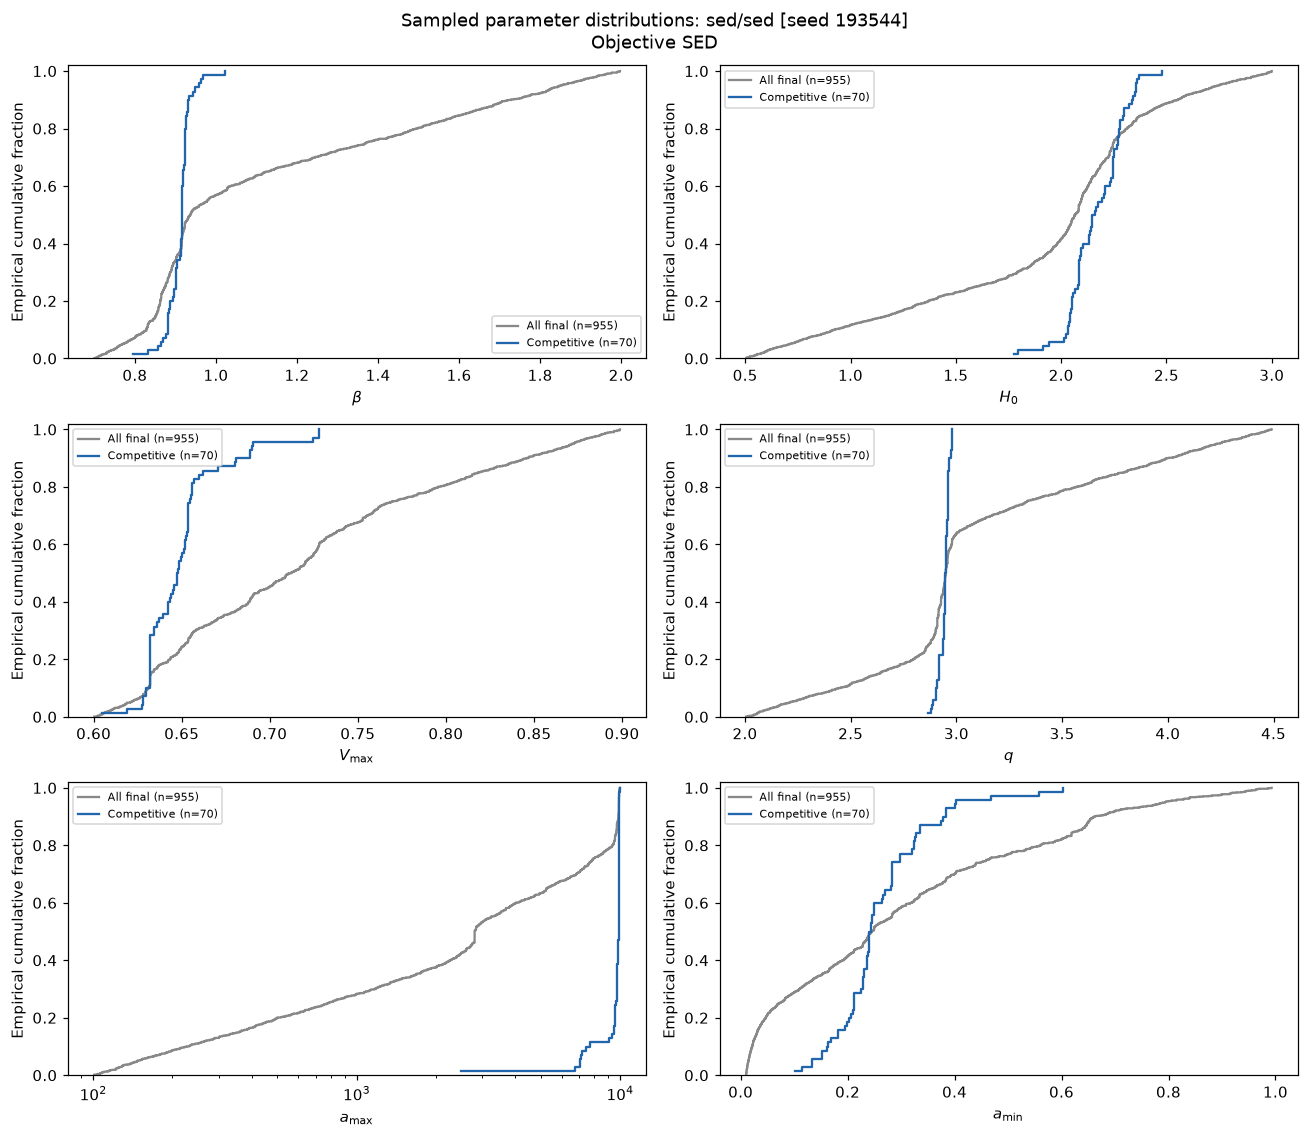

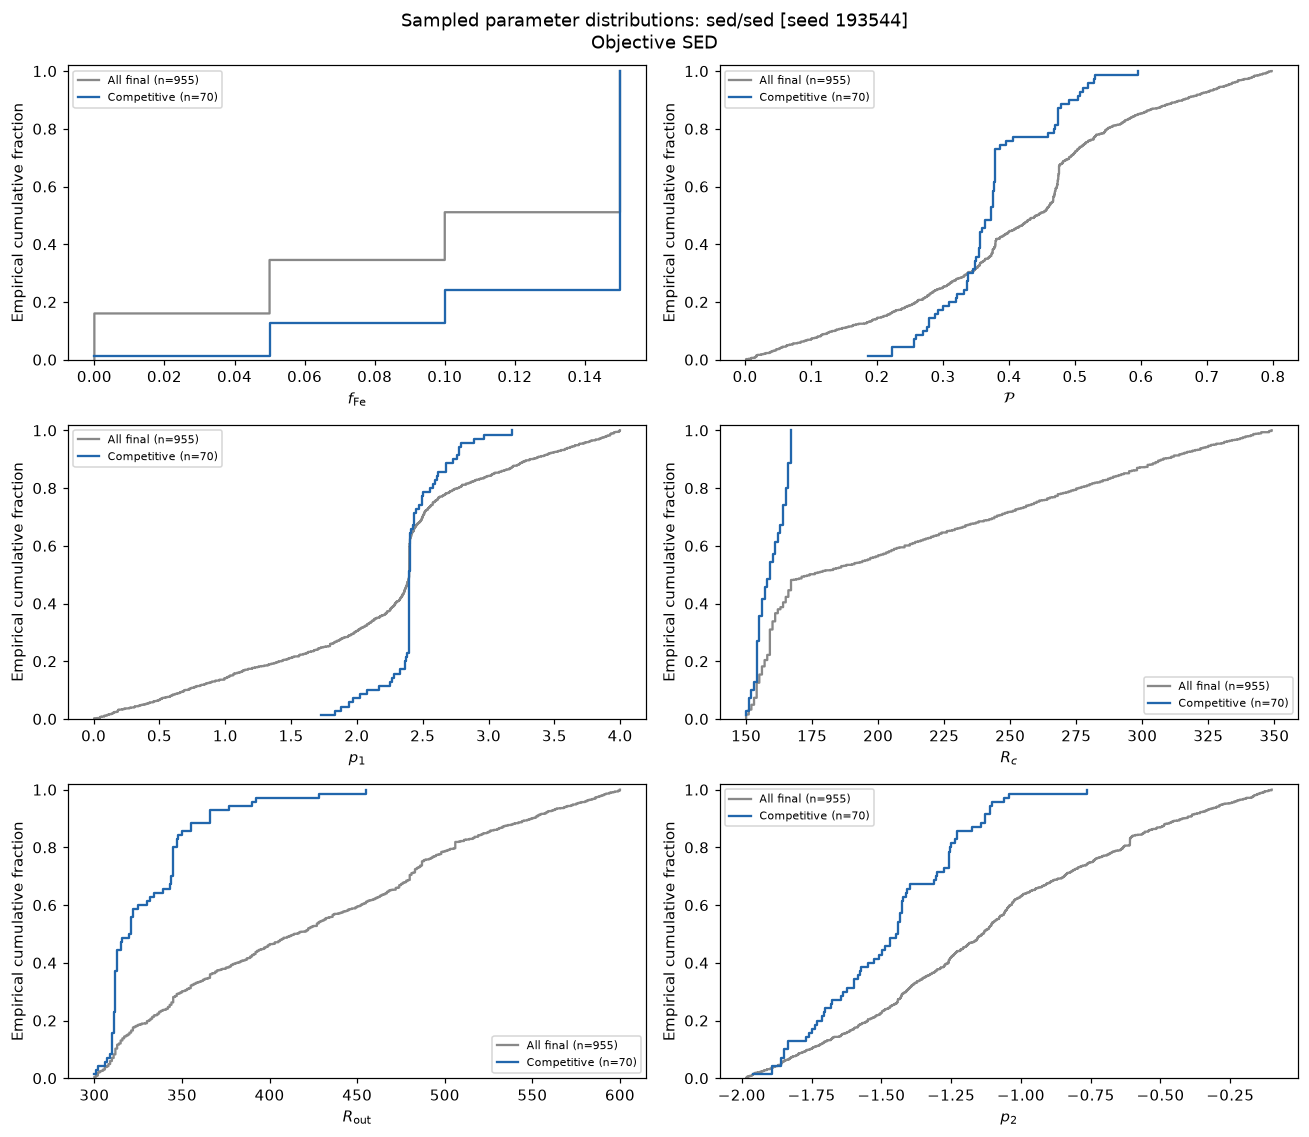

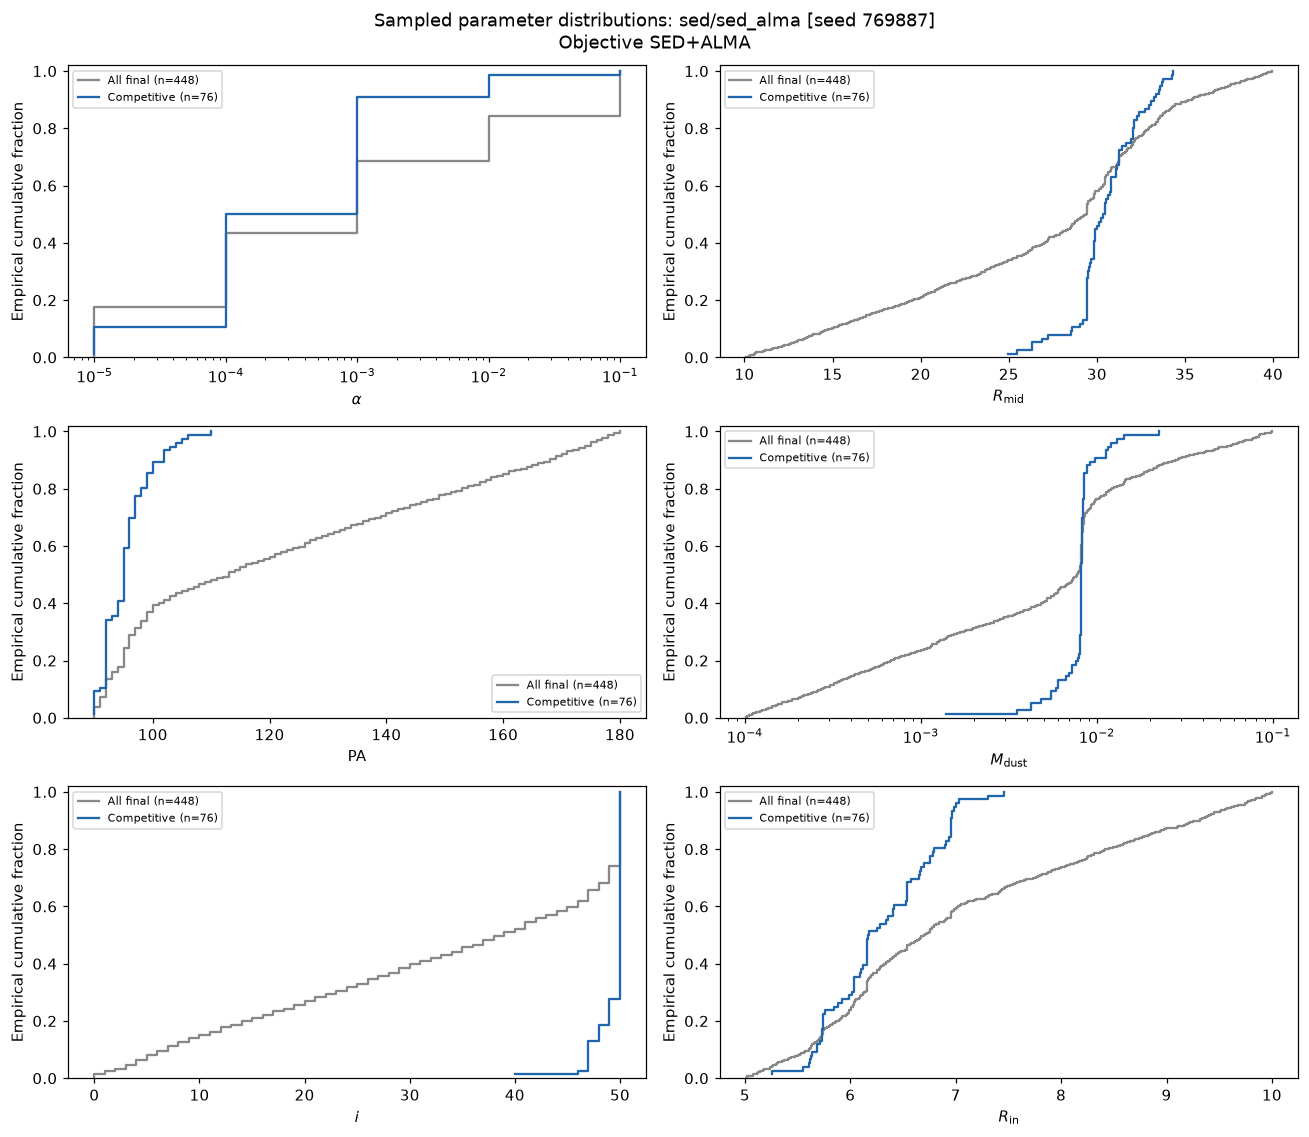

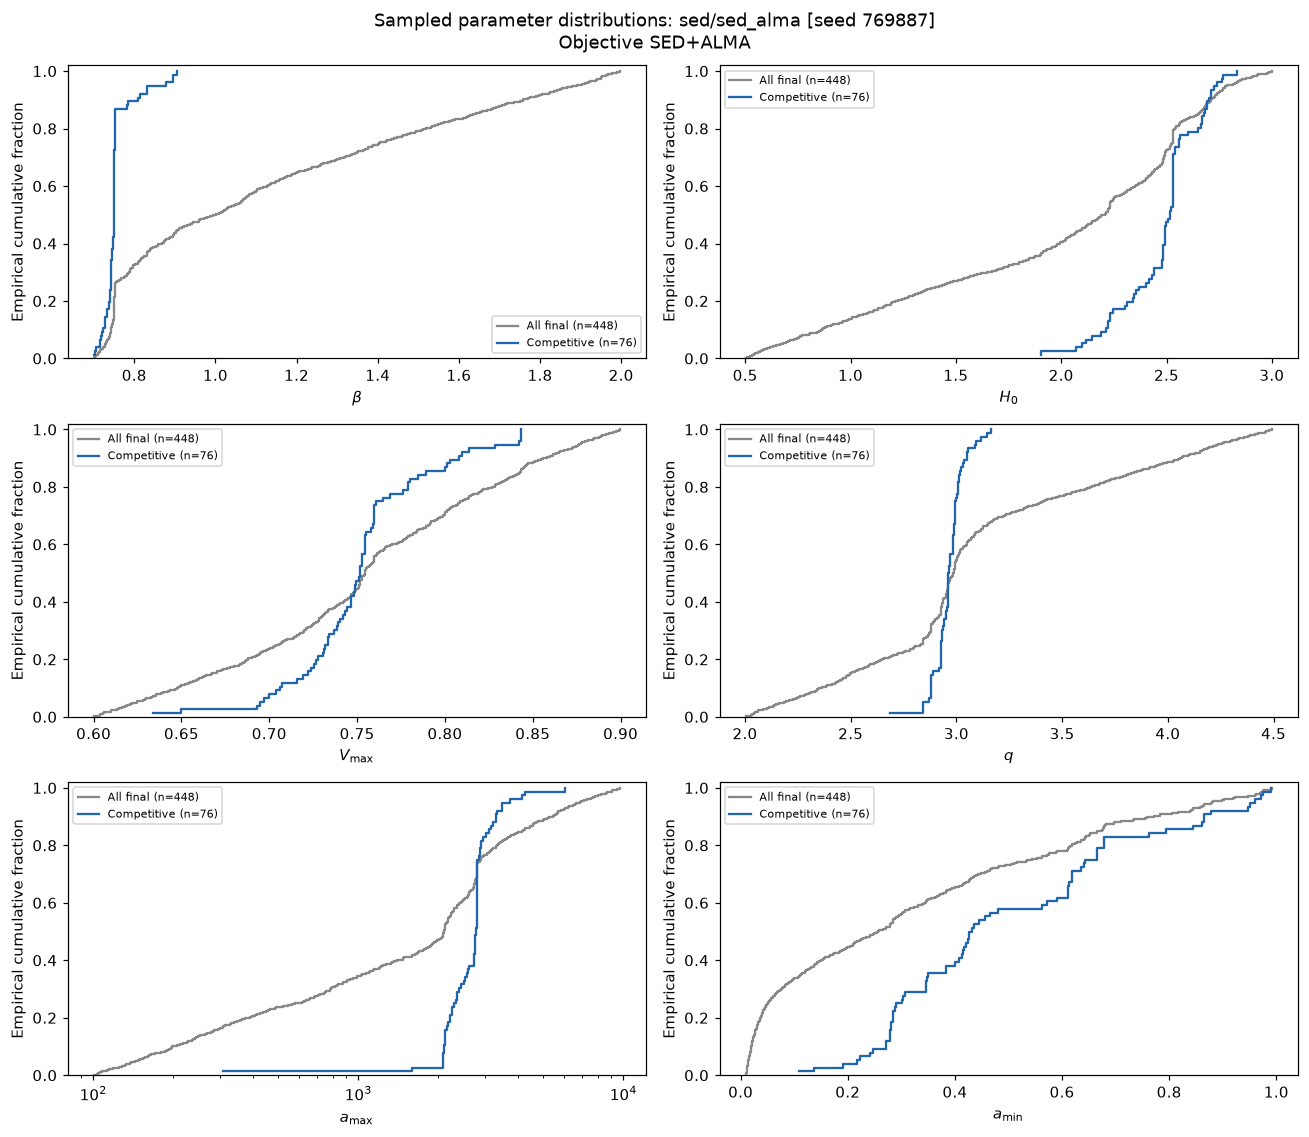

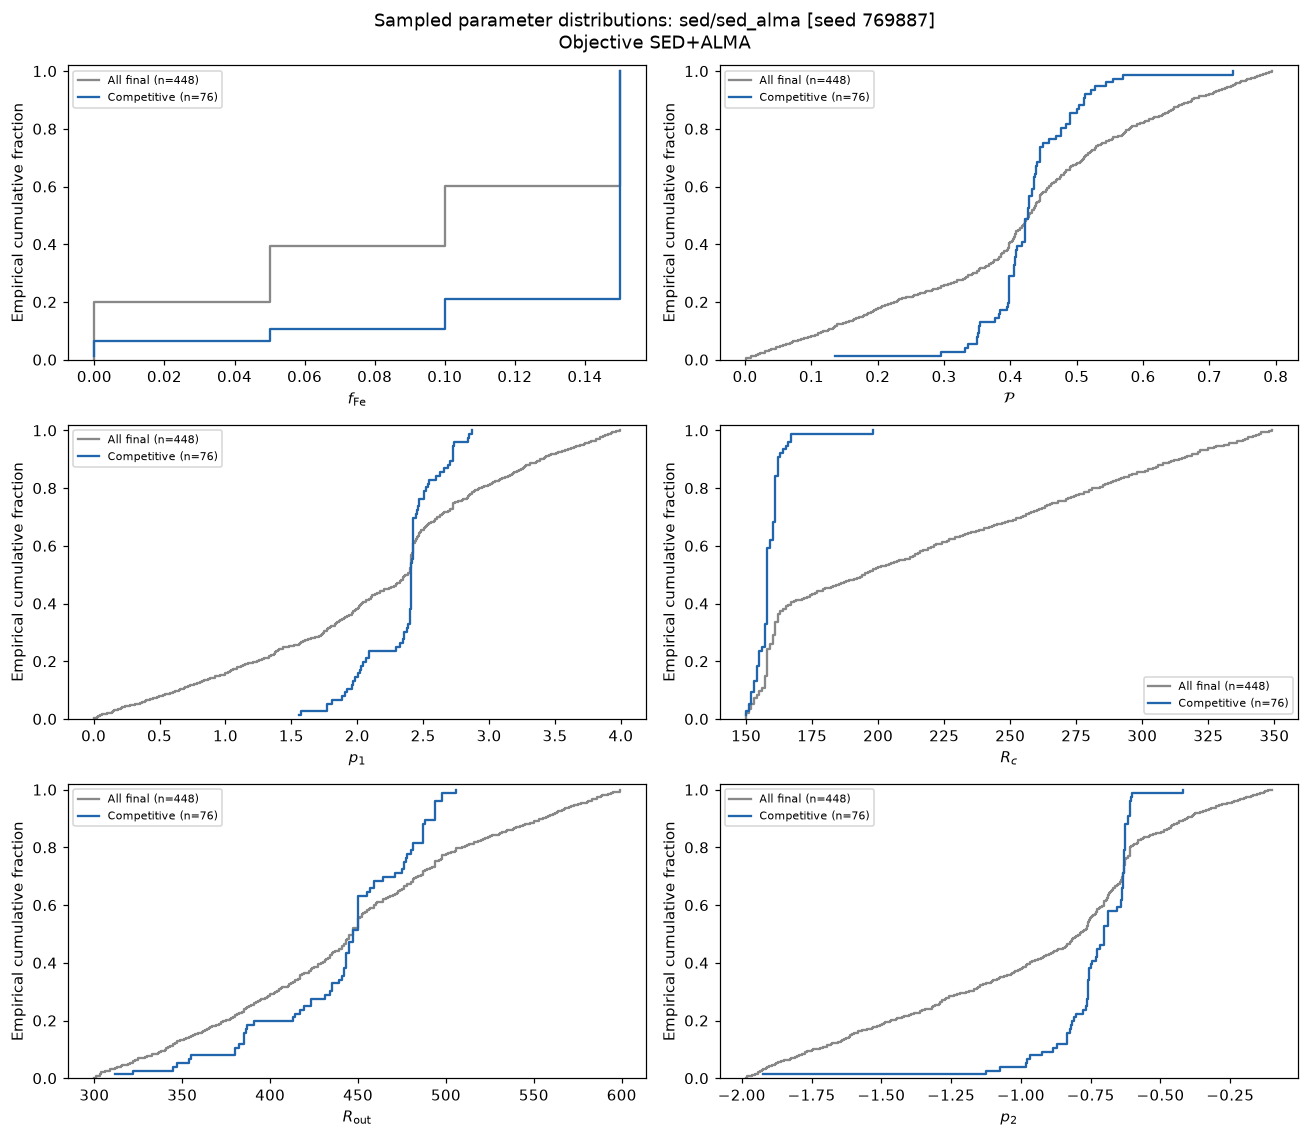

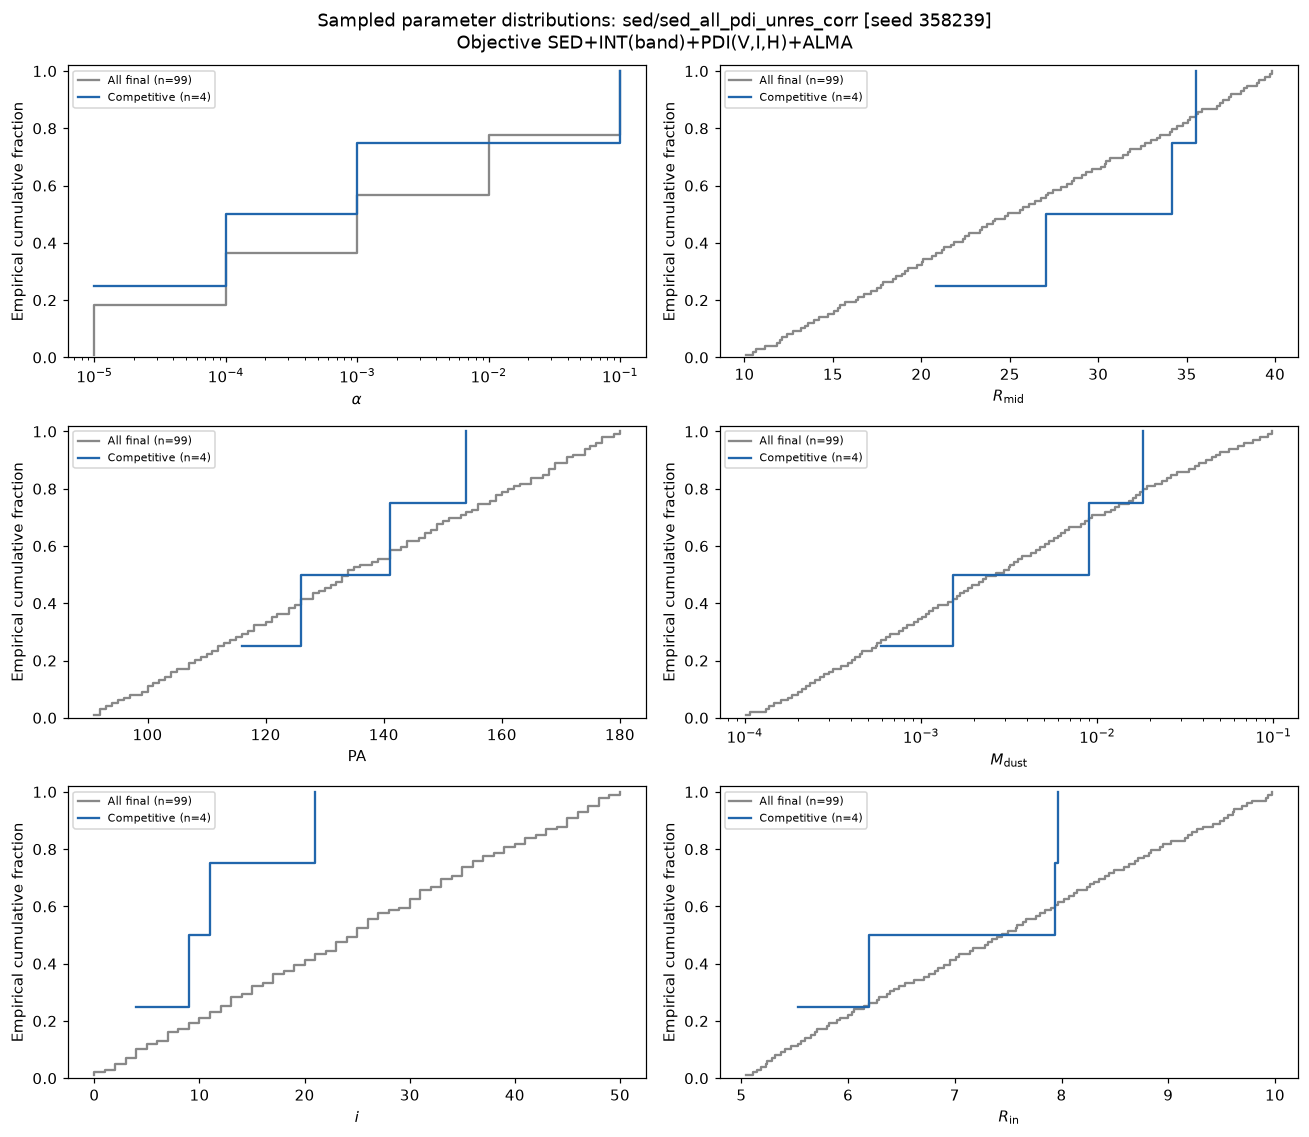

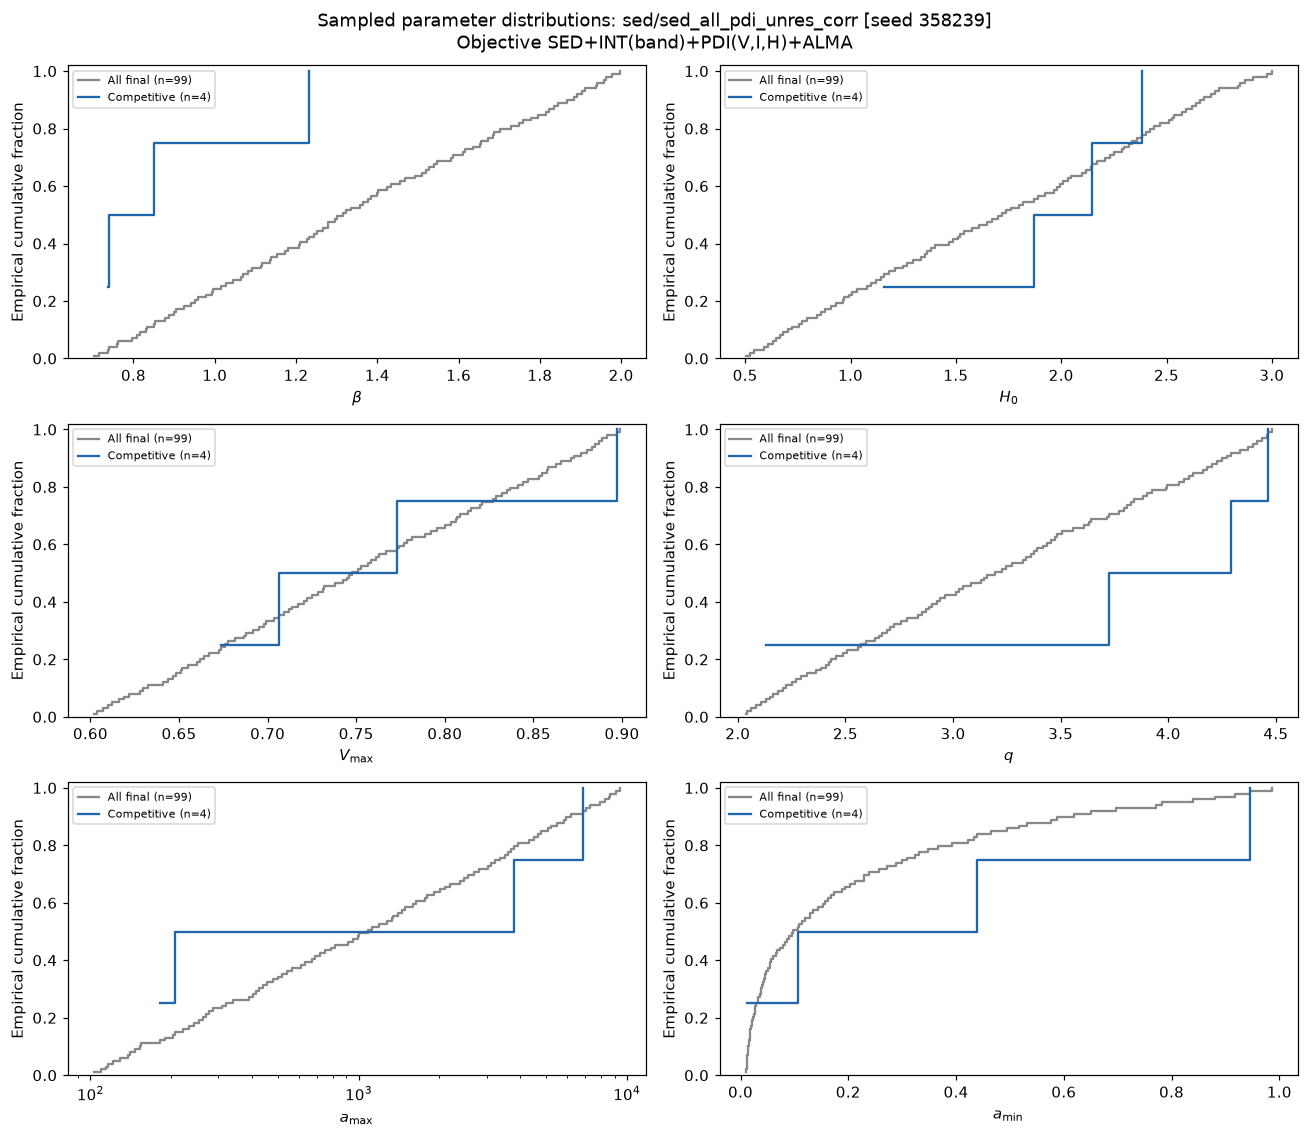

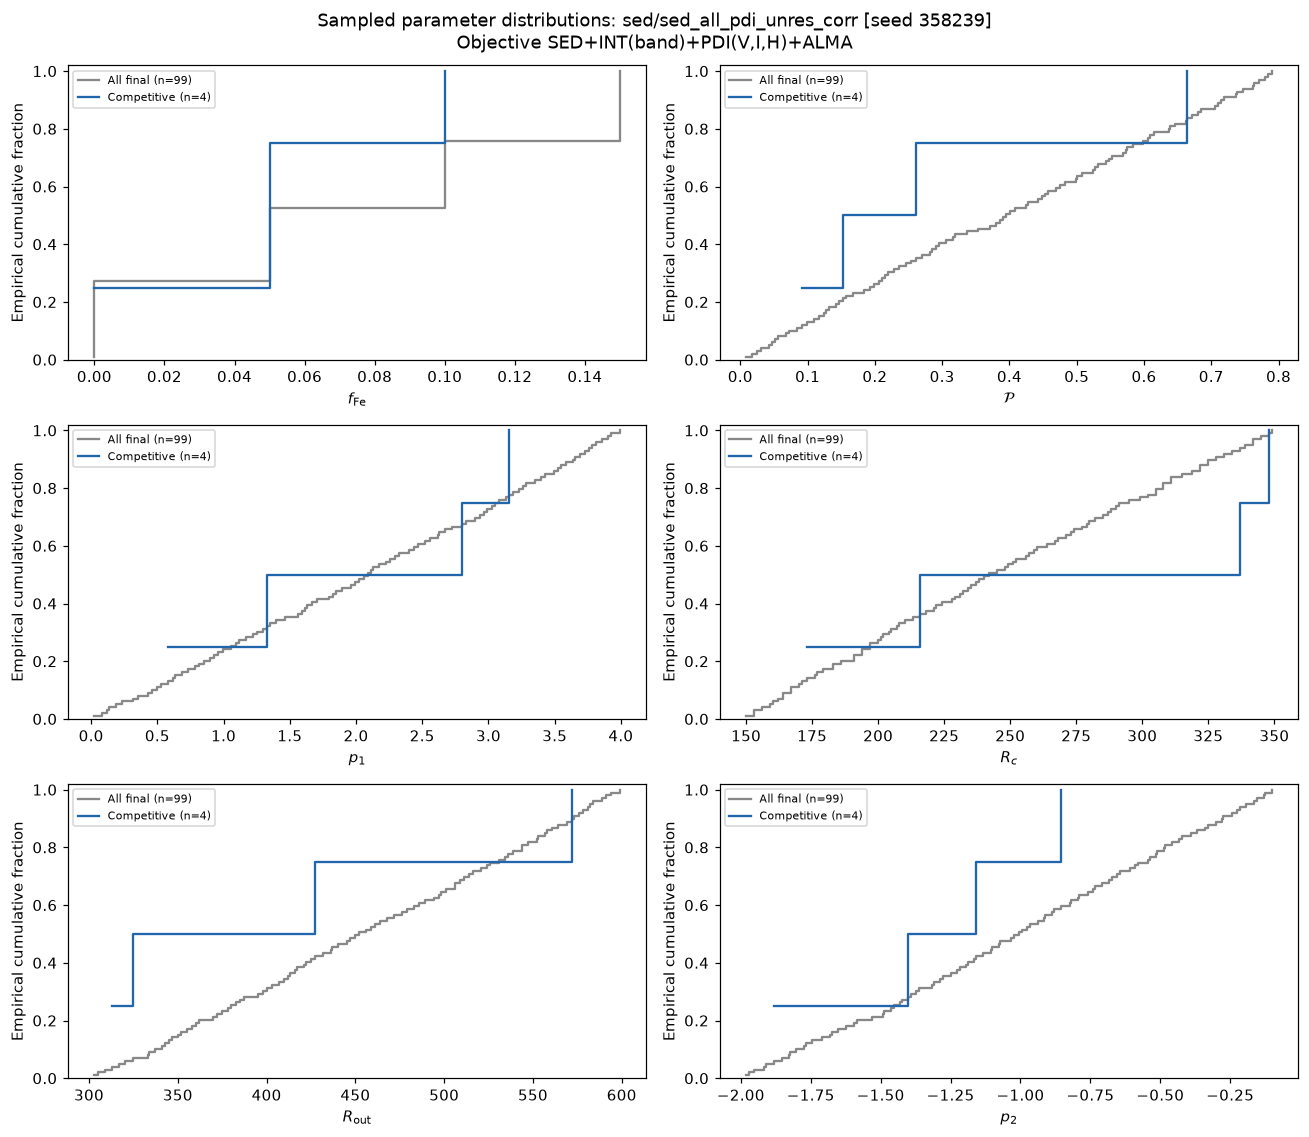

In [40]:
if COMPARISON_MAX_PAIRS < 1 or COMPARISON_PARAMETERS_PER_FIGURE < 1:
    raise ValueError('Comparison plot limits must be positive integers.')
comparison_counts, comparison_parameters, comparison_pairs = competitive_comparison(
    plot_evaluations, plotted_competitive, pair_analysis, PARAMETERS)
display(comparison_counts)
display(comparison_parameters)
comparison_pair_columns = ['history', 'objective_key', 'parameter_x', 'parameter_y',
                          'n_all_final', 'n_competitive', 'both_eligible',
                          'rho_all_final', 'rho_competitive', 'delta_rho', 'sign_flip_rho',
                          'tau_b_all_final', 'tau_b_competitive', 'delta_tau_b', 'sign_flip_tau_b',
                          'reason_all_final', 'reason_competitive', 'direct_configspace_constraint']
display(comparison_pairs.reindex(columns=comparison_pair_columns)
        .loc[comparison_pairs.sort_values('max_abs_delta', ascending=False).index].head(50))
sensitivity_counts, sensitivity_pairs = threshold_sensitivity(
    plot_evaluations, configspaces,
    [*COMPARISON_RELATIVE_ALLOWANCES, RELATIVE_COST_ALLOWANCE], ABSOLUTE_COST_ALLOWANCE,
    min_models=PAIR_MIN_MODELS, min_unique=PAIR_MIN_UNIQUE_VALUES,
    periodic_parameters=PAIR_PERIODIC_PARAMETERS)
display(sensitivity_counts)
comparison_selected_groups = []
for group_index, ((history, objective), group) in enumerate(
        comparison_pairs.groupby(['history', 'objective_key'], sort=False), start=1):
    eligible = group.loc[group.both_eligible].copy()
    if not PAIR_INCLUDE_CONSTRAINED:
        eligible = eligible.loc[~eligible.direct_configspace_constraint]
    chosen = eligible.sort_values(['max_abs_delta', 'parameter_x', 'parameter_y'],
                                 ascending=[False, True, True]).head(COMPARISON_MAX_PAIRS).copy()
    chosen['selection_scope'] = 'competitive'
    chosen['selection_metric'] = 'largest_change_in_either_rank_coefficient'
    comparison_selected_groups.append(chosen)
    if chosen.empty:
        print(f'{history}: no eligible pairs for comparison plots; inspect sample counts and reasons.')
    for first in range(0, len(chosen), PAIR_PANELS_PER_FIGURE):
        page = chosen.iloc[first:first+PAIR_PANELS_PER_FIGURE]
        suffix = f'{group_index:02d}_{first//PAIR_PANELS_PER_FIGURE+1:02d}'
        show_figure('competitive_comparison_pairs_'+suffix,
                    plot_selected_parameter_pairs(page, plot_evaluations, plotted_competitive, LOG_PARAMETERS))
        show_figure('competitive_threshold_sensitivity_'+suffix,
                    plot_threshold_sensitivity(page, sensitivity_pairs))
# Parameter plots also work when no pair is eligible.
for group_index, ((history, objective), group) in enumerate(
        comparison_parameters.groupby(['history', 'objective_key'], sort=False), start=1):
    names = group.loc[group.n_all_final.gt(0), 'parameter'].tolist()
    for first in range(0, len(names), COMPARISON_PARAMETERS_PER_FIGURE):
        page = names[first:first+COMPARISON_PARAMETERS_PER_FIGURE]
        show_figure(f'competitive_parameter_ecdf_{group_index:02d}_{first//COMPARISON_PARAMETERS_PER_FIGURE+1:02d}',
                    plot_parameter_distributions(plot_evaluations, plotted_competitive, history, objective,
                                                 page, LOG_PARAMETERS))
comparison_selected_pairs = (pd.concat(comparison_selected_groups, ignore_index=True)
                             if comparison_selected_groups else comparison_pairs.iloc[:0].copy())


## 6. PDI correction state and prediction amplitudes

Read the correction flag actually saved with each PDI evaluation. A corrected diagnostic image does not establish that corrected images entered the loss. `None` means the historical record does not establish the correction state.

The polarised-light fraction, normalised radial shape and quadrant terms carry different information. SSIM is a morphology diagnostic, not an amplitude test or an objective contribution in the current code. The tables below retain fractions as fractions; multiply by 100 for percent.

,history,budget,pdi_V_corrected,pdi_I_corrected,pdi_H_corrected,pdi_V_correction_radius_px,pdi_I_correction_radius_px,pdi_H_correction_radius_px
1000,sed/sed_all_pdi_unres_corr [seed 358239],1.0,True,True,True,3.0,3.0,3.0


,evaluation_id,history,band,observed_fraction,model_fraction,model_over_observed,corrected,correction_radius_px,fraction_loss,radial_loss,quadrant_loss,band_loss,ssim_diagnostic
0,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],I,0.008366,4.367063e-05,0.005220,True,3.0,6.926671,23.679303,401.919448,432.525423,0.728527
1,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],V,0.006047,1.969267e-05,0.003257,True,3.0,3.632806,20.120898,65.668494,89.422199,0.758691
2,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],H,0.005598,4.178674e-07,0.000075,True,3.0,3.133320,30.005233,53.657123,86.795675,-0.369538


,evaluation_id,history,observed_flux_jy,model_flux_jy,model_to_observed_flux,residual_energy_loss,aperture_radius_mas
0,sed/sed_alma [seed 769887]/row_461,sed/sed_alma [seed 769887],0.288207,0.291137,1.010167,19.269077,203.676503
1,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],0.288207,0.806641,2.798829,67.135128,203.676503


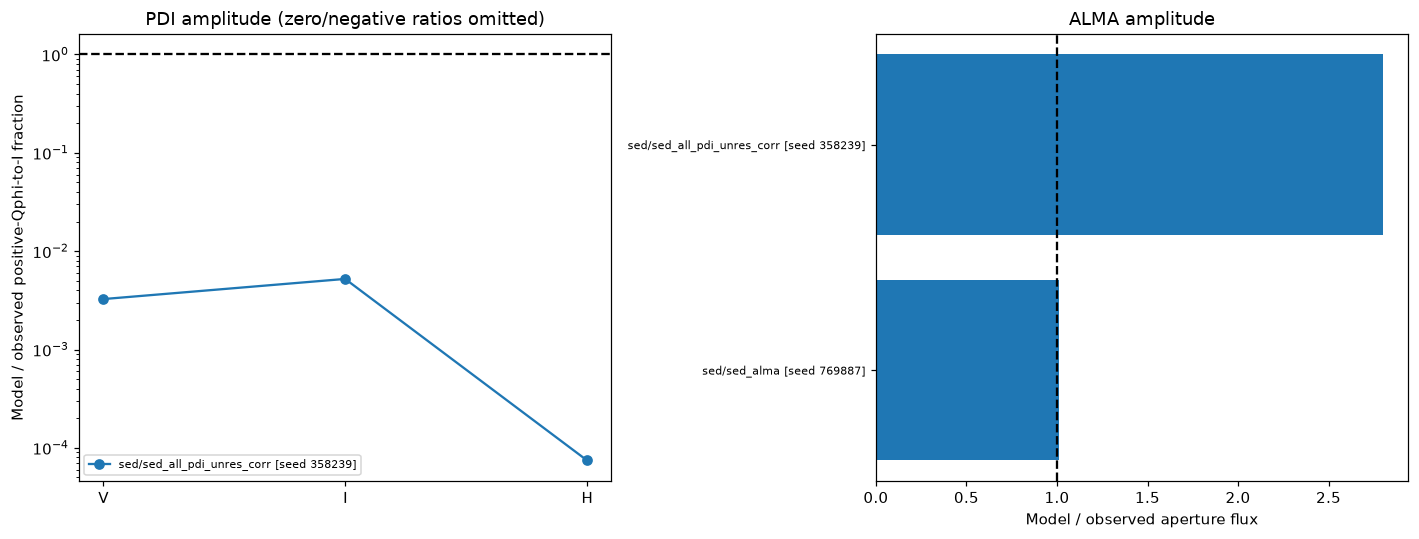

In [41]:
correction_columns = ['history', 'budget', *[f'pdi_{b}_corrected' for b in 'VIH'],
                      *[f'pdi_{b}_correction_radius_px' for b in 'VIH']]
pdi_evaluations = evaluations.loc[evaluations.usable & evaluations[PDI].notna().any(axis=1)]
if not pdi_evaluations.empty:
    correction_audit = pdi_evaluations[correction_columns].drop_duplicates()
    display(correction_audit)
else:
    correction_audit = pd.DataFrame()
    print('No saved PDI scores in these histories.')
pdi_predictions, alma_predictions = prediction_tables(plotted_best, records)
display(pdi_predictions)
display(alma_predictions)
show_figure('prediction_amplitudes', plot_amplitudes(pdi_predictions, alma_predictions))

## 7. Saved radial predictions

Solid curves are models and dashed curves are their associated observations. PDI profiles are normalised annular contributions, not surface brightness or independent amplitude measurements. ALMA profiles retain Jy/beam. Different apertures or radial binning must be considered before interpreting differences.

Only data already stored in `additional_info` are used. SED and visibility point predictions are generally not stored there; their original comparison figures can be viewed in the optional gallery below.

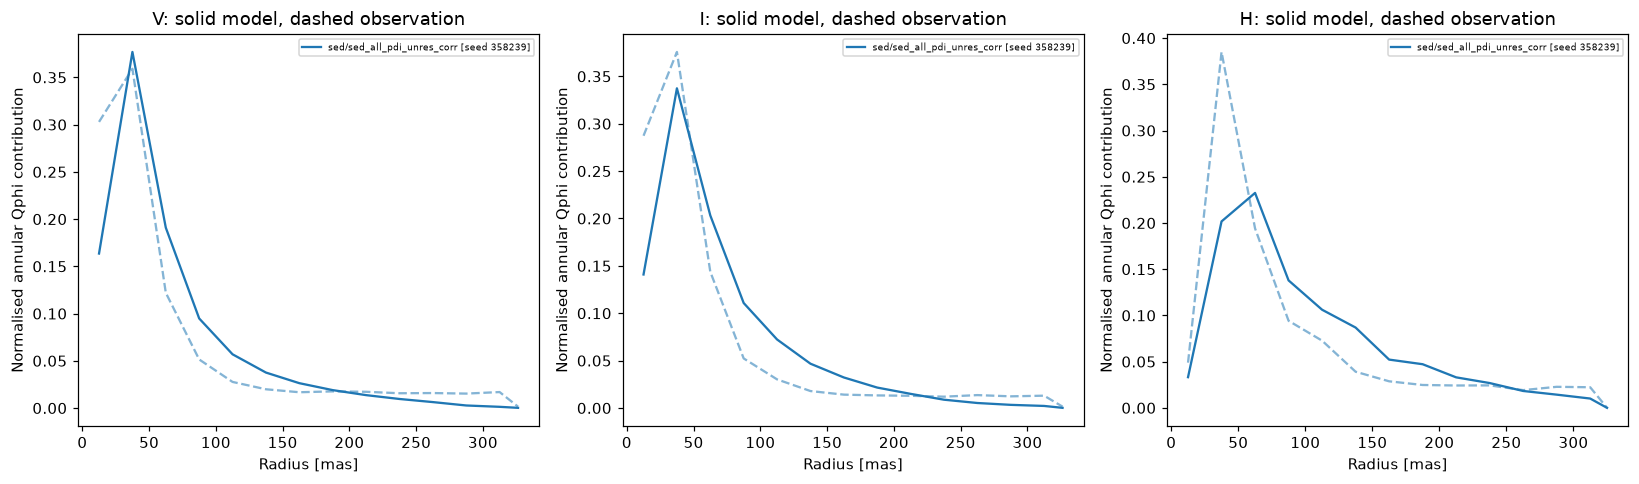

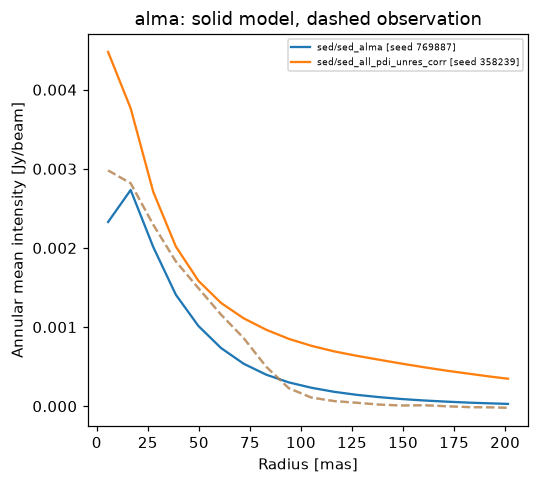

In [42]:
profile_selection = plotted_best.head(PROFILE_MAX_MODELS)
show_figure('pdi_radial_profiles', plot_saved_profiles(profile_selection, records, 'pdi'))
show_figure('alma_radial_profiles', plot_saved_profiles(profile_selection, records, 'alma'))

## 9. Add observations using a common model pool

Compare models that already have every recognised observation contribution. The pool is partitioned using known ConfigSpace/template fingerprints, observation descriptors, PDI correction state and inferred PDI term weights. Missing metadata or unknown historical code/data revisions still limit comparability. Inspect inventory and scoring definitions before drawing physical conclusions across folders.

Subset objectives are reconstructed from the **unchanged recorded contributions**. The same candidates are evaluated for each subset, separating observational preference from differences in search coverage. Missing observables are never assigned zero. Leave-one-group-out comparisons show which observations drive the selected compromise.

Exact copied evaluations are deduplicated within a compatible pool. Distinct stochastic scores remain, so winning evaluations are still subject to simulation noise.
Recorded numerical fidelity settings also partition pools. Missing historical photon/resolution metadata still prevents establishing numerical equivalence. Pool membership requires complete, matching cost bookkeeping.


,evaluations,models,histories
pool_group,,,
53b5191ef936,99,99,1


Displaying compatibility group: 53b5191ef936


,pool_group,objective,models,evaluations,evaluation_id,history,config_id,budget,subset_score,all_observation_score
0,53b5191ef936,SED,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_53,sed/sed_all_pdi_unres_corr [seed 358239],54,1.0,29.426881,46516.448326
1,53b5191ef936,SED+ALMA,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_53,sed/sed_all_pdi_unres_corr [seed 358239],54,1.0,48.212547,46516.448326
2,53b5191ef936,SED+interferometry,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_66,sed/sed_all_pdi_unres_corr [seed 358239],67,1.0,261.409114,64061.026775
3,53b5191ef936,SED+PDI,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_58,sed/sed_all_pdi_unres_corr [seed 358239],59,1.0,348.958493,47251.914332
4,53b5191ef936,All,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],62,1.0,2594.729040,2594.729040
5,53b5191ef936,All minus ALMA,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],62,1.0,2527.593912,2594.729040
6,53b5191ef936,All minus PDI,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_66,sed/sed_all_pdi_unres_corr [seed 358239],67,1.0,283.697661,64061.026775
7,53b5191ef936,All minus interferometry,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_58,sed/sed_all_pdi_unres_corr [seed 358239],59,1.0,408.641272,47251.914332
8,53b5191ef936,All minus SED,99,99,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,sed/sed_all_pdi_unres_corr [seed 358239],62,1.0,1355.000030,2594.729040


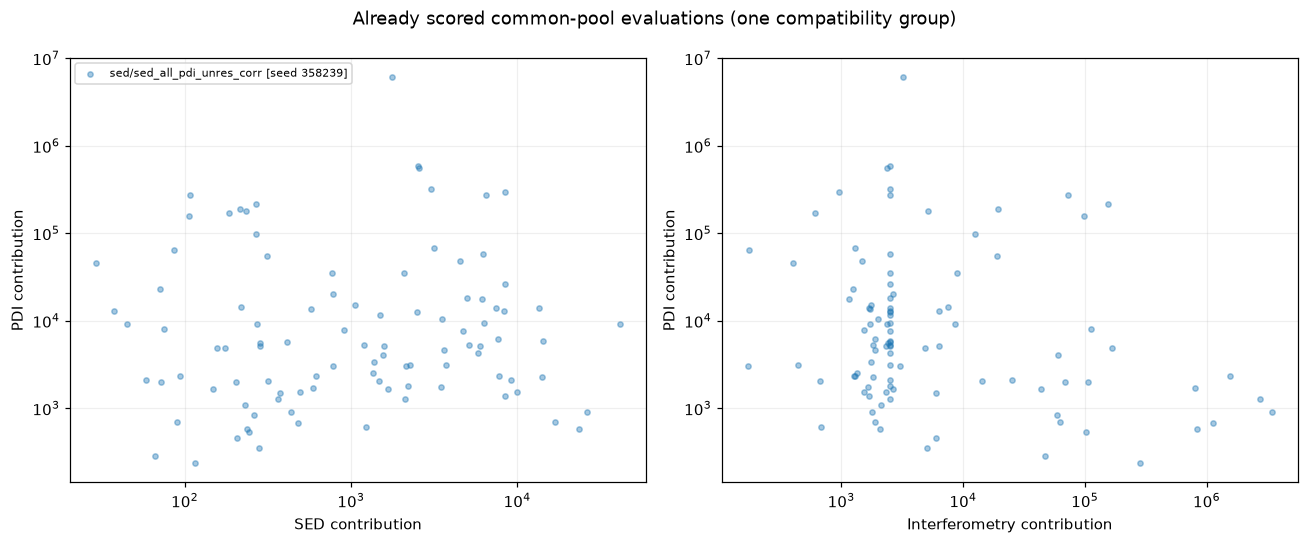

In [43]:
common_pool, subset_winners = common_pool_comparison(evaluations)
if common_pool.empty:
    print('No compatible pool with every observation contribution; this is expected for SED-only selections.')
    pool_groups = pd.DataFrame()
    selected_pool = common_pool
    selected_subset_winners = subset_winners
else:
    pool_groups = common_pool.groupby('pool_group').agg(
        evaluations=('evaluation_id', 'size'), models=('parameter_hash', 'nunique'), histories=('history', 'nunique'))
    display(pool_groups)
    selected_group = POOL_GROUP or pool_groups.evaluations.idxmax()
    print('Displaying compatibility group:', selected_group)
    selected_pool = common_pool[common_pool.pool_group == selected_group].copy()
    selected_subset_winners = subset_winners[subset_winners.pool_group == selected_group]
    display(selected_subset_winners)
    show_figure('common_pool_tradeoffs', plot_tradeoffs(selected_pool))

In [44]:
observation_changes = pd.DataFrame()
if not selected_pool.empty:
    changes = []
    for old_name, new_name in zip(OBSERVATION_SEQUENCE, OBSERVATION_SEQUENCE[1:]):
        if old_name not in SUBSETS or new_name not in SUBSETS:
            raise ValueError('Unknown subset in OBSERVATION_SEQUENCE.')
        if not set(SUBSETS[old_name]).issubset(SUBSETS[new_name]):
            raise ValueError('Each observation addition must retain all previous objective terms.')
        old_scores = selected_pool[SUBSETS[old_name]].sum(axis=1)
        new_scores = selected_pool[SUBSETS[new_name]].sum(axis=1)
        old_id, new_id = old_scores.idxmin(), new_scores.idxmin()
        changes.append({'addition': f'{old_name} → {new_name}',
                        'old_model': selected_pool.loc[old_id, 'evaluation_id'],
                        'new_model': selected_pool.loc[new_id, 'evaluation_id'],
                        'old_objective_before': old_scores.loc[old_id],
                        'old_objective_after': old_scores.loc[new_id],
                        'old_objective_degradation': old_scores.loc[new_id]-old_scores.loc[old_id],
                        'new_objective_before': new_scores.loc[old_id],
                        'new_objective_after': new_scores.loc[new_id],
                        'new_objective_improvement': new_scores.loc[old_id]-new_scores.loc[new_id]})
    observation_changes = pd.DataFrame(changes)
    display(observation_changes)
    chosen_ids = selected_subset_winners.evaluation_id.unique()
    common_winner_parameters = selected_pool[selected_pool.evaluation_id.isin(chosen_ids)]
    display(common_winner_parameters[['history', 'config_id', 'cost', *parameter_columns]])

,addition,old_model,new_model,old_objective_before,old_objective_after,old_objective_degradation,new_objective_before,new_objective_after,new_objective_improvement
0,SED → SED+interferometry,sed/sed_all_pdi_unres_corr [seed 358239]/row_53,sed/sed_all_pdi_unres_corr [seed 358239]/row_66,29.426881,86.706389,57.279508,432.755295,261.409114,171.346181
1,SED+interferometry → All,sed/sed_all_pdi_unres_corr [seed 358239]/row_66,sed/sed_all_pdi_unres_corr [seed 358239]/row_61,261.409114,1918.850615,1657.441501,64061.026775,2594.729040,61466.297735


,history,config_id,cost,param__alpha_viscosity,param__disk_Rmid,param__disk_pa,param__disk_total_dust_mass,param__inclination,param__zone_1_Rin,param__zone_1_flaring_exp,param__zone_1_scale_height,param__zone_1_species_1_Vmax,param__zone_1_species_1_aexp,param__zone_1_species_1_amax,param__zone_1_species_1_amin,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_2_Rc,param__zone_2_Rout,param__zone_2_surface_density_exp
1061,sed/sed_all_pdi_unres_corr [seed 358239],62,2594.729040,0.00100,35.516048,154,0.018214,21,6.198870,1.232898,1.160897,0.673947,2.130238,207.242107,0.945431,0.05,0.091596,1.326847,337,427,-1.881059
1053,sed/sed_all_pdi_unres_corr [seed 358239],54,46516.448326,0.00010,30.461606,95,0.008492,50,6.533730,0.831860,2.230073,0.752822,2.927337,2805.171642,0.618634,0.15,0.475742,2.397769,159,506,-0.609452
1058,sed/sed_all_pdi_unres_corr [seed 358239],59,47251.914332,0.00001,17.824723,107,0.000792,5,6.711900,1.940446,0.521100,0.686423,2.656154,715.892817,0.212013,0.15,0.500523,0.494080,179,362,-0.709606
1066,sed/sed_all_pdi_unres_corr [seed 358239],67,64061.026775,0.00010,18.550840,136,0.006256,24,7.173509,0.958607,2.252349,0.854874,2.363749,454.969103,0.048025,0.10,0.408240,2.629853,231,582,-0.590377


## 10. Optional original model/data diagnostic gallery

Enable `SHOW_SAVED_DIAGNOSTICS` to inspect the existing SED, visibility, PDI and ALMA comparison figures for matched models. The gallery prioritises models with the most scored observables, then the lowest recorded cost for display; this is not a ranking across different objectives. Multiple matched folders are equivalent in sampled parameters but may contain different stochastic realisations.

These are original diagnostic figures. Their plotting scales or display normalisations may differ; inspect the amplitude tables and numerical residuals as well.

In [45]:
if SHOW_SAVED_DIAGNOSTICS:
    gallery = plotted_best.assign(_groups=plotted_best[list(SCORE_COLUMNS.values())].notna().sum(axis=1))
    gallery = gallery.sort_values(['_groups', 'cost'], ascending=[False, True]).head(GALLERY_MAX_MODELS)
    for _, row in gallery.iterrows():
        saved = resolved_models.get(row.evaluation_id)
        if not saved:
            continue
        folder = saved['folder']
        candidates = [folder/'SED_Akke_model1_MCFOST.png', folder/'SED_secondary_comparison.png',
                      folder/'figures/visibilities_GRAVITY 2.2.png',
                      folder/'figures/visibilities_MATISSE L 3.5.png',
                      folder/'figures/pdi_constraints_i.png', folder/'figures/alma_comparison.png']
        available = [p for p in candidates if p.is_file()]
        if not available:
            continue
        fig, axes = plt.subplots(int(np.ceil(len(available)/2)), 2,
                                 figsize=(16, 5*int(np.ceil(len(available)/2))), squeeze=False)
        for ax, path in zip(axes.flat, available):
            ax.imshow(plt.imread(path)); ax.set_title(path.name, fontsize=9); ax.axis('off')
        for ax in axes.flat[len(available):]:
            ax.axis('off')
        fig.suptitle(f'{row.history}; config {row.config_id}')
        fig.tight_layout()
        show_figure('gallery_'+str(row.config_id)+'_'+str(len(figures)), fig)
else:
    print('Gallery disabled. Set SHOW_SAVED_DIAGNOSTICS=True in the settings cell to display saved comparison figures.')

NameError: name 'resolved_models' is not defined

## 11. Export tables, provenance and figures

Set `SAVE_OUTPUTS=True` to export to `OUTPUT_DIR`. Exports do not change the simulation folders. `evaluations.csv` retains exclusions and all repeated evaluations; best/competitive tables select distinct configurations. `history_sha256` identifies the snapshot read, which is useful for active runs.

When interpreting results, report the observation contributions, prediction amplitudes, correction states, physical assumptions, numerical settings and optimiser variability alongside the best cost.

In [ ]:
tables = {
    'competitive_comparison_counts': comparison_counts,
    'competitive_parameter_distributions': comparison_parameters,
    'competitive_pair_comparison': comparison_pairs,
    'competitive_comparison_selected_pairs': comparison_selected_pairs,
    'competitive_threshold_counts': sensitivity_counts,
    'competitive_threshold_pairs': sensitivity_pairs,
    'inventory': inventory, 'coverage': coverage, 'evaluations': evaluations,
    'score_audit': score_audit, 'score_audit_summary': score_audit_summary,
    'score_audit_issues': score_audit_issues,
    'best_models': best, 'competitive_models': competitive,
    'competitive_parameter_ranges': parameter_ranges, 'stage_rank_correlations': rank_correlations,
    'parameter_pair_analysis': pair_analysis, 'selected_parameter_pairs': selected_pairs,
    'pair_correlation_levels': correlation_level_summary, 'pair_plot_index': pair_plot_index,
    'correction_audit': correction_audit, 'pdi_predictions': pdi_predictions,
    'alma_predictions': alma_predictions, 
    'common_pool_subset_winners': subset_winners, 'observation_changes': observation_changes,
}
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)
    for name, figure in figures.items():
        figure.savefig(OUTPUT_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    settings = {'run_folders': {k: str(v) for k, v in RUN_FOLDERS.items()},
                'penalty_limit': PENALTY_LIMIT,
                'relative_cost_allowance': RELATIVE_COST_ALLOWANCE,
                'absolute_cost_allowance': ABSOLUTE_COST_ALLOWANCE,
                'observation_sequence': OBSERVATION_SEQUENCE,
                'competitive_comparison': {
                    'relative_allowances': sorted(set([*COMPARISON_RELATIVE_ALLOWANCES, RELATIVE_COST_ALLOWANCE])),
                    'absolute_allowance': ABSOLUTE_COST_ALLOWANCE,
                    'max_pairs': COMPARISON_MAX_PAIRS,
                    'parameters_per_figure': COMPARISON_PARAMETERS_PER_FIGURE},
                'pair_analysis': {'scope': PAIR_SCOPE, 'metrics': list(PAIR_METRICS),
                                  'scatter_selection_metric': 'spearman', 'kendall_variant': 'b',
                                  'min_models': PAIR_MIN_MODELS,
                                  'min_unique_values': PAIR_MIN_UNIQUE_VALUES, 'min_abs_rho': PAIR_MIN_ABS_RHO,
                                  'max_per_history': PAIR_MAX_PER_HISTORY,
                                  'panels_per_figure': PAIR_PANELS_PER_FIGURE,
                                  'strength_thresholds': [0.2, 0.4, 0.6, 0.8],
                                  'periodic_parameters': sorted(PAIR_PERIODIC_PARAMETERS),
                                  'include_constrained': PAIR_INCLUDE_CONSTRAINED},
                'pool_group': None if common_pool.empty else selected_group,
                'interpretation': 'Recorded optimisation evaluations, not posterior samples. No simulations launched.'}
    (OUTPUT_DIR / 'analysis_settings.json').write_text(json.dumps(settings, indent=2))
    print(f'Exported {len(tables)} tables and {len(figures)} figures to {OUTPUT_DIR}')
else:
    print('Export disabled. Tables and figures are available in memory; set SAVE_OUTPUTS=True to save them.')

## Reading the results critically

1. **Inventory and coverage:** each optimiser seed is a separate history. Usability filters execution failures, penalties, missing configurations and non-finite costs; it does not establish that every observational component was recorded correctly. Use the separate score audit for that check.
2. **Best and competitive models:** selection uses the configured final budget and ranks each observation product set separately. Keeping the lowest repeat for each configuration favours favourable noise realisations; these are best observed scores, not estimates of mean performance. With the present relative allowance of 1.0 and positive costs, competitive means cost at most twice the best cost.
3. **Convergence and stage ranks:** a change in the observation set changes the objective. Rank comparisons use only promoted/repeated configurations observed at both budgets and therefore have selection bias. Their agreement does not establish convergence over the full parameter space.
4. **Parameters and correlations:** competitive ranges are sampled ranges, not uncertainty intervals. The current all_final scope includes poor models and optimiser sampling preferences. Strong Spearman/Kendall associations may reflect adaptive proposals, imposed constraints or cost selection; weak associations do not rule out nonlinear degeneracy. Numeric categorical values can also be ranked by this implementation: only interpret their order when physically meaningful. PA is excluded from ordinary rank correlations.
5. **PDI and ALMA predictions:** inspect amplitudes together with morphology. PDI radial profiles are normalised and do not independently establish absolute brightness. Internal PDI weights remain embedded in the saved losses; adding them again would double-count weighting. SSIM is diagnostic only in the current objective.
6. **Model files and physical profiles:** matching parameters and fidelity is safer than matching local configuration IDs, but multiple stochastic realisations may still match. Reconstructed profiles show the input density/scale-height prescription, not the simulated settled density or temperature fields. The first matched folder need not be the exact stochastic evaluation that produced the winning score.
7. **Common-pool observation additions:** every candidate must have all nine finite contributions and pass cost bookkeeping. Known physical, scoring and numerical metadata partition the pool. The largest pool is chosen by default, which can hide other groups; inspect the group table. Unknown historical code/data revisions or missing numerical metadata prevent proving equivalence. This pool need not represent the full physically allowed parameter space, and subset winners are conditional on its original search coverage. No new optimisation or posterior inference is performed.
8. **Exports:** all evaluation rows, audit statuses and provenance are retained. Tables and plots can be saved with SAVE_OUTPUTS; raw observations, uncertainties, weights and simulation outputs are unchanged.

